In [1]:

import sys
from pathlib import Path

print("Python version:", sys.version)
print("Notebook location:", Path.cwd())
print("Python executable:", sys.executable)


Python version: 3.14.4 (tags/v3.14.4:23116f9, Apr  7 2026, 14:10:54) [MSC v.1944 64 bit (AMD64)]
Notebook location: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\notebooks
Python executable: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\.venv\Scripts\python.exe


In [2]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

print("Project folder exists:", PROJECT_DIR.is_dir())
print("Data folder exists:", DATA_DIR.is_dir())
print("Raw folder exists:", RAW_DIR.is_dir())
print("Processed folder exists:", PROCESSED_DIR.is_dir())


Project folder exists: True
Data folder exists: True
Raw folder exists: True
Processed folder exists: True


In [4]:

import requests

url = "https://archive-api.open-meteo.com/v1/archive"

try:
    response = requests.get(
        url,
        params={
            "latitude": 30.9010,
            "longitude": 75.8573,
            "start_date": "2025-01-01",
            "end_date": "2025-01-03",
            "daily": "rain_sum",
            "timezone": "Asia/Kolkata"
        },
        timeout=(15, 60)
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()
    print("Connection successful!")
    print(response.json())

except requests.exceptions.Timeout:
    print("The server connection timed out. Please retry.")
except requests.exceptions.ConnectionError as e:
    print("Could not connect to the server.")
    print("Details:", e)
except requests.exceptions.RequestException as e:
    print("Request failed:", e)


The server connection timed out. Please retry.


In [5]:

import requests

test_url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

test_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-01-01",
    "end_date": "2025-01-03",
    "hourly": "temperature_2m,precipitation",
    "timezone": "Asia/Kolkata"
}

try:
    response = requests.get(
        test_url,
        params=test_params,
        timeout=(15, 45)
    )
    print("HTTP status:", response.status_code)
    response.raise_for_status()

    test_data = response.json()
    print("SUCCESS: Historical forecast API is reachable.")
    print("Available fields:", list(test_data.get("hourly", {}).keys()))

except requests.exceptions.Timeout:
    print("TIMEOUT: This endpoint also timed out.")
except requests.exceptions.ConnectionError as error:
    print("CONNECTION ERROR:", error)
except requests.exceptions.RequestException as error:
    print("REQUEST ERROR:", error)


HTTP status: 200
SUCCESS: Historical forecast API is reachable.
Available fields: ['time', 'temperature_2m', 'precipitation']


In [6]:

import requests
import pandas as pd
from pathlib import Path

# Project folders
PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Historical forecast API
url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2022-01-01",
    "end_date": "2025-12-31",
    "hourly": "temperature_2m,precipitation",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=(15, 120))
response.raise_for_status()

data = response.json()

# Convert hourly API data into a table
df = pd.DataFrame(data["hourly"])

# Save the raw dataset
file_path = RAW_DIR / "ludhiana_historical_forecast.csv"
df.to_csv(file_path, index=False)

print("SUCCESS! Dataset downloaded.")
print("Rows and columns:", df.shape)
print("Columns:", list(df.columns))
print("First five rows:")
display(df.head())
print("Saved to:", file_path)


SUCCESS! Dataset downloaded.
Rows and columns: (35064, 3)
Columns: ['time', 'temperature_2m', 'precipitation']
First five rows:


,time,temperature_2m,precipitation
0,2022-01-01T00:00,7.6,0.0
1,2022-01-01T01:00,6.5,0.0
2,2022-01-01T02:00,6.0,0.0
3,2022-01-01T03:00,5.5,0.0
4,2022-01-01T04:00,5.8,0.0


Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_historical_forecast.csv


In [7]:

import requests
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2022-01-01",
    "end_date": "2025-12-31",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "dew_point_2m,"
        "apparent_temperature,"
        "precipitation,"
        "rain,"
        "pressure_msl,"
        "cloud_cover,"
        "wind_speed_10m,"
        "wind_direction_10m,"
        "wind_gusts_10m"
    ),
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=(15, 120))
response.raise_for_status()

data = response.json()
df = pd.DataFrame(data["hourly"])

file_path = RAW_DIR / "ludhiana_weather_features_hourly.csv"
df.to_csv(file_path, index=False)

print("SUCCESS! Expanded weather dataset downloaded.")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nMissing values per column:")
print(df.isna().sum())
print("\nFirst five rows:")
display(df.head())
print("\nSaved to:", file_path)


SUCCESS! Expanded weather dataset downloaded.
Dataset shape: (35064, 12)

Columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature', 'precipitation', 'rain', 'pressure_msl', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m']

Missing values per column:
time                    0
temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
apparent_temperature    0
precipitation           0
rain                    0
pressure_msl            0
cloud_cover             0
wind_speed_10m          0
wind_direction_10m      0
wind_gusts_10m          0
dtype: int64

First five rows:


,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m
0,2022-01-01T00:00,7.6,92,6.4,5.6,0.0,0.0,1022.8,90,7.6,315,9.7
1,2022-01-01T01:00,6.5,96,5.8,4.1,0.0,0.0,1022.6,0,8.7,287,10.1
2,2022-01-01T02:00,6.0,96,5.4,3.5,0.0,0.0,1022.5,0,9.1,288,11.2
3,2022-01-01T03:00,5.5,98,5.2,2.9,0.0,0.0,1022.1,2,9.8,294,11.5
4,2022-01-01T04:00,5.8,98,5.4,3.4,0.0,0.0,1021.8,21,8.5,282,11.5



Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_weather_features_hourly.csv


In [8]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load the expanded hourly dataset
hourly_path = RAW_DIR / "ludhiana_weather_features_hourly.csv"
hourly_df = pd.read_csv(hourly_path)

# Convert timestamps to real datetime values
hourly_df["time"] = pd.to_datetime(hourly_df["time"])
hourly_df = hourly_df.sort_values("time")

# Create a daily date column
hourly_df["date"] = hourly_df["time"].dt.date

# Summarize hourly weather into daily features
daily_df = hourly_df.groupby("date").agg(
    temperature_mean=("temperature_2m", "mean"),
    temperature_max=("temperature_2m", "max"),
    temperature_min=("temperature_2m", "min"),
    humidity_mean=("relative_humidity_2m", "mean"),
    dew_point_mean=("dew_point_2m", "mean"),
    apparent_temperature_max=("apparent_temperature", "max"),
    precipitation_sum=("precipitation", "sum"),
    rain_sum=("rain", "sum"),
    pressure_mean=("pressure_msl", "mean"),
    cloud_cover_mean=("cloud_cover", "mean"),
    wind_speed_mean=("wind_speed_10m", "mean"),
    wind_speed_max=("wind_speed_10m", "max"),
    wind_gusts_max=("wind_gusts_10m", "max")
).reset_index()

# Add calendar features
daily_df["date"] = pd.to_datetime(daily_df["date"])
daily_df["month"] = daily_df["date"].dt.month
daily_df["day_of_week"] = daily_df["date"].dt.dayofweek
daily_df["day_of_year"] = daily_df["date"].dt.dayofyear

# Save the daily dataset
output_path = PROCESSED_DIR / "ludhiana_daily_weather.csv"
daily_df.to_csv(output_path, index=False)

print("SUCCESS! Hourly data converted to daily data.")
print("Daily dataset shape:", daily_df.shape)
print("Date range:", daily_df["date"].min(), "to", daily_df["date"].max())
print("Missing values:", daily_df.isna().sum().sum())
print("\nFirst five daily records:")
display(daily_df.head())
print("\nSaved to:", output_path)


SUCCESS! Hourly data converted to daily data.
Daily dataset shape: (1461, 17)
Date range: 2022-01-01 00:00:00 to 2025-12-31 00:00:00
Missing values: 0

First five daily records:


,date,temperature_mean,temperature_max,temperature_min,humidity_mean,dew_point_mean,apparent_temperature_max,precipitation_sum,rain_sum,pressure_mean,cloud_cover_mean,wind_speed_mean,wind_speed_max,wind_gusts_max,month,day_of_week,day_of_year
0,2022-01-01,10.125000,17.7,5.3,84.041667,7.175000,15.6,0.0,0.0,1022.170833,59.208333,6.791667,9.9,20.9,1,5,1
1,2022-01-02,10.758333,18.0,5.3,81.833333,7.391667,16.3,0.0,0.0,1020.812500,90.250000,7.391667,10.2,19.4,1,6,2
2,2022-01-03,12.045833,19.6,6.4,76.916667,7.654167,17.3,0.0,0.0,1018.716667,96.333333,7.054167,10.6,22.0,1,0,3
3,2022-01-04,12.558333,14.7,9.9,84.791667,10.020833,14.6,1.0,1.0,1018.150000,98.750000,5.808333,8.3,14.8,1,1,4
4,2022-01-05,12.391667,13.9,10.4,93.625000,11.400000,13.4,24.3,24.3,1016.308333,100.000000,6.008333,10.4,20.5,1,2,5



Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_daily_weather.csv


In [9]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Load the daily dataset
input_path = PROCESSED_DIR / "ludhiana_daily_weather.csv"
daily_df = pd.read_csv(input_path, parse_dates=["date"])

# Ensure chronological order
daily_df = daily_df.sort_values("date").reset_index(drop=True)

# Create tomorrow's rainfall target
daily_df["tomorrow_rainfall_mm"] = daily_df["rain_sum"].shift(-1)

# Remove the last row because tomorrow's actual rainfall is not available
model_df = daily_df.dropna(subset=["tomorrow_rainfall_mm"]).copy()

# Save the dataset ready for model preparation
output_path = PROCESSED_DIR / "ludhiana_rainfall_target.csv"
model_df.to_csv(output_path, index=False)

print("SUCCESS! Tomorrow's rainfall target created.")
print("Original daily records:", len(daily_df))
print("Records ready for modelling:", len(model_df))
print("Missing target values:", model_df["tomorrow_rainfall_mm"].isna().sum())

print("\nCheck the target alignment:")
display(
    model_df[["date", "rain_sum", "tomorrow_rainfall_mm"]].head(7)
)

print("\nSaved to:", output_path)


SUCCESS! Tomorrow's rainfall target created.
Original daily records: 1461
Records ready for modelling: 1460
Missing target values: 0

Check the target alignment:


,date,rain_sum,tomorrow_rainfall_mm
0,2022-01-01,0.0,0.0
1,2022-01-02,0.0,0.0
2,2022-01-03,0.0,1.0
3,2022-01-04,1.0,24.3
4,2022-01-05,24.3,3.9
5,2022-01-06,3.9,8.2
6,2022-01-07,8.2,59.6



Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_rainfall_target.csv


DATASET SUMMARY
----------------------------------------
Number of records: 1460
Date range: 2022-01-01 to 2025-12-30
Missing values: 0
Minimum tomorrow rainfall (mm): 0.0
Maximum tomorrow rainfall (mm): 75.6
Average tomorrow rainfall (mm): 2.05
Median tomorrow rainfall (mm): 0.0

RAINFALL CATEGORIES
Dry days (0 mm): 945
Light rain (0–2.5 mm): 287
Moderate rain (2.5–10 mm): 136
Heavy rain (10 mm or more): 92


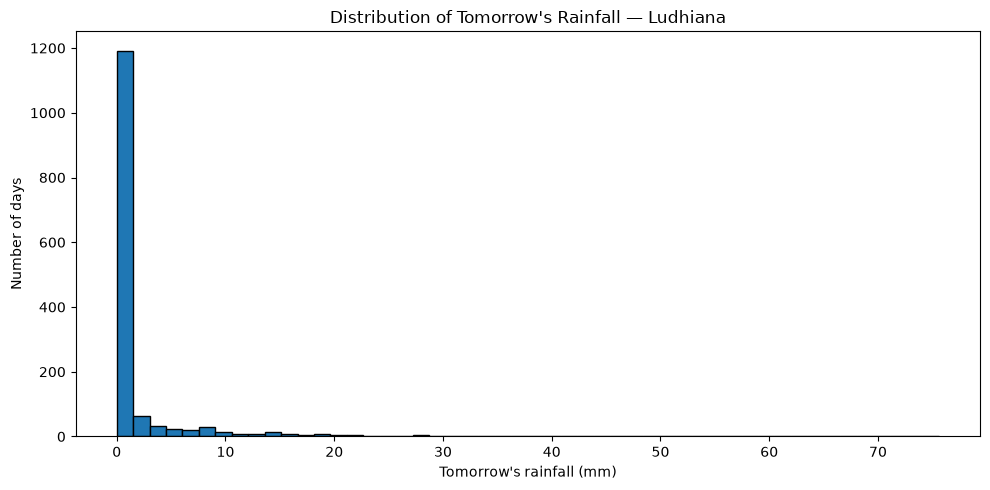

In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
data_path = PROJECT_DIR / "data" / "processed" / "ludhiana_rainfall_target.csv"

df = pd.read_csv(data_path, parse_dates=["date"])
target = df["tomorrow_rainfall_mm"]

print("DATASET SUMMARY")
print("-" * 40)
print("Number of records:", len(df))
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Missing values:", df.isna().sum().sum())
print("Minimum tomorrow rainfall (mm):", target.min())
print("Maximum tomorrow rainfall (mm):", target.max())
print("Average tomorrow rainfall (mm):", round(target.mean(), 2))
print("Median tomorrow rainfall (mm):", round(target.median(), 2))

print("\nRAINFALL CATEGORIES")
print("Dry days (0 mm):", (target == 0).sum())
print("Light rain (0–2.5 mm):", ((target > 0) & (target < 2.5)).sum())
print("Moderate rain (2.5–10 mm):", ((target >= 2.5) & (target < 10)).sum())
print("Heavy rain (10 mm or more):", (target >= 10).sum())

plt.figure(figsize=(10, 5))
plt.hist(target, bins=50, edgecolor="black")
plt.title("Distribution of Tomorrow's Rainfall — Ludhiana")
plt.xlabel("Tomorrow's rainfall (mm)")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()


In [11]:

import requests
from datetime import date, timedelta

url = "https://api.open-meteo.com/v1/forecast"

tomorrow = date.today() + timedelta(days=1)

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "daily": "precipitation_sum,temperature_2m_max,temperature_2m_min",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "dew_point_2m,"
        "precipitation,"
        "rain,"
        "pressure_msl,"
        "cloud_cover,"
        "wind_speed_10m,"
        "wind_gusts_10m"
    ),
    "forecast_days": 2,
    "timezone": "Asia/Kolkata"
}

try:
    response = requests.get(url, params=params, timeout=(15, 45))
    response.raise_for_status()
    forecast_data = response.json()

    print("LIVE FORECAST API SUCCESSFUL")
    print("Forecast dates:", forecast_data["daily"]["time"])
    print("\nDaily forecast:")
    for i, forecast_date in enumerate(forecast_data["daily"]["time"]):
        print(
            forecast_date,
            "| Rainfall:", forecast_data["daily"]["precipitation_sum"][i], "mm",
            "| Max temp:", forecast_data["daily"]["temperature_2m_max"][i], "°C",
            "| Min temp:", forecast_data["daily"]["temperature_2m_min"][i], "°C"
        )

    print("\nHourly fields received:", list(forecast_data["hourly"].keys()))

except requests.exceptions.RequestException as error:
    print("API request failed:", error)


LIVE FORECAST API SUCCESSFUL
Forecast dates: ['2026-10-10', '2026-10-11']

Daily forecast:
2026-10-10 | Rainfall: 0.7 mm | Max temp: 27.4 °C | Min temp: 22.7 °C
2026-10-11 | Rainfall: 0.6 mm | Max temp: 28.4 °C | Min temp: 22.1 °C

Hourly fields received: ['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'pressure_msl', 'cloud_cover', 'wind_speed_10m', 'wind_gusts_10m']


In [12]:

import requests
import pandas as pd

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-01-01",
    "end_date": "2025-01-07",
    "daily": (
        "precipitation_sum,"
        "rain_sum,"
        "temperature_2m_max,"
        "temperature_2m_min,"
        "relative_humidity_2m_mean,"
        "dew_point_2m_mean,"
        "cloud_cover_mean,"
        "wind_speed_10m_max"
    ),
    "timezone": "Asia/Kolkata"
}

try:
    response = requests.get(url, params=params, timeout=(15, 60))
    response.raise_for_status()
    data = response.json()

    if "daily" in data:
        daily_forecast_df = pd.DataFrame(data["daily"])
        print("SUCCESS! Historical daily forecast data received.")
        print("Shape:", daily_forecast_df.shape)
        print("Columns:", daily_forecast_df.columns.tolist())
        display(daily_forecast_df.head())
    else:
        print("The API responded, but no daily data was returned.")
        print(data)

except requests.exceptions.RequestException as error:
    print("Request failed:", error)


SUCCESS! Historical daily forecast data received.
Shape: (7, 9)
Columns: ['time', 'precipitation_sum', 'rain_sum', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'wind_speed_10m_max']


,time,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,wind_speed_10m_max
0,2025-01-01,0.0,0.0,15.2,7.6,93,9.2,88,10.9
1,2025-01-02,0.0,0.0,16.6,8.2,90,9.8,99,12.5
2,2025-01-03,0.0,0.0,18.5,8.2,91,10.4,85,7.9
3,2025-01-04,0.0,0.0,18.8,9.3,90,10.7,71,10.3
4,2025-01-05,5.2,5.2,17.5,10.1,91,11.2,52,12.2


In [13]:

import requests
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2022-01-01",
    "end_date": "2025-12-31",
    "daily": (
        "precipitation_sum,"
        "rain_sum,"
        "temperature_2m_max,"
        "temperature_2m_min,"
        "relative_humidity_2m_mean,"
        "dew_point_2m_mean,"
        "cloud_cover_mean,"
        "wind_speed_10m_max"
    ),
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=(15, 120))
response.raise_for_status()

data = response.json()
forecast_df = pd.DataFrame(data["daily"])

# Standardize the date column
forecast_df = forecast_df.rename(columns={"time": "date"})
forecast_df["date"] = pd.to_datetime(forecast_df["date"])
forecast_df = forecast_df.sort_values("date").reset_index(drop=True)

# Inspect missing values
print("Downloaded historical daily forecast data.")
print("Shape:", forecast_df.shape)
print("Date range:", forecast_df["date"].min(), "to", forecast_df["date"].max())

print("\nMissing values per column:")
print(forecast_df.isna().sum())

# Save without overwriting the earlier datasets
output_path = RAW_DIR / "ludhiana_historical_daily_forecast.csv"
forecast_df.to_csv(output_path, index=False)

print("\nFirst five rows:")
display(forecast_df.head())

print("\nSaved to:", output_path)


Downloaded historical daily forecast data.
Shape: (1461, 9)
Date range: 2022-01-01 00:00:00 to 2025-12-31 00:00:00

Missing values per column:
date                         0
precipitation_sum            0
rain_sum                     0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
dew_point_2m_mean            0
cloud_cover_mean             0
wind_speed_10m_max           0
dtype: int64

First five rows:


,date,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,wind_speed_10m_max
0,2022-01-01,0.0,0.0,17.7,5.3,84,7.2,59,9.9
1,2022-01-02,0.0,0.0,18.0,5.3,82,7.4,90,10.2
2,2022-01-03,0.0,0.0,19.6,6.4,77,7.6,96,10.6
3,2022-01-04,1.0,1.0,14.7,9.9,85,10.0,99,8.3
4,2022-01-05,24.3,24.3,13.9,10.4,94,11.4,100,10.4



Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_historical_daily_forecast.csv


In [14]:

import requests
import pandas as pd

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-03-14",
    "end_date": "2025-03-20",
    "hourly": [
        "temperature_2m_previous_day1",
        "relative_humidity_2m_previous_day1",
        "dew_point_2m_previous_day1",
        "precipitation_previous_day1",
        "rain_previous_day1",
        "cloud_cover_previous_day1",
        "wind_speed_10m_previous_day1"
    ],
    "timezone": "Asia/Kolkata",
    "models": "ecmwf_ifs025"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)

response.raise_for_status()
data = response.json()

print("\nResponse timezone:", data.get("timezone"))
print("\nAvailable response sections:", list(data.keys()))

if "hourly" in data:
    test_df = pd.DataFrame(data["hourly"])
    print("\nDataset shape:", test_df.shape)
    display(test_df.head(10))
    print("\nMissing values:")
    display(test_df.isna().sum())
else:
    print("\nAPI response:")
    print(data)


HTTP status: 200

Response timezone: Asia/Kolkata

Available response sections: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']

Dataset shape: (168, 8)


,time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,rain_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
0,2025-03-14T00:00,16.2,87,14.1,0.0,None,4,0.0
1,2025-03-14T01:00,15.6,89,13.8,0.0,None,10,1.1
2,2025-03-14T02:00,15.0,90,13.4,0.0,None,13,1.8
3,2025-03-14T03:00,14.2,92,12.9,0.0,None,10,1.4
4,2025-03-14T04:00,13.3,93,12.2,0.0,None,4,1.1
5,2025-03-14T05:00,13.1,93,12.0,0.0,None,0,0.8
6,2025-03-14T06:00,13.6,92,12.3,0.0,None,0,0.0
7,2025-03-14T07:00,14.7,89,12.9,0.0,None,0,0.8
8,2025-03-14T08:00,16.5,84,13.8,0.0,None,0,1.3
9,2025-03-14T09:00,19.4,75,14.8,0.0,None,0,0.8



Missing values:


time                                    0
temperature_2m_previous_day1            0
relative_humidity_2m_previous_day1      0
dew_point_2m_previous_day1              0
precipitation_previous_day1             0
rain_previous_day1                    168
cloud_cover_previous_day1               0
wind_speed_10m_previous_day1            0
dtype: int64

In [15]:

import requests
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2022-01-01",
    "end_date": "2025-12-31",
    "hourly": [
        "temperature_2m_previous_day1",
        "relative_humidity_2m_previous_day1",
        "dew_point_2m_previous_day1",
        "precipitation_previous_day1",
        "cloud_cover_previous_day1",
        "wind_speed_10m_previous_day1"
    ],
    "timezone": "Asia/Kolkata",
    "models": "ecmwf_ifs025"
}

response = requests.get(url, params=params, timeout=120)
print("HTTP status:", response.status_code)
response.raise_for_status()

data = response.json()
hourly_df = pd.DataFrame(data["hourly"])

output_path = RAW_DIR / "ludhiana_previous_day1_forecasts_hourly.csv"
hourly_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", hourly_df.shape)
print("\nDate range:", hourly_df["time"].min(), "to", hourly_df["time"].max())
print("\nMissing values:")
display(hourly_df.isna().sum())


HTTP status: 200
Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_previous_day1_forecasts_hourly.csv
Dataset shape: (35064, 7)

Date range: 2022-01-01T00:00 to 2025-12-31T23:00

Missing values:


time                                      0
temperature_2m_previous_day1          18341
relative_humidity_2m_previous_day1    18959
dew_point_2m_previous_day1            18959
precipitation_previous_day1           18339
cloud_cover_previous_day1             18341
wind_speed_10m_previous_day1          18341
dtype: int64

In [16]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

file_path = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "ludhiana_previous_day1_forecasts_hourly.csv"
)

hourly_df = pd.read_csv(file_path, parse_dates=["time"])

feature_cols = [
    col for col in hourly_df.columns
    if col != "time"
]

hourly_df["year"] = hourly_df["time"].dt.year

print("HOURLY COVERAGE BY YEAR")
yearly_coverage = hourly_df.groupby("year")[feature_cols].agg(
    lambda col: col.notna().mean() * 100
)
display(yearly_coverage.round(1))

print("\nROWS WITH ALL SIX FEATURES AVAILABLE")
complete_rows = hourly_df[feature_cols].notna().all(axis=1)
print(f"{complete_rows.sum():,} / {len(hourly_df):,}")
print(f"Coverage: {complete_rows.mean() * 100:.1f}%")

print("\nFIRST AND LAST AVAILABLE FORECAST VALUES")
for col in feature_cols:
    available = hourly_df.loc[hourly_df[col].notna(), "time"]
    if len(available):
        print(
            col,
            "| first:", available.min(),
            "| last:", available.max()
        )
    else:
        print(col, "| no available values")


HOURLY COVERAGE BY YEAR


,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
year,,,,,,
2022,0.0,0.0,0.0,0.0,0.0,0.0
2023,0.0,0.0,0.0,0.0,0.0,0.0
2024,90.7,83.6,83.6,90.7,90.7,90.7
2025,100.0,100.0,100.0,100.0,100.0,100.0



ROWS WITH ALL SIX FEATURES AVAILABLE
16,105 / 35,064
Coverage: 45.9%

FIRST AND LAST AVAILABLE FORECAST VALUES
temperature_2m_previous_day1 | first: 2024-02-04 05:00:00 | last: 2025-12-31 23:00:00
relative_humidity_2m_previous_day1 | first: 2024-02-29 23:00:00 | last: 2025-12-31 23:00:00
dew_point_2m_previous_day1 | first: 2024-02-29 23:00:00 | last: 2025-12-31 23:00:00
precipitation_previous_day1 | first: 2024-02-04 03:00:00 | last: 2025-12-31 23:00:00
cloud_cover_previous_day1 | first: 2024-02-04 05:00:00 | last: 2025-12-31 23:00:00
wind_speed_10m_previous_day1 | first: 2024-02-04 05:00:00 | last: 2025-12-31 23:00:00


In [17]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

file_path = RAW_DIR / "ludhiana_previous_day1_forecasts_hourly.csv"
hourly_df = pd.read_csv(file_path, parse_dates=["time"])

feature_map = {
    "temperature_2m_previous_day1": "temperature_mean_c",
    "relative_humidity_2m_previous_day1": "humidity_mean_pct",
    "dew_point_2m_previous_day1": "dew_point_mean_c",
    "precipitation_previous_day1": "precipitation_sum_mm",
    "cloud_cover_previous_day1": "cloud_cover_mean_pct",
    "wind_speed_10m_previous_day1": "wind_speed_mean_kmh"
}

hourly_df = hourly_df.rename(columns=feature_map)

# Keep only 2025, when all six forecast features are available.
hourly_df = hourly_df[
    hourly_df["time"].dt.year == 2025
].copy()

feature_cols = list(feature_map.values())

print("Missing values before aggregation:")
display(hourly_df[feature_cols].isna().sum())

# Require complete hourly coverage for each day.
hourly_df["date"] = hourly_df["time"].dt.normalize()

daily = hourly_df.groupby("date").agg(
    hours_available=("time", "count"),
    temperature_mean_c=("temperature_mean_c", "mean"),
    humidity_mean_pct=("humidity_mean_pct", "mean"),
    dew_point_mean_c=("dew_point_mean_c", "mean"),
    precipitation_sum_mm=("precipitation_sum_mm", "sum"),
    cloud_cover_mean_pct=("cloud_cover_mean_pct", "mean"),
    wind_speed_mean_kmh=("wind_speed_mean_kmh", "mean")
).reset_index()

daily = daily[daily["hours_available"] == 24].copy()

output_path = PROCESSED_DIR / "ludhiana_2025_day_ahead_forecasts.csv"
daily.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Daily dataset shape:", daily.shape)
print("Date range:", daily["date"].min(), "to", daily["date"].max())
print("\nFirst 5 days:")
display(daily.head())
print("\nMissing values:")
display(daily.isna().sum())


Missing values before aggregation:


temperature_mean_c      0
humidity_mean_pct       0
dew_point_mean_c        0
precipitation_sum_mm    0
cloud_cover_mean_pct    0
wind_speed_mean_kmh     0
dtype: int64


Saved: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_2025_day_ahead_forecasts.csv
Daily dataset shape: (365, 8)
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00

First 5 days:


,date,hours_available,temperature_mean_c,humidity_mean_pct,dew_point_mean_c,precipitation_sum_mm,cloud_cover_mean_pct,wind_speed_mean_kmh
0,2025-01-01,24,10.225000,92.916667,9.037500,0.0,67.750000,7.608333
1,2025-01-02,24,11.370833,89.583333,9.616667,0.0,57.375000,7.820833
2,2025-01-03,24,12.295833,89.583333,10.545833,0.0,62.333333,4.975000
3,2025-01-04,24,12.537500,87.125000,10.287500,0.0,44.000000,2.220833
4,2025-01-05,24,12.850000,88.958333,10.970833,1.2,30.291667,5.041667



Missing values:


date                    0
hours_available         0
temperature_mean_c      0
humidity_mean_pct       0
dew_point_mean_c        0
precipitation_sum_mm    0
cloud_cover_mean_pct    0
wind_speed_mean_kmh     0
dtype: int64

In [18]:

import requests
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "daily": ["precipitation_sum", "rain_sum"],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=120)
print("HTTP status:", response.status_code)
response.raise_for_status()

data = response.json()

observed_df = pd.DataFrame({
    "date": pd.to_datetime(data["daily"]["time"]),
    "observed_precipitation_mm": data["daily"]["precipitation_sum"],
    "observed_rainfall_mm": data["daily"]["rain_sum"]
})

output_path = RAW_DIR / "ludhiana_2025_observed_rainfall.csv"
observed_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", observed_df.shape)
print("Date range:", observed_df["date"].min(), "to", observed_df["date"].max())
print("\nMissing values:")
display(observed_df.isna().sum())
print("\nFirst 5 records:")
display(observed_df.head())
print("\nRainfall summary:")
display(observed_df["observed_rainfall_mm"].describe().round(2))


HTTP status: 200
Saved: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_2025_observed_rainfall.csv
Shape: (365, 3)
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00

Missing values:


date                         0
observed_precipitation_mm    0
observed_rainfall_mm         0
dtype: int64


First 5 records:


,date,observed_precipitation_mm,observed_rainfall_mm
0,2025-01-01,0.0,0.0
1,2025-01-02,0.0,0.0
2,2025-01-03,0.0,0.0
3,2025-01-04,0.0,0.0
4,2025-01-05,5.2,5.2



Rainfall summary:


count    365.00
mean       2.48
std        7.55
min        0.00
25%        0.00
50%        0.00
75%        0.70
max       75.60
Name: observed_rainfall_mm, dtype: float64

In [19]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RAW_DIR = PROJECT_DIR / "data" / "raw"

forecast_path = PROCESSED_DIR / "ludhiana_2025_day_ahead_forecasts.csv"
rainfall_path = RAW_DIR / "ludhiana_2025_observed_rainfall.csv"

forecasts = pd.read_csv(forecast_path, parse_dates=["date"])
rainfall = pd.read_csv(rainfall_path, parse_dates=["date"])

# Match forecast valid dates to the corresponding rainfall dates.
comparison = forecasts.merge(
    rainfall,
    on="date",
    how="inner",
    validate="one_to_one"
)

print("Matched days:", len(comparison))
print("Date range:", comparison["date"].min().date(), "to",
      comparison["date"].max().date())

print("\nMissing values:")
display(comparison.isna().sum())

# Compare forecast precipitation with the reference rainfall series.
actual = comparison["observed_rainfall_mm"]
predicted = comparison["precipitation_sum_mm"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("\nDAILY PRECIPITATION COMPARISON")
print(f"MAE:  {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")

print("\nFirst 10 matched days:")
display(
    comparison[
        [
            "date",
            "precipitation_sum_mm",
            "observed_rainfall_mm",
            "temperature_mean_c",
            "humidity_mean_pct"
        ]
    ].head(10).round(2)
)

output_path = PROCESSED_DIR / "ludhiana_2025_forecast_rainfall_comparison.csv"
comparison.to_csv(output_path, index=False)
print("\nSaved:", output_path)


Matched days: 365
Date range: 2025-01-01 to 2025-12-31

Missing values:


date                         0
hours_available              0
temperature_mean_c           0
humidity_mean_pct            0
dew_point_mean_c             0
precipitation_sum_mm         0
cloud_cover_mean_pct         0
wind_speed_mean_kmh          0
observed_precipitation_mm    0
observed_rainfall_mm         0
dtype: int64


DAILY PRECIPITATION COMPARISON
MAE:  2.514 mm
RMSE: 7.996 mm

First 10 matched days:


C:\Users\balve\AppData\Local\Temp\ipykernel_35940\3922468018.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,date,precipitation_sum_mm,observed_rainfall_mm,temperature_mean_c,humidity_mean_pct
0,2025-01-01,0.0,0.0,10.22,92.92
1,2025-01-02,0.0,0.0,11.37,89.58
2,2025-01-03,0.0,0.0,12.30,89.58
3,2025-01-04,0.0,0.0,12.54,87.12
4,2025-01-05,1.2,5.2,12.85,88.96
5,2025-01-06,2.4,9.0,12.35,91.46
6,2025-01-07,0.0,0.0,10.65,88.67
7,2025-01-08,0.0,0.0,9.46,84.04
8,2025-01-09,0.0,0.0,9.82,89.50
9,2025-01-10,0.0,0.0,9.43,91.88



Saved: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_2025_forecast_rainfall_comparison.csv


In [20]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

comparison_path = (
    PROCESSED_DIR / "ludhiana_2025_forecast_rainfall_comparison.csv"
)

df = pd.read_csv(comparison_path, parse_dates=["date"])

feature_columns = [
    "temperature_mean_c",
    "humidity_mean_pct",
    "dew_point_mean_c",
    "cloud_cover_mean_pct",
    "wind_speed_mean_kmh"
]

target_column = "observed_rainfall_mm"

# Keep only model inputs and the rainfall reference.
training_df = df[["date"] + feature_columns + [target_column]].copy()

# Check data quality.
assert training_df["date"].is_monotonic_increasing
assert training_df["date"].is_unique
assert training_df[feature_columns + [target_column]].notna().all().all()

output_path = PROCESSED_DIR / "ludhiana_2025_ml_training_data.csv"
training_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", training_df.shape)
print("Features:", feature_columns)
print("Target:", target_column)
print("\nDate range:")
print(training_df["date"].min().date(), "to",
      training_df["date"].max().date())

print("\nTarget rainfall summary:")
display(training_df[target_column].describe().round(2))

print("\nFirst 5 rows:")
display(training_df.head())


Saved: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_2025_ml_training_data.csv
Shape: (365, 7)
Features: ['temperature_mean_c', 'humidity_mean_pct', 'dew_point_mean_c', 'cloud_cover_mean_pct', 'wind_speed_mean_kmh']
Target: observed_rainfall_mm

Date range:
2025-01-01 to 2025-12-31

Target rainfall summary:


count    365.00
mean       2.48
std        7.55
min        0.00
25%        0.00
50%        0.00
75%        0.70
max       75.60
Name: observed_rainfall_mm, dtype: float64


First 5 rows:


,date,temperature_mean_c,humidity_mean_pct,dew_point_mean_c,cloud_cover_mean_pct,wind_speed_mean_kmh,observed_rainfall_mm
0,2025-01-01,10.225000,92.916667,9.037500,67.750000,7.608333,0.0
1,2025-01-02,11.370833,89.583333,9.616667,57.375000,7.820833,0.0
2,2025-01-03,12.295833,89.583333,10.545833,62.333333,4.975000,0.0
3,2025-01-04,12.537500,87.125000,10.287500,44.000000,2.220833,0.0
4,2025-01-05,12.850000,88.958333,10.970833,30.291667,5.041667,5.2


In [21]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
file_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "ludhiana_2025_ml_training_data.csv"
)

check_df = pd.read_csv(file_path, parse_dates=["date"])

print("Column names:")
print(check_df.columns.tolist())

print("\nFirst row — values listed by column:")
for column in check_df.columns:
    print(f"{column}: {check_df.loc[0, column]}")

print("\nLast row — values listed by column:")
for column in check_df.columns:
    print(f"{column}: {check_df.loc[len(check_df) - 1, column]}")

print("\nFirst 5 rows, with dates as the index:")
display(check_df.head().set_index("date").T)

print("\nMissing values:")
display(check_df.isna().sum())


Column names:
['date', 'temperature_mean_c', 'humidity_mean_pct', 'dew_point_mean_c', 'cloud_cover_mean_pct', 'wind_speed_mean_kmh', 'observed_rainfall_mm']

First row — values listed by column:
date: 2025-01-01 00:00:00
temperature_mean_c: 10.225
humidity_mean_pct: 92.91666666666669
dew_point_mean_c: 9.0375
cloud_cover_mean_pct: 67.75
wind_speed_mean_kmh: 7.608333333333333
observed_rainfall_mm: 0.0

Last row — values listed by column:
date: 2025-12-31 00:00:00
temperature_mean_c: 10.966666666666669
humidity_mean_pct: 91.04166666666669
dew_point_mean_c: 9.483333333333333
cloud_cover_mean_pct: 86.83333333333333
wind_speed_mean_kmh: 5.379166666666666
observed_rainfall_mm: 0.0

First 5 rows, with dates as the index:


date,2025-01-01,2025-01-02,2025-01-03,2025-01-04,2025-01-05
temperature_mean_c,10.225000,11.370833,12.295833,12.537500,12.850000
humidity_mean_pct,92.916667,89.583333,89.583333,87.125000,88.958333
dew_point_mean_c,9.037500,9.616667,10.545833,10.287500,10.970833
cloud_cover_mean_pct,67.750000,57.375000,62.333333,44.000000,30.291667
wind_speed_mean_kmh,7.608333,7.820833,4.975000,2.220833,5.041667
observed_rainfall_mm,0.000000,0.000000,0.000000,0.000000,5.200000



Missing values:


date                    0
temperature_mean_c      0
humidity_mean_pct       0
dew_point_mean_c        0
cloud_cover_mean_pct    0
wind_speed_mean_kmh     0
observed_rainfall_mm    0
dtype: int64

In [22]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-11-01",
    "end_date": "2025-12-31",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)
response.raise_for_status()

data = response.json()
archive_check = pd.DataFrame(data["daily"])
archive_check["time"] = pd.to_datetime(archive_check["time"])

print("\nDaily data returned:", len(archive_check))
print("\nMonthly totals:")
archive_check["month"] = archive_check["time"].dt.to_period("M")

display(
    archive_check.groupby("month")[
        ["precipitation_sum", "rain_sum"]
    ].agg(["count", "sum", "max"]).round(2)
)

print("\nDays with rainfall greater than zero:")
display(
    archive_check.loc[
        (archive_check["precipitation_sum"] > 0) |
        (archive_check["rain_sum"] > 0)
    ].head(20)
)

HTTP status: 200

Daily data returned: 61

Monthly totals:


precipitation_sum           rain_sum          
                    count  sum  max    count  sum  max
month                                                 
2025-11                30  0.0  0.0       30  0.0  0.0
2025-12                31  0.0  0.0       31  0.0  0.0


Days with rainfall greater than zero:


,time,precipitation_sum,rain_sum,month


In [23]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

forecast_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_day_ahead_forecasts.csv"
)

rain_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_2025_observed_rainfall.csv"
)

forecast = pd.read_csv(forecast_path, parse_dates=["date"])
rain = pd.read_csv(rain_path, parse_dates=["date"])

print("Forecast columns:")
print(forecast.columns.tolist())

print("\nRainfall columns:")
print(rain.columns.tolist())

comparison = forecast.merge(
    rain,
    on="date",
    how="inner",
    validate="one_to_one"
)

december = comparison.loc[
    comparison["date"].between("2025-12-10", "2025-12-31")
].copy()

december["date"] = december["date"].dt.strftime("%Y-%m-%d")

print("\nDecember source-data comparison:")
print(december.to_string(index=False))

Forecast columns:
['date', 'hours_available', 'temperature_mean_c', 'humidity_mean_pct', 'dew_point_mean_c', 'precipitation_sum_mm', 'cloud_cover_mean_pct', 'wind_speed_mean_kmh']

Rainfall columns:
['date', 'observed_precipitation_mm', 'observed_rainfall_mm']

December source-data comparison:
      date  hours_available  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  precipitation_sum_mm  cloud_cover_mean_pct  wind_speed_mean_kmh  observed_precipitation_mm  observed_rainfall_mm
2025-12-10               24           13.366667          75.375000          8.416667                   0.0             37.208333             5.400000                        0.0                   0.0
2025-12-11               24           13.587500          76.833333          8.816667                   0.0              6.458333             4.645833                        0.0                   0.0
2025-12-12               24           14.320833          77.791667          9.895833                   0.0  

In [24]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

PROJECT_DIR = Path.cwd().parent

forecast = pd.read_csv(
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_day_ahead_forecasts.csv",
    parse_dates=["date"]
)

rain = pd.read_csv(
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_2025_observed_rainfall.csv",
    parse_dates=["date"]
)

comparison = forecast.merge(
    rain,
    on="date",
    how="inner",
    validate="one_to_one"
)

print("Matched dates:", len(comparison))
print("Forecast dates:", comparison["date"].nunique())
print("Rainfall dates:", rain["date"].nunique())

print("\nNon-zero daily values:")
print(
    "Forecast precipitation:",
    (comparison["precipitation_sum_mm"] > 0).sum()
)
print(
    "Archive precipitation:",
    (comparison["observed_precipitation_mm"] > 0).sum()
)
print(
    "Archive rainfall:",
    (comparison["observed_rainfall_mm"] > 0).sum()
)

print("\nMonthly totals (mm):")
comparison["month"] = comparison["date"].dt.to_period("M")

monthly = comparison.groupby("month").agg(
    forecast_precipitation_mm=("precipitation_sum_mm", "sum"),
    archive_precipitation_mm=("observed_precipitation_mm", "sum"),
    archive_rainfall_mm=("observed_rainfall_mm", "sum")
)

print(monthly.round(2).to_string())

print("\nFull-year direct precipitation comparison:")
mae = mean_absolute_error(
    comparison["observed_precipitation_mm"],
    comparison["precipitation_sum_mm"]
)
rmse = np.sqrt(mean_squared_error(
    comparison["observed_precipitation_mm"],
    comparison["precipitation_sum_mm"]
))

print("MAE:", round(mae, 3), "mm")
print("RMSE:", round(rmse, 3), "mm")

Matched dates: 365
Forecast dates: 365
Rainfall dates: 365

Non-zero daily values:
Forecast precipitation: 119
Archive precipitation: 138
Archive rainfall: 138

Monthly totals (mm):
         forecast_precipitation_mm  archive_precipitation_mm  archive_rainfall_mm
month                                                                            
2025-01                        6.9                      24.1                 24.1
2025-02                       57.6                      74.0                 74.0
2025-03                        8.1                      15.8                 15.8
2025-04                       13.8                       5.6                  5.6
2025-05                       43.2                      29.7                 29.7
2025-06                      101.7                      94.2                 94.2
2025-07                      247.8                     167.4                167.4
2025-08                      292.8                     315.2                315.

In [25]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

df = pd.read_csv(path, parse_dates=["date"])

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head().to_string(index=False))

print("\nLast 5 rows:")
print(df.tail().to_string(index=False))

print("\nMissing values:")
print(df.isna().sum().to_string())

print("\nRows per year:")
print(df.groupby(df["date"].dt.year).size().to_string())

ValueError: Missing column provided to 'parse_dates': 'date'

In [26]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent

path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

print("File exists:", path.exists())
print("File path:", path)

if path.exists():
    print("\nFirst 10 lines of the original file:")
    with open(path, "r", encoding="utf-8-sig") as file:
        for _ in range(10):
            line = file.readline()
            if not line:
                break
            print(repr(line))

    print("\nColumns detected by pandas:")
    preview = pd.read_csv(path, nrows=5)
    print(preview.columns.tolist())
    display(preview)

File exists: True
File path: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_previous_day1_forecasts_hourly.csv

First 10 lines of the original file:
'time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1\n'
'2022-01-01T00:00,,,,,,\n'
'2022-01-01T01:00,,,,,,\n'
'2022-01-01T02:00,,,,,,\n'
'2022-01-01T03:00,,,,,,\n'
'2022-01-01T04:00,,,,,,\n'
'2022-01-01T05:00,,,,,,\n'
'2022-01-01T06:00,,,,,,\n'
'2022-01-01T07:00,,,,,,\n'
'2022-01-01T08:00,,,,,,\n'

Columns detected by pandas:
['time', 'temperature_2m_previous_day1', 'relative_humidity_2m_previous_day1', 'dew_point_2m_previous_day1', 'precipitation_previous_day1', 'cloud_cover_previous_day1', 'wind_speed_10m_previous_day1']


,time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
0,2022-01-01T00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-01T01:00,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-01T02:00,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-01T03:00,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-01T04:00,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

df = pd.read_csv(path)

# The original timestamp column is called "time"
df["time"] = pd.to_datetime(df["time"])
df = df.rename(columns={"time": "date"})

weather_columns = [
    col for col in df.columns if col != "date"
]

print("Dataset shape:", df.shape)
print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nPercentage of available values by year:")
df["year"] = df["date"].dt.year

coverage = (
    df.groupby("year")[weather_columns]
    .apply(lambda group: group.notna().mean() * 100)
)

display(coverage.round(1))

print("\nPercentage of rows with all weather features available:")
complete_rows = df[weather_columns].notna().all(axis=1)

print(round(complete_rows.mean() * 100, 2), "%")
print("Complete rows:", int(complete_rows.sum()))
print("Total rows:", len(df))

Dataset shape: (35064, 7)

Date range:
2022-01-01 00:00:00 to 2025-12-31 23:00:00

Percentage of available values by year:


,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
year,,,,,,
2022,0.0,0.0,0.0,0.0,0.0,0.0
2023,0.0,0.0,0.0,0.0,0.0,0.0
2024,90.7,83.6,83.6,90.7,90.7,90.7
2025,100.0,100.0,100.0,100.0,100.0,100.0



Percentage of rows with all weather features available:
45.93 %
Complete rows: 16105
Total rows: 35064


In [28]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

df = pd.read_csv(path)
df["time"] = pd.to_datetime(df["time"])

weather_columns = [
    col for col in df.columns if col != "time"
]

# Select 2025 only
df_2025 = df.loc[df["time"].dt.year == 2025].copy()

print("2025 rows:", len(df_2025))
print("Expected hourly rows:", 365 * 24)

print("\nMissing values in 2025:")
print(df_2025[weather_columns].isna().sum().to_string())

print("\nFirst 5 available hourly records:")
display(df_2025.head().round(2))

print("\nLast 5 hourly records:")
display(df_2025.tail().round(2))

2025 rows: 8760
Expected hourly rows: 8760

Missing values in 2025:
temperature_2m_previous_day1          0
relative_humidity_2m_previous_day1    0
dew_point_2m_previous_day1            0
precipitation_previous_day1           0
cloud_cover_previous_day1             0
wind_speed_10m_previous_day1          0

First 5 available hourly records:


C:\Users\balve\AppData\Local\Temp\ipykernel_35940\2586353906.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_2025.head().round(2))


,time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
26304,2025-01-01 00:00:00,7.1,100.0,7.1,0.0,52.0,4.7
26305,2025-01-01 01:00:00,7.2,99.0,7.0,0.0,53.0,5.7
26306,2025-01-01 02:00:00,7.2,99.0,7.1,0.0,55.0,6.4
26307,2025-01-01 03:00:00,7.3,99.0,7.1,0.0,62.0,6.4
26308,2025-01-01 04:00:00,7.3,100.0,7.3,0.0,70.0,5.9



Last 5 hourly records:


C:\Users\balve\AppData\Local\Temp\ipykernel_35940\2586353906.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_2025.tail().round(2))


,time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
35059,2025-12-31 19:00:00,13.4,89.0,11.6,0.1,97.0,8.2
35060,2025-12-31 20:00:00,13.2,89.0,11.4,0.1,88.0,9.5
35061,2025-12-31 21:00:00,12.6,90.0,11.0,0.2,63.0,9.8
35062,2025-12-31 22:00:00,11.8,90.0,10.2,0.2,30.0,9.5
35063,2025-12-31 23:00:00,11.1,91.0,9.7,0.2,8.0,9.5


In [29]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

hourly_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

daily_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_day_ahead_forecasts.csv"
)

hourly = pd.read_csv(hourly_path, parse_dates=["time"])
daily = pd.read_csv(daily_path, parse_dates=["date"])

# Keep 2025 hourly records
hourly_2025 = hourly.loc[
    hourly["time"].dt.year == 2025
].copy()

# Rebuild daily features from hourly data
rebuilt = (
    hourly_2025.assign(date=hourly_2025["time"].dt.normalize())
    .groupby("date")
    .agg(
        hours_available=("time", "count"),
        temperature_mean_c=("temperature_2m_previous_day1", "mean"),
        humidity_mean_pct=("relative_humidity_2m_previous_day1", "mean"),
        dew_point_mean_c=("dew_point_2m_previous_day1", "mean"),
        precipitation_sum_mm=("precipitation_previous_day1", "sum"),
        cloud_cover_mean_pct=("cloud_cover_previous_day1", "mean"),
        wind_speed_mean_kmh=("wind_speed_10m_previous_day1", "mean")
    )
    .reset_index()
)

print("Rebuilt daily rows:", len(rebuilt))
print("Existing daily rows:", len(daily))
print("Days with 24 hourly records:", int((rebuilt["hours_available"] == 24).sum()))

comparison = rebuilt.merge(
    daily,
    on="date",
    how="outer",
    suffixes=("_rebuilt", "_saved"),
    indicator=True
)

print("\nDate matching:")
print(comparison["_merge"].value_counts().to_string())

columns_to_compare = [
    "temperature_mean_c",
    "humidity_mean_pct",
    "dew_point_mean_c",
    "precipitation_sum_mm",
    "cloud_cover_mean_pct",
    "wind_speed_mean_kmh"
]

print("\nMaximum absolute difference for each feature:")
for col in columns_to_compare:
    difference = (
        comparison[f"{col}_rebuilt"] -
        comparison[f"{col}_saved"]
    ).abs()
    print(f"{col}: {difference.max():.6f}")

Rebuilt daily rows: 365
Existing daily rows: 365
Days with 24 hourly records: 365

Date matching:
_merge
both          365
left_only       0
right_only      0

Maximum absolute difference for each feature:
temperature_mean_c: 0.000000
humidity_mean_pct: 0.000000
dew_point_mean_c: 0.000000
precipitation_sum_mm: 0.000000
cloud_cover_mean_pct: 0.000000
wind_speed_mean_kmh: 0.000000


In [30]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = Path.cwd().parent

# Load the same-date comparison dataset
data_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_2025_forecast_rainfall_comparison.csv"
)

comparison = pd.read_csv(data_path, parse_dates=["date"])

print("Dataset shape:", comparison.shape)
print("\nColumn names:")
print(comparison.columns.tolist())

print("\nFirst five rows:")
display(comparison.head())

print("\nDate range:")
print(comparison["date"].min(), "to", comparison["date"].max())

Dataset shape: (365, 10)

Column names:
['date', 'hours_available', 'temperature_mean_c', 'humidity_mean_pct', 'dew_point_mean_c', 'precipitation_sum_mm', 'cloud_cover_mean_pct', 'wind_speed_mean_kmh', 'observed_precipitation_mm', 'observed_rainfall_mm']

First five rows:


,date,hours_available,temperature_mean_c,humidity_mean_pct,dew_point_mean_c,precipitation_sum_mm,cloud_cover_mean_pct,wind_speed_mean_kmh,observed_precipitation_mm,observed_rainfall_mm
0,2025-01-01,24,10.225000,92.916667,9.037500,0.0,67.750000,7.608333,0.0,0.0
1,2025-01-02,24,11.370833,89.583333,9.616667,0.0,57.375000,7.820833,0.0,0.0
2,2025-01-03,24,12.295833,89.583333,10.545833,0.0,62.333333,4.975000,0.0,0.0
3,2025-01-04,24,12.537500,87.125000,10.287500,0.0,44.000000,2.220833,0.0,0.0
4,2025-01-05,24,12.850000,88.958333,10.970833,1.2,30.291667,5.041667,5.2,5.2



Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00


In [31]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
raw_dir = PROJECT_DIR / "data" / "raw"
processed_dir = PROJECT_DIR / "data" / "processed"

files_to_check = [
    raw_dir / "ludhiana_historical_forecast.csv",
    raw_dir / "ludhiana_weather_features_hourly.csv",
    raw_dir / "ludhiana_previous_day1_forecasts_hourly.csv",
    raw_dir / "ludhiana_2025_observed_rainfall.csv",
]

for file_path in files_to_check:
    print("\n" + "=" * 60)
    print("File:", file_path.name)

    if not file_path.exists():
        print("STATUS: File not found")
        continue

    df = pd.read_csv(file_path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    date_col = next(
        (c for c in ["date", "time", "datetime"]
         if c in df.columns),
        None
    )

    if date_col:
        dates = pd.to_datetime(df[date_col], errors="coerce")
        print("Date range:", dates.min(), "to", dates.max())
        print("Year counts:")
        print(dates.dt.year.value_counts().sort_index().to_dict())



File: ludhiana_historical_forecast.csv
Rows: 35064
Columns: ['time', 'temperature_2m', 'precipitation']
Date range: 2022-01-01 00:00:00 to 2025-12-31 23:00:00
Year counts:
{2022: 8760, 2023: 8760, 2024: 8784, 2025: 8760}

File: ludhiana_weather_features_hourly.csv
Rows: 35064
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature', 'precipitation', 'rain', 'pressure_msl', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m']
Date range: 2022-01-01 00:00:00 to 2025-12-31 23:00:00
Year counts:
{2022: 8760, 2023: 8760, 2024: 8784, 2025: 8760}

File: ludhiana_previous_day1_forecasts_hourly.csv
Rows: 35064
Columns: ['time', 'temperature_2m_previous_day1', 'relative_humidity_2m_previous_day1', 'dew_point_2m_previous_day1', 'precipitation_previous_day1', 'cloud_cover_previous_day1', 'wind_speed_10m_previous_day1']
Date range: 2022-01-01 00:00:00 to 2025-12-31 23:00:00
Year counts:
{2022: 8760, 2023: 8760, 2024: 8784, 2025: 8760}



In [33]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

forecast_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

forecast = pd.read_csv(forecast_path, parse_dates=["time"])

forecast_columns = [
    "temperature_2m_previous_day1",
    "relative_humidity_2m_previous_day1",
    "dew_point_2m_previous_day1",
    "precipitation_previous_day1",
    "cloud_cover_previous_day1",
    "wind_speed_10m_previous_day1",
]

forecast["year"] = forecast["time"].dt.year

# Count complete rows separately for each year
yearly_report = (
    forecast.groupby("year")
    .apply(
        lambda group: pd.Series({
            "total_rows": len(group),
            "complete_rows": group[forecast_columns]
                .notna().all(axis=1).sum()
        }),
        include_groups=False
    )
)

print("Forecast feature availability by year:")
display(yearly_report.astype(int))

print("\nMissing percentage for each forecast feature:")
display(
    (forecast[forecast_columns].isna().mean() * 100).round(2)
)


Forecast feature availability by year:


,total_rows,complete_rows
year,,
2022,8760,0
2023,8760,0
2024,8784,7345
2025,8760,8760



Missing percentage for each forecast feature:


temperature_2m_previous_day1          52.31
relative_humidity_2m_previous_day1    54.07
dew_point_2m_previous_day1            54.07
precipitation_previous_day1           52.30
cloud_cover_previous_day1             52.31
wind_speed_10m_previous_day1          52.31
dtype: float64

In [34]:

# Check complete forecast-feature coverage by month

forecast["year_month"] = forecast["time"].dt.to_period("M")

monthly_coverage = (
    forecast.groupby("year_month")
    .apply(
        lambda group: pd.Series({
            "total_hours": len(group),
            "complete_hours": group[forecast_columns]
                .notna().all(axis=1).sum(),
            "coverage_percent": round(
                group[forecast_columns].notna().all(axis=1).mean() * 100,
                2
            )
        }),
        include_groups=False
    )
)

print("Monthly forecast-feature coverage:")
display(monthly_coverage.head(24))

print("\nLast 24 months:")
display(monthly_coverage.tail(24))


Monthly forecast-feature coverage:


,total_hours,complete_hours,coverage_percent
year_month,,,
2022-01,744.0,0.0,0.0
2022-02,672.0,0.0,0.0
2022-03,744.0,0.0,0.0
2022-04,720.0,0.0,0.0
2022-05,744.0,0.0,0.0
2022-06,720.0,0.0,0.0
2022-07,744.0,0.0,0.0
2022-08,744.0,0.0,0.0
2022-09,720.0,0.0,0.0



Last 24 months:


,total_hours,complete_hours,coverage_percent
year_month,,,
2024-01,744.0,0.0,0.00
2024-02,696.0,1.0,0.14
2024-03,744.0,744.0,100.00
2024-04,720.0,720.0,100.00
2024-05,744.0,744.0,100.00
2024-06,720.0,720.0,100.00
2024-07,744.0,744.0,100.00
2024-08,744.0,744.0,100.00
2024-09,720.0,720.0,100.00


In [35]:

import requests
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2022-01-01",
    "end_date": "2025-12-31",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)
response.raise_for_status()

weather = response.json()

rainfall = pd.DataFrame({
    "date": pd.to_datetime(weather["daily"]["time"]),
    "observed_precipitation_mm": weather["daily"]["precipitation_sum"],
    "observed_rainfall_mm": weather["daily"]["rain_sum"]
})

output_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_rainfall_reference_2022_2025.csv"
)

rainfall.to_csv(output_path, index=False)

rainfall["year"] = rainfall["date"].dt.year

yearly_summary = rainfall.groupby("year").agg(
    days=("date", "count"),
    missing_rainfall=("observed_rainfall_mm", lambda x: x.isna().sum()),
    rainy_days=("observed_rainfall_mm", lambda x: (x > 0).sum()),
    total_rainfall_mm=("observed_rainfall_mm", "sum")
).round(2)

print("\nDate range:", rainfall["date"].min(), "to", rainfall["date"].max())
print("Total rows:", len(rainfall))
print("Saved to:", output_path)

display(yearly_summary)


HTTP status: 200

Date range: 2022-01-01 00:00:00 to 2025-12-31 00:00:00
Total rows: 1461
Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_rainfall_reference_2022_2025.csv


,days,missing_rainfall,rainy_days,total_rainfall_mm
year,,,,
2022,365,0,127,872.9
2023,365,0,140,739.9
2024,366,0,116,511.1
2025,365,0,138,904.5


In [36]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

# Load hourly day-ahead forecast features
forecast_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_previous_day1_forecasts_hourly.csv"
)

forecast = pd.read_csv(forecast_path, parse_dates=["time"])

# Convert hourly forecast features into daily features
forecast["date"] = forecast["time"].dt.normalize()

feature_columns = [
    "temperature_2m_previous_day1",
    "relative_humidity_2m_previous_day1",
    "dew_point_2m_previous_day1",
    "precipitation_previous_day1",
    "cloud_cover_previous_day1",
    "wind_speed_10m_previous_day1",
]

daily_forecast = (
    forecast.groupby("date")[feature_columns]
    .mean()
    .reset_index()
)

# Load four-year historical rainfall reference
rainfall_path = (
    PROJECT_DIR / "data" / "raw" /
    "ludhiana_rainfall_reference_2022_2025.csv"
)

rainfall = pd.read_csv(rainfall_path, parse_dates=["date"])

# Match forecasts and rainfall by the same calendar date
dataset = daily_forecast.merge(
    rainfall[["date", "observed_rainfall_mm"]],
    on="date",
    how="inner",
    validate="one_to_one"
)

# Keep only rows with all required inputs and target
dataset = dataset.dropna().sort_values("date").reset_index(drop=True)

# Save the clean dataset
output_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_day_ahead_training_data_2022_2025.csv"
)

dataset.to_csv(output_path, index=False)

print("Dataset shape:", dataset.shape)
print("Date range:", dataset["date"].min(), "to", dataset["date"].max())
print("Saved to:", output_path)

print("\nUsable rows by year:")
display(dataset.groupby(dataset["date"].dt.year).size().rename("usable_days"))

print("\nMissing values:")
display(dataset.isna().sum())

print("\nFirst five rows:")
display(dataset.head())


Dataset shape: (672, 8)
Date range: 2024-02-29 00:00:00 to 2025-12-31 00:00:00
Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_day_ahead_training_data_2022_2025.csv

Usable rows by year:


date
2024    307
2025    365
Name: usable_days, dtype: int64


Missing values:


date                                  0
temperature_2m_previous_day1          0
relative_humidity_2m_previous_day1    0
dew_point_2m_previous_day1            0
precipitation_previous_day1           0
cloud_cover_previous_day1             0
wind_speed_10m_previous_day1          0
observed_rainfall_mm                  0
dtype: int64


First five rows:


,date,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1,observed_rainfall_mm
0,2024-02-29,16.233333,67.000000,7.8000,0.0000,28.500000,8.275000,0.0
1,2024-03-01,16.545833,68.916667,10.7000,0.0625,73.208333,9.633333,1.7
2,2024-03-02,16.895833,82.333333,13.7875,0.8250,47.291667,22.254167,26.3
3,2024-03-03,14.504167,62.000000,5.7000,0.0000,13.000000,10.841667,0.0
4,2024-03-04,11.758333,57.375000,2.9125,0.0000,24.791667,5.783333,0.0


In [37]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

file_path = (
    PROJECT_DIR / "data" / "processed" /
    "ludhiana_day_ahead_training_data_2022_2025.csv"
)

df = pd.read_csv(file_path, parse_dates=["date"])

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum())

print("\nFirst 5 rows:")
display(df.head().to_string(index=False))

print("\nLast 5 rows:")
display(df.tail().to_string(index=False))

print("\nUsable rows by year:")
display(df.groupby(df["date"].dt.year).size())

print("\nDuplicate dates:", df["date"].duplicated().sum())


Shape: (672, 8)

Columns:
['date', 'temperature_2m_previous_day1', 'relative_humidity_2m_previous_day1', 'dew_point_2m_previous_day1', 'precipitation_previous_day1', 'cloud_cover_previous_day1', 'wind_speed_10m_previous_day1', 'observed_rainfall_mm']

Missing values:


date                                  0
temperature_2m_previous_day1          0
relative_humidity_2m_previous_day1    0
dew_point_2m_previous_day1            0
precipitation_previous_day1           0
cloud_cover_previous_day1             0
wind_speed_10m_previous_day1          0
observed_rainfall_mm                  0
dtype: int64


First 5 rows:


'      date  temperature_2m_previous_day1  relative_humidity_2m_previous_day1  dew_point_2m_previous_day1  precipitation_previous_day1  cloud_cover_previous_day1  wind_speed_10m_previous_day1  observed_rainfall_mm\n2024-02-29                     16.233333                           67.000000                      7.8000                       0.0000                  28.500000                      8.275000                   0.0\n2024-03-01                     16.545833                           68.916667                     10.7000                       0.0625                  73.208333                      9.633333                   1.7\n2024-03-02                     16.895833                           82.333333                     13.7875                       0.8250                  47.291667                     22.254167                  26.3\n2024-03-03                     14.504167                           62.000000                      5.7000                       0.0000          


Last 5 rows:


'      date  temperature_2m_previous_day1  relative_humidity_2m_previous_day1  dew_point_2m_previous_day1  precipitation_previous_day1  cloud_cover_previous_day1  wind_speed_10m_previous_day1  observed_rainfall_mm\n2025-12-27                     11.725000                           87.333333                    9.429167                       0.0000                  71.083333                      5.091667                   0.0\n2025-12-28                     11.558333                           87.583333                    9.325000                       0.0000                  73.916667                      4.812500                   0.0\n2025-12-29                     10.750000                           90.750000                    9.120833                       0.0000                  69.791667                      5.904167                   0.0\n2025-12-30                     11.037500                           91.166667                    9.558333                       0.0000          


Usable rows by year:


date
2024    307
2025    365
dtype: int64


Duplicate dates: 0


In [38]:

import requests
from datetime import datetime, timezone

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "hourly": (
        "temperature_2m_previous_day1,"
        "precipitation_previous_day1"
    ),
    "models": "ecmwf_ifs025",
    "start_date": "2025-07-15",
    "end_date": "2025-07-17",
    "timezone": "UTC"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)
response.raise_for_status()

result = response.json()

print("\nAPI response keys:")
print(result.keys())

print("\nModel:")
print(result.get("model"))

print("\nTimezone:")
print(result.get("timezone"))

hourly = result.get("hourly", {})
print("\nFirst 10 timestamps and forecast values:")

for i in range(min(10, len(hourly.get("time", [])))):
    print(
        hourly["time"][i],
        "Temperature:", hourly["temperature_2m_previous_day1"][i],
        "Precipitation:", hourly["precipitation_previous_day1"][i]
    )


HTTP status: 200

API response keys:
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

Model:
None

Timezone:
GMT

First 10 timestamps and forecast values:
2025-07-15T00:00 Temperature: 24.8 Precipitation: 5.0
2025-07-15T01:00 Temperature: 25.6 Precipitation: 0.0
2025-07-15T02:00 Temperature: 27.1 Precipitation: 0.0
2025-07-15T03:00 Temperature: 28.5 Precipitation: 0.0
2025-07-15T04:00 Temperature: 29.7 Precipitation: 0.0
2025-07-15T05:00 Temperature: 30.8 Precipitation: 0.0
2025-07-15T06:00 Temperature: 31.7 Precipitation: 0.0
2025-07-15T07:00 Temperature: 32.4 Precipitation: 0.0
2025-07-15T08:00 Temperature: 32.9 Precipitation: 0.0
2025-07-15T09:00 Temperature: 32.8 Precipitation: 0.0


In [39]:

import pandas as pd

hourly_df = pd.DataFrame({
    "time": pd.to_datetime(result["hourly"]["time"]),
    "temperature_c": result["hourly"]["temperature_2m_previous_day1"],
    "precipitation_mm": result["hourly"]["precipitation_previous_day1"],
})

print("Number of hourly records:", len(hourly_df))
print("First timestamp:", hourly_df["time"].min())
print("Last timestamp:", hourly_df["time"].max())

print("\nHourly precipitation summary:")
display(hourly_df["precipitation_mm"].describe())

print("\nDaily precipitation totals:")
display(
    hourly_df.assign(date=hourly_df["time"].dt.date)
    .groupby("date")
    .agg(
        hours=("precipitation_mm", "size"),
        precipitation_total_mm=("precipitation_mm", "sum"),
        temperature_mean_c=("temperature_c", "mean"),
    )
    .round(2)
)

print("\nAPI URL:")
print(response.url)


Number of hourly records: 72
First timestamp: 2025-07-15 00:00:00
Last timestamp: 2025-07-17 23:00:00

Hourly precipitation summary:


count    72.000000
mean      0.681944
std       1.487727
min       0.000000
25%       0.000000
50%       0.000000
75%       0.300000
max       6.000000
Name: precipitation_mm, dtype: float64


Daily precipitation totals:


,hours,precipitation_total_mm,temperature_mean_c
date,,,
2025-07-15,24,20.9,28.50
2025-07-16,24,13.8,28.15
2025-07-17,24,14.4,27.54



API URL:
https://previous-runs-api.open-meteo.com/v1/forecast?latitude=30.901&longitude=75.8573&hourly=temperature_2m_previous_day1%2Cprecipitation_previous_day1&models=ecmwf_ifs025&start_date=2025-07-15&end_date=2025-07-17&timezone=UTC


In [40]:
# Step: Check hourly forecast data quality

print("Missing values:")
display(hourly_df.isnull().sum())

print("\nDuplicate timestamps:")
print(hourly_df["time"].duplicated().sum())

print("\nHourly precipitation values:")
display(
    hourly_df[
        ["time", "temperature_c", "precipitation_mm"]
    ].head(10)
)

print("\nCheck hours per day:")
daily_check = hourly_df.groupby(
    hourly_df["time"].dt.date
).size()

display(daily_check)

Missing values:


time                0
temperature_c       0
precipitation_mm    0
dtype: int64


Duplicate timestamps:
0

Hourly precipitation values:


,time,temperature_c,precipitation_mm
0,2025-07-15 00:00:00,24.8,5.0
1,2025-07-15 01:00:00,25.6,0.0
2,2025-07-15 02:00:00,27.1,0.0
3,2025-07-15 03:00:00,28.5,0.0
4,2025-07-15 04:00:00,29.7,0.0
5,2025-07-15 05:00:00,30.8,0.0
6,2025-07-15 06:00:00,31.7,0.0
7,2025-07-15 07:00:00,32.4,0.0
8,2025-07-15 08:00:00,32.9,0.0
9,2025-07-15 09:00:00,32.8,0.0



Check hours per day:


time
2025-07-15    24
2025-07-16    24
2025-07-17    24
dtype: int64

In [41]:
# Step: Display the exact dates and forecast values

display(
    hourly_df.groupby(
        hourly_df["time"].dt.date
    ).agg(
        first_temperature=("temperature_c", "first"),
        last_temperature=("temperature_c", "last"),
        first_precipitation=("precipitation_mm", "first"),
        maximum_precipitation=("precipitation_mm", "max"),
        total_precipitation=("precipitation_mm", "sum"),
    ).round(2)
)

print("\nImportant:")
print("These are previous_day1 forecast values.")
print("They are not confirmed observed rainfall measurements.")
print("We must verify forecast issue-time alignment before model training.")

,first_temperature,last_temperature,first_precipitation,maximum_precipitation,total_precipitation
time,,,,,
2025-07-15,24.8,26.2,5.0,5.0,20.9
2025-07-16,26.0,25.3,0.0,6.0,13.8
2025-07-17,25.0,26.0,6.0,6.0,14.4



Important:
These are previous_day1 forecast values.
They are not confirmed observed rainfall measurements.
We must verify forecast issue-time alignment before model training.


In [42]:

import requests
import pandas as pd

url = "https://single-runs-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "run": "2025-07-14T00:00",
    "models": "ecmwf_ifs025",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "dew_point_2m,"
        "precipitation,"
        "precipitation_probability,"
        "cloud_cover,"
        "wind_speed_10m"
    ),
    "timezone": "Asia/Kolkata",
    "forecast_days": 7
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    result_single = response.json()

    print("Response keys:", list(result_single.keys()))
    print("Timezone:", result_single.get("timezone"))

    hourly = result_single.get("hourly", {})
    print("Number of hourly records:", len(hourly.get("time", [])))

    if hourly.get("time"):
        forecast_df = pd.DataFrame(hourly)
        forecast_df["time"] = pd.to_datetime(forecast_df["time"])

        print("\nFirst forecast timestamps:")
        display(forecast_df.head())

        print("\nLast forecast timestamp:")
        print(forecast_df["time"].max())

        print("\nForecast URL:")
        print(response.url)
else:
    print(response.text[:2000])


HTTP status: 400
{"reason":"The requested model run is not available. Model: ecmwf_ifs025, run: 2025-07-14T00:00Z","error":true}


In [43]:

import requests

test_url = "https://single-runs-api.open-meteo.com/v1/forecast"

test_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "run": "2025-07-14T00:00",
    "models": "ecmwf_ifs",
    "hourly": "temperature_2m,precipitation",
    "forecast_days": 3,
    "timezone": "GMT"
}

test_response = requests.get(
    test_url,
    params=test_params,
    timeout=60
)

print("HTTP status:", test_response.status_code)
print("Response:", test_response.text[:1500])


HTTP status: 200
Response: {"latitude":30.896309,"longitude":75.83432,"generationtime_ms":6.293177604675293,"utc_offset_seconds":0,"timezone":"GMT","timezone_abbreviation":"GMT","elevation":252.0,"hourly_units":{"time":"iso8601","temperature_2m":"°C","precipitation":"mm"},"hourly":{"time":["2025-07-14T00:00","2025-07-14T01:00","2025-07-14T02:00","2025-07-14T03:00","2025-07-14T04:00","2025-07-14T05:00","2025-07-14T06:00","2025-07-14T07:00","2025-07-14T08:00","2025-07-14T09:00","2025-07-14T10:00","2025-07-14T11:00","2025-07-14T12:00","2025-07-14T13:00","2025-07-14T14:00","2025-07-14T15:00","2025-07-14T16:00","2025-07-14T17:00","2025-07-14T18:00","2025-07-14T19:00","2025-07-14T20:00","2025-07-14T21:00","2025-07-14T22:00","2025-07-14T23:00","2025-07-15T00:00","2025-07-15T01:00","2025-07-15T02:00","2025-07-15T03:00","2025-07-15T04:00","2025-07-15T05:00","2025-07-15T06:00","2025-07-15T07:00","2025-07-15T08:00","2025-07-15T09:00","2025-07-15T10:00","2025-07-15T11:00","2025-07-15T12:00","2025-

In [44]:

import pandas as pd

# Read the complete API response
run_data = test_response.json()

# Convert hourly forecast into a DataFrame
run_df = pd.DataFrame(run_data["hourly"])
run_df["time"] = pd.to_datetime(run_df["time"])
run_df["date"] = run_df["time"].dt.date

print("Total hourly records:", len(run_df))
print("First timestamp:", run_df["time"].min())
print("Last timestamp:", run_df["time"].max())

print("\nDaily forecast summary:")

daily_run_df = (
    run_df.groupby("date")
    .agg(
        hours=("time", "count"),
        temperature_mean_c=("temperature_2m", "mean"),
        forecast_precipitation_mm=("precipitation", "sum"),
        maximum_hourly_precipitation_mm=("precipitation", "max"),
    )
    .round(2)
)

display(daily_run_df)

print("\nForecast run requested: 2025-07-14 00:00 UTC")
print("Model: ecmwf_ifs")


Total hourly records: 72
First timestamp: 2025-07-14 00:00:00
Last timestamp: 2025-07-16 23:00:00

Daily forecast summary:


,hours,temperature_mean_c,forecast_precipitation_mm,maximum_hourly_precipitation_mm
date,,,,
2025-07-14,24,28.58,6.0,3.2
2025-07-15,24,28.80,15.9,9.6
2025-07-16,24,27.82,24.7,10.2



Forecast run requested: 2025-07-14 00:00 UTC
Model: ecmwf_ifs


In [45]:

import requests
import pandas as pd

archive_url = "https://archive-api.open-meteo.com/v1/archive"

archive_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-14",
    "end_date": "2025-07-16",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "UTC"
}

archive_response = requests.get(
    archive_url,
    params=archive_params,
    timeout=60
)

print("HTTP status:", archive_response.status_code)

if archive_response.status_code == 200:
    archive_data = archive_response.json()

    observed_df = pd.DataFrame({
        "date": pd.to_datetime(archive_data["daily"]["time"]).date,
        "reference_precipitation_mm": archive_data["daily"]["precipitation_sum"],
        "reference_rainfall_mm": archive_data["daily"]["rain_sum"]
    })

    print("\nHistorical rainfall reference:")
    display(observed_df)

    print(
        "\nNote: Open-Meteo archive values are gridded historical "
        "weather estimates, not guaranteed ground-station observations."
    )
else:
    print(archive_response.text[:1500])


HTTP status: 200

Historical rainfall reference:


,date,reference_precipitation_mm,reference_rainfall_mm
0,2025-07-14,1.1,1.1
1,2025-07-15,13.4,13.4
2,2025-07-16,0.8,0.8



Note: Open-Meteo archive values are gridded historical weather estimates, not guaranteed ground-station observations.


In [46]:

# Merge forecasts and historical rainfall by date

forecast_daily = daily_run_df.reset_index().copy()

forecast_daily["date"] = pd.to_datetime(
    forecast_daily["date"]
).dt.date

observed_df["date"] = pd.to_datetime(
    observed_df["date"]
).dt.date

comparison_df = forecast_daily.merge(
    observed_df,
    on="date",
    how="inner",
    validate="one_to_one"
)

comparison_df["absolute_error_mm"] = (
    comparison_df["forecast_precipitation_mm"]
    - comparison_df["reference_precipitation_mm"]
).abs()

print("Comparison dataset shape:", comparison_df.shape)
display(comparison_df)

print("\nMean absolute difference (mm):")
print(round(comparison_df["absolute_error_mm"].mean(), 3))


Comparison dataset shape: (3, 8)


,date,hours,temperature_mean_c,forecast_precipitation_mm,maximum_hourly_precipitation_mm,reference_precipitation_mm,reference_rainfall_mm,absolute_error_mm
0,2025-07-14,24,28.58,6.0,3.2,1.1,1.1,4.9
1,2025-07-15,24,28.80,15.9,9.6,13.4,13.4,2.5
2,2025-07-16,24,27.82,24.7,10.2,0.8,0.8,23.9



Mean absolute difference (mm):
10.433


In [47]:

import requests
import pandas as pd
import numpy as np

# Request one historical forecast run
run_url = "https://single-runs-api.open-meteo.com/v1/forecast"

run_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "run": "2025-07-01T00:00",
    "models": "ecmwf_ifs",
    "hourly": "precipitation",
    "forecast_days": 7,
    "timezone": "GMT"
}

run_response = requests.get(
    run_url,
    params=run_params,
    timeout=60
)

print("Forecast API status:", run_response.status_code)

if run_response.status_code == 200:
    run_json = run_response.json()

    month_forecast = pd.DataFrame({
        "time": pd.to_datetime(run_json["hourly"]["time"]),
        "forecast_precipitation_mm": run_json["hourly"]["precipitation"]
    })

    month_forecast["date"] = month_forecast["time"].dt.date

    daily_forecast = (
        month_forecast.groupby("date")
        .agg(
            hours=("time", "count"),
            forecast_precipitation_mm=(
                "forecast_precipitation_mm", "sum"
            )
        )
        .reset_index()
    )

    print("Forecast dates:", daily_forecast["date"].min(),
          "to", daily_forecast["date"].max())
    display(daily_forecast)

else:
    print(run_response.text[:1500])


Forecast API status: 200
Forecast dates: 2025-07-01 to 2025-07-07


,date,hours,forecast_precipitation_mm
0,2025-07-01,24,2.40
1,2025-07-02,24,0.30
2,2025-07-03,24,1.60
3,2025-07-04,24,6.24
4,2025-07-05,24,3.42
5,2025-07-06,24,9.06
6,2025-07-07,24,1.66


In [48]:

archive_url = "https://archive-api.open-meteo.com/v1/archive"

archive_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-07-07",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "GMT"
}

archive_response = requests.get(
    archive_url,
    params=archive_params,
    timeout=60
)

print("Archive API status:", archive_response.status_code)

if archive_response.status_code == 200:
    archive_json = archive_response.json()

    week_observed = pd.DataFrame({
        "date": pd.to_datetime(archive_json["daily"]["time"]).date,
        "reference_precipitation_mm": (
            archive_json["daily"]["precipitation_sum"]
        ),
        "reference_rainfall_mm": archive_json["daily"]["rain_sum"]
    })

    week_comparison = daily_forecast.merge(
        week_observed,
        on="date",
        how="inner",
        validate="one_to_one"
    )

    week_comparison["absolute_error_mm"] = (
        week_comparison["forecast_precipitation_mm"]
        - week_comparison["reference_precipitation_mm"]
    ).abs()

    print("\nSeven-day comparison:")
    display(week_comparison.round(2))

    print("\nMean absolute difference (mm):")
    print(round(week_comparison["absolute_error_mm"].mean(), 3))

else:
    print(archive_response.text[:1500])


Archive API status: 200

Seven-day comparison:


,date,hours,forecast_precipitation_mm,reference_precipitation_mm,reference_rainfall_mm,absolute_error_mm
0,2025-07-01,24,2.40,2.5,2.5,0.10
1,2025-07-02,24,0.30,0.1,0.1,0.20
2,2025-07-03,24,1.60,0.0,0.0,1.60
3,2025-07-04,24,6.24,9.3,9.3,3.06
4,2025-07-05,24,3.42,15.0,15.0,11.58
5,2025-07-06,24,9.06,11.8,11.8,2.74
6,2025-07-07,24,1.66,1.0,1.0,0.66



Mean absolute difference (mm):
2.849


In [49]:

# Test several historical forecast initialization dates

test_runs = [
    "2025-07-01T00:00",
    "2025-07-08T00:00",
    "2025-07-15T00:00",
    "2025-07-22T00:00",
]

run_check_results = []

for run_time in test_runs:
    params = {
        "latitude": 30.9010,
        "longitude": 75.8573,
        "run": run_time,
        "models": "ecmwf_ifs",
        "hourly": "precipitation",
        "forecast_days": 7,
        "timezone": "GMT",
    }

    try:
        response_check = requests.get(
            "https://single-runs-api.open-meteo.com/v1/forecast",
            params=params,
            timeout=60,
        )

        result_check = {
            "requested_run": run_time,
            "http_status": response_check.status_code,
            "first_forecast_time": None,
            "last_forecast_time": None,
            "hourly_records": 0,
            "error": None,
        }

        if response_check.status_code == 200:
            hourly_times = response_check.json()["hourly"]["time"]
            result_check["hourly_records"] = len(hourly_times)

            if hourly_times:
                result_check["first_forecast_time"] = hourly_times[0]
                result_check["last_forecast_time"] = hourly_times[-1]
        else:
            result_check["error"] = response_check.text[:200]

        run_check_results.append(result_check)

    except requests.RequestException as exc:
        run_check_results.append({
            "requested_run": run_time,
            "http_status": None,
            "first_forecast_time": None,
            "last_forecast_time": None,
            "hourly_records": 0,
            "error": str(exc),
        })

run_check_df = pd.DataFrame(run_check_results)
display(run_check_df)


,requested_run,http_status,first_forecast_time,last_forecast_time,hourly_records,error
0,2025-07-01T00:00,200,2025-07-01T00:00,2025-07-07T23:00,168,None
1,2025-07-08T00:00,200,2025-07-08T00:00,2025-07-14T23:00,168,None
2,2025-07-15T00:00,200,2025-07-15T00:00,2025-07-21T23:00,168,None
3,2025-07-22T00:00,200,2025-07-22T00:00,2025-07-28T23:00,168,None


In [50]:

from pathlib import Path
import requests
import pandas as pd

# Project root: folder containing data/raw
project_root = Path.cwd()

if not (project_root / "data" / "raw").exists():
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

run_dates = [
    "2025-07-01T00:00",
    "2025-07-08T00:00",
    "2025-07-15T00:00",
    "2025-07-22T00:00",
]

all_runs = []

for run_time in run_dates:
    params = {
        "latitude": 30.9010,
        "longitude": 75.8573,
        "run": run_time,
        "models": "ecmwf_ifs",
        "hourly": (
            "temperature_2m,"
            "relative_humidity_2m,"
            "dew_point_2m,"
            "precipitation,"
            "cloud_cover,"
            "wind_speed_10m"
        ),
        "forecast_days": 7,
        "timezone": "GMT",
    }

    r = requests.get(
        "https://single-runs-api.open-meteo.com/v1/forecast",
        params=params,
        timeout=60,
    )
    r.raise_for_status()

    hourly = pd.DataFrame(r.json()["hourly"])
    hourly["valid_time_utc"] = pd.to_datetime(hourly.pop("time"))
    hourly["run_time_utc"] = pd.to_datetime(run_time)

    all_runs.append(hourly)

forecast_runs_df = pd.concat(all_runs, ignore_index=True)

output_file = raw_dir / "ludhiana_july_2025_historical_forecast_runs.csv"
forecast_runs_df.to_csv(output_file, index=False)

print("Saved to:", output_file)
print("Rows:", len(forecast_runs_df))
print("Distinct forecast runs:", forecast_runs_df["run_time_utc"].nunique())
print("Missing values:")
display(forecast_runs_df.isna().sum())

print("\nFirst records:")
display(forecast_runs_df.head())

print("\nRecords per forecast run:")
display(
    forecast_runs_df.groupby("run_time_utc").size().rename("hourly_records")
)


Saved to: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_july_2025_historical_forecast_runs.csv
Rows: 672
Distinct forecast runs: 4
Missing values:


temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           4
cloud_cover             0
wind_speed_10m          0
valid_time_utc          0
run_time_utc            0
dtype: int64


First records:


,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,cloud_cover,wind_speed_10m,valid_time_utc,run_time_utc
0,25.8,95,24.9,NaN,100,6.2,2025-07-01 00:00:00,2025-07-01
1,25.7,95,24.9,0.2,100,12.7,2025-07-01 01:00:00,2025-07-01
2,25.6,95,24.8,1.3,100,10.0,2025-07-01 02:00:00,2025-07-01
3,26.1,95,25.1,0.6,100,9.1,2025-07-01 03:00:00,2025-07-01
4,27.0,88,24.8,0.2,100,17.3,2025-07-01 04:00:00,2025-07-01



Records per forecast run:


run_time_utc
2025-07-01    168
2025-07-08    168
2025-07-15    168
2025-07-22    168
Name: hourly_records, dtype: int64

In [51]:

# Reload the saved CSV and verify its actual columns

saved_forecasts = pd.read_csv(
    output_file,
    parse_dates=["valid_time_utc", "run_time_utc"]
)

print("Dataset shape:", saved_forecasts.shape)

print("\nActual column names:")
print(saved_forecasts.columns.tolist())

print("\nFirst 5 rows:")
display(saved_forecasts.head())

print("\nRows with missing precipitation:")
display(
    saved_forecasts.loc[
        saved_forecasts["precipitation"].isna()
    ]
)

print("\nDuplicate run-time and valid-time pairs:")
print(
    saved_forecasts.duplicated(
        subset=["run_time_utc", "valid_time_utc"]
    ).sum()
)

print("\nValid date coverage per run:")
display(
    saved_forecasts.groupby("run_time_utc").agg(
        first_valid_time=("valid_time_utc", "min"),
        last_valid_time=("valid_time_utc", "max"),
        row_count=("valid_time_utc", "size"),
    )
)


Dataset shape: (672, 8)

Actual column names:
['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m', 'valid_time_utc', 'run_time_utc']

First 5 rows:


,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,cloud_cover,wind_speed_10m,valid_time_utc,run_time_utc
0,25.8,95,24.9,NaN,100,6.2,2025-07-01 00:00:00,2025-07-01
1,25.7,95,24.9,0.2,100,12.7,2025-07-01 01:00:00,2025-07-01
2,25.6,95,24.8,1.3,100,10.0,2025-07-01 02:00:00,2025-07-01
3,26.1,95,25.1,0.6,100,9.1,2025-07-01 03:00:00,2025-07-01
4,27.0,88,24.8,0.2,100,17.3,2025-07-01 04:00:00,2025-07-01



Rows with missing precipitation:


,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,cloud_cover,wind_speed_10m,valid_time_utc,run_time_utc
0,25.8,95,24.9,NaN,100,6.2,2025-07-01,2025-07-01
168,26.2,92,24.7,NaN,100,13.4,2025-07-08,2025-07-08
336,25.3,95,24.4,NaN,81,8.4,2025-07-15,2025-07-15
504,26.1,96,25.4,NaN,100,11.4,2025-07-22,2025-07-22



Duplicate run-time and valid-time pairs:
0

Valid date coverage per run:


,first_valid_time,last_valid_time,row_count
run_time_utc,,,
2025-07-01,2025-07-01,2025-07-07 23:00:00,168
2025-07-08,2025-07-08,2025-07-14 23:00:00,168
2025-07-15,2025-07-15,2025-07-21 23:00:00,168
2025-07-22,2025-07-22,2025-07-28 23:00:00,168


In [52]:

# Create a cleaned copy without changing the original CSV

clean_forecasts = saved_forecasts.copy()

print("Rows before cleaning:", len(clean_forecasts))
print("Missing precipitation before cleaning:",
      clean_forecasts["precipitation"].isna().sum())

# Remove only rows whose precipitation target is missing
clean_forecasts = clean_forecasts.dropna(
    subset=["precipitation"]
).copy()

clean_file = raw_dir / "ludhiana_july_2025_historical_forecast_runs_clean.csv"
clean_forecasts.to_csv(clean_file, index=False)

print("\nRows after cleaning:", len(clean_forecasts))
print("Missing values after cleaning:")
display(clean_forecasts.isna().sum())

print("\nSaved cleaned copy to:")
print(clean_file)

print("\nRecords per run after cleaning:")
display(
    clean_forecasts.groupby("run_time_utc").size()
    .rename("hourly_records")
)


Rows before cleaning: 672
Missing precipitation before cleaning: 4

Rows after cleaning: 668
Missing values after cleaning:


temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           0
cloud_cover             0
wind_speed_10m          0
valid_time_utc          0
run_time_utc            0
dtype: int64


Saved cleaned copy to:
c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_july_2025_historical_forecast_runs_clean.csv

Records per run after cleaning:


run_time_utc
2025-07-01    167
2025-07-08    167
2025-07-15    167
2025-07-22    167
Name: hourly_records, dtype: int64

In [53]:

# Download historical rainfall reference for July 2025

archive_url = "https://archive-api.open-meteo.com/v1/archive"

archive_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-07-28",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "GMT",
}

archive_response = requests.get(
    archive_url,
    params=archive_params,
    timeout=60,
)

print("Archive API status:", archive_response.status_code)

if archive_response.status_code == 200:
    archive_json = archive_response.json()

    july_reference_df = pd.DataFrame({
        "date": pd.to_datetime(
            archive_json["daily"]["time"]
        ).date,
        "reference_precipitation_mm": (
            archive_json["daily"]["precipitation_sum"]
        ),
        "reference_rainfall_mm": (
            archive_json["daily"]["rain_sum"]
        ),
    })

    reference_file = raw_dir / "ludhiana_july_2025_rainfall_reference.csv"
    july_reference_df.to_csv(reference_file, index=False)

    print("Rows downloaded:", len(july_reference_df))
    print("Missing values:")
    display(july_reference_df.isna().sum())

    print("\nFirst five rows:")
    display(july_reference_df.head())

    print("\nSaved to:")
    print(reference_file)

else:
    print(archive_response.text[:1500])


Archive API status: 200
Rows downloaded: 28
Missing values:


date                          0
reference_precipitation_mm    0
reference_rainfall_mm         0
dtype: int64


First five rows:


,date,reference_precipitation_mm,reference_rainfall_mm
0,2025-07-01,2.5,2.5
1,2025-07-02,0.1,0.1
2,2025-07-03,0.0,0.0
3,2025-07-04,9.3,9.3
4,2025-07-05,15.0,15.0



Saved to:
c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_july_2025_rainfall_reference.csv


In [54]:

# Match each forecast run's daily values to historical rainfall

clean_forecasts["valid_date"] = (
    clean_forecasts["valid_time_utc"].dt.date
)

daily_by_run = (
    clean_forecasts.groupby(
        ["run_time_utc", "valid_date"]
    )
    .agg(
        hours_available=("valid_time_utc", "count"),
        forecast_temperature_mean_c=("temperature_2m", "mean"),
        forecast_humidity_mean_pct=("relative_humidity_2m", "mean"),
        forecast_dew_point_mean_c=("dew_point_2m", "mean"),
        forecast_precipitation_sum_mm=("precipitation", "sum"),
        forecast_cloud_cover_mean_pct=("cloud_cover", "mean"),
        forecast_wind_speed_mean_kmh=("wind_speed_10m", "mean"),
    )
    .reset_index()
)

daily_by_run["valid_date"] = pd.to_datetime(
    daily_by_run["valid_date"]
).dt.date

july_reference_df["date"] = pd.to_datetime(
    july_reference_df["date"]
).dt.date

matched_forecasts = daily_by_run.merge(
    july_reference_df,
    left_on="valid_date",
    right_on="date",
    how="left",
    validate="many_to_one",
)

matched_forecasts = matched_forecasts.drop(columns=["date"])

print("Daily run-date combinations:", len(matched_forecasts))
print("Missing rainfall references:")
display(matched_forecasts["reference_rainfall_mm"].isna().sum())

print("\nSample matched records:")
display(matched_forecasts.head(10))

print("\nRows per forecast run:")
display(
    matched_forecasts.groupby("run_time_utc").size()
    .rename("daily_records")
)


Daily run-date combinations: 28
Missing rainfall references:


np.int64(0)


Sample matched records:


,run_time_utc,valid_date,hours_available,forecast_temperature_mean_c,forecast_humidity_mean_pct,forecast_dew_point_mean_c,forecast_precipitation_sum_mm,forecast_cloud_cover_mean_pct,forecast_wind_speed_mean_kmh,reference_precipitation_mm,reference_rainfall_mm
0,2025-07-01,2025-07-01,23,29.126087,81.173913,25.386957,2.40,48.000000,7.617391,2.5,2.5
1,2025-07-01,2025-07-02,24,30.400000,79.875000,26.416667,0.30,19.791667,7.391667,0.1,0.1
2,2025-07-01,2025-07-03,24,29.733333,83.708333,26.583333,1.60,66.750000,7.375000,0.0,0.0
3,2025-07-01,2025-07-04,24,29.241667,84.458333,26.166667,6.24,58.708333,7.037500,9.3,9.3
4,2025-07-01,2025-07-05,24,29.720833,81.833333,26.166667,3.42,63.291667,7.479167,15.0,15.0
5,2025-07-01,2025-07-06,24,29.429167,84.916667,26.545833,9.06,81.958333,10.125000,11.8,11.8
6,2025-07-01,2025-07-07,24,29.241667,82.625000,25.866667,1.66,77.333333,6.220833,1.0,1.0
7,2025-07-08,2025-07-08,23,28.978261,85.478261,26.117391,10.80,93.130435,5.730435,10.1,10.1
8,2025-07-08,2025-07-09,24,27.029167,88.333333,24.862500,15.60,96.541667,5.879167,13.9,13.9
9,2025-07-08,2025-07-10,24,27.366667,85.958333,24.725000,3.10,77.333333,9.070833,9.3,9.3



Rows per forecast run:


run_time_utc
2025-07-01    7
2025-07-08    7
2025-07-15    7
2025-07-22    7
Name: daily_records, dtype: int64

In [55]:

# Diagnose missing values in the merged daily dataset

print("Dataset shape:", matched_forecasts.shape)

print("\nMissing values by column:")
display(matched_forecasts.isna().sum())

print("\nRows with any missing values:")
display(
    matched_forecasts[
        matched_forecasts.isna().any(axis=1)
    ]
)

print("\nHours available per run and date:")
display(
    matched_forecasts[
        ["run_time_utc", "valid_date", "hours_available"]
    ].sort_values(["run_time_utc", "valid_date"])
)


Dataset shape: (28, 11)

Missing values by column:


run_time_utc                     0
valid_date                       0
hours_available                  0
forecast_temperature_mean_c      0
forecast_humidity_mean_pct       0
forecast_dew_point_mean_c        0
forecast_precipitation_sum_mm    0
forecast_cloud_cover_mean_pct    0
forecast_wind_speed_mean_kmh     0
reference_precipitation_mm       0
reference_rainfall_mm            0
dtype: int64


Rows with any missing values:


,run_time_utc,valid_date,hours_available,forecast_temperature_mean_c,forecast_humidity_mean_pct,forecast_dew_point_mean_c,forecast_precipitation_sum_mm,forecast_cloud_cover_mean_pct,forecast_wind_speed_mean_kmh,reference_precipitation_mm,reference_rainfall_mm



Hours available per run and date:


,run_time_utc,valid_date,hours_available
0,2025-07-01,2025-07-01,23
1,2025-07-01,2025-07-02,24
2,2025-07-01,2025-07-03,24
3,2025-07-01,2025-07-04,24
4,2025-07-01,2025-07-05,24
5,2025-07-01,2025-07-06,24
6,2025-07-01,2025-07-07,24
7,2025-07-08,2025-07-08,23
8,2025-07-08,2025-07-09,24
9,2025-07-08,2025-07-10,24


In [56]:
# Step: Inspect forecast rainfall against historical reference

display(
    matched_forecasts[
        [
            "run_time_utc",
            "valid_date",
            "hours_available",
            "forecast_precipitation_sum_mm",
            "reference_precipitation_mm",
            "reference_rainfall_mm",
        ]
    ].round(2)
)

print("Forecast rainfall summary:")
display(
    matched_forecasts["forecast_precipitation_sum_mm"].describe().round(2)
)

print("Historical reference rainfall summary:")
display(
    matched_forecasts["reference_rainfall_mm"].describe().round(2)
)

C:\Users\balve\AppData\Local\Temp\ipykernel_35940\1822193286.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,run_time_utc,valid_date,hours_available,forecast_precipitation_sum_mm,reference_precipitation_mm,reference_rainfall_mm
0,2025-07-01,2025-07-01,23,2.40,2.5,2.5
1,2025-07-01,2025-07-02,24,0.30,0.1,0.1
2,2025-07-01,2025-07-03,24,1.60,0.0,0.0
3,2025-07-01,2025-07-04,24,6.24,9.3,9.3
4,2025-07-01,2025-07-05,24,3.42,15.0,15.0
5,2025-07-01,2025-07-06,24,9.06,11.8,11.8
6,2025-07-01,2025-07-07,24,1.66,1.0,1.0
7,2025-07-08,2025-07-08,23,10.80,10.1,10.1
8,2025-07-08,2025-07-09,24,15.60,13.9,13.9
9,2025-07-08,2025-07-10,24,3.10,9.3,9.3


Forecast rainfall summary:


count    28.00
mean      9.23
std       9.19
min       0.09
25%       1.64
50%       6.02
75%      14.37
max      29.50
Name: forecast_precipitation_sum_mm, dtype: float64

Historical reference rainfall summary:


count    28.00
mean      4.80
std       6.48
min       0.00
25%       0.10
50%       1.15
75%       9.50
max      23.90
Name: reference_rainfall_mm, dtype: float64

In [57]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep rows where both rainfall values exist
comparison = matched_forecasts.dropna(
    subset=[
        "forecast_precipitation_sum_mm",
        "reference_rainfall_mm"
    ]
).copy()

# Actual reference and direct forecast
y_reference = comparison["reference_rainfall_mm"]
y_forecast = comparison["forecast_precipitation_sum_mm"]

mae = mean_absolute_error(y_reference, y_forecast)
rmse = np.sqrt(mean_squared_error(y_reference, y_forecast))

print("Number of valid daily comparisons:", len(comparison))
print(f"Direct forecast MAE:  {mae:.3f} mm")
print(f"Direct forecast RMSE: {rmse:.3f} mm")

print("\nInterpretation:")
print(f"On average, the absolute error is {mae:.2f} mm per day.")
print(f"RMSE is {rmse:.2f} mm and penalizes larger errors more heavily.")

Number of valid daily comparisons: 28
Direct forecast MAE:  6.214 mm
Direct forecast RMSE: 9.843 mm

Interpretation:
On average, the absolute error is 6.21 mm per day.
RMSE is 9.84 mm and penalizes larger errors more heavily.


In [58]:
# Step: Check forecast dates and lead times

matched_forecasts["run_time_utc"] = pd.to_datetime(
    matched_forecasts["run_time_utc"]
)

matched_forecasts["valid_date"] = pd.to_datetime(
    matched_forecasts["valid_date"]
)

matched_forecasts["lead_days"] = (
    matched_forecasts["valid_date"].dt.normalize()
    - matched_forecasts["run_time_utc"].dt.normalize()
).dt.days

print("Forecast lead-time counts:")
display(matched_forecasts["lead_days"].value_counts().sort_index())

print("\nNumber of forecasts available per valid date:")
display(
    matched_forecasts.groupby("valid_date").size()
    .value_counts()
    .sort_index()
    .rename_axis("forecasts_per_date")
    .to_frame("number_of_dates")
)

print("\nSample with forecast lead time:")
display(
    matched_forecasts[
        [
            "run_time_utc",
            "valid_date",
            "lead_days",
            "forecast_precipitation_sum_mm",
            "reference_rainfall_mm",
        ]
    ].sort_values(["valid_date", "run_time_utc"]).head(15)
)

Forecast lead-time counts:


lead_days
0    4
1    4
2    4
3    4
4    4
5    4
6    4
Name: count, dtype: int64


Number of forecasts available per valid date:


,number_of_dates
forecasts_per_date,
1,28



Sample with forecast lead time:


,run_time_utc,valid_date,lead_days,forecast_precipitation_sum_mm,reference_rainfall_mm
0,2025-07-01,2025-07-01,0,2.40,2.5
1,2025-07-01,2025-07-02,1,0.30,0.1
2,2025-07-01,2025-07-03,2,1.60,0.0
3,2025-07-01,2025-07-04,3,6.24,9.3
4,2025-07-01,2025-07-05,4,3.42,15.0
5,2025-07-01,2025-07-06,5,9.06,11.8
6,2025-07-01,2025-07-07,6,1.66,1.0
7,2025-07-08,2025-07-08,0,10.80,10.1
8,2025-07-08,2025-07-09,1,15.60,13.9
9,2025-07-08,2025-07-10,2,3.10,9.3


In [59]:
# Verify the rainfall reference data and forecast values

print("Missing values in the reference column:")
print(matched_forecasts["reference_rainfall_mm"].isna().sum())

print("\nRows with missing reference rainfall:")
display(
    matched_forecasts.loc[
        matched_forecasts["reference_rainfall_mm"].isna(),
        ["run_time_utc", "valid_date", "reference_rainfall_mm"]
    ]
)

print("\nAll four run dates, with rainfall references:")
display(
    matched_forecasts[
        [
            "run_time_utc",
            "valid_date",
            "lead_days",
            "forecast_precipitation_sum_mm",
            "reference_rainfall_mm",
        ]
    ].sort_values(["run_time_utc", "valid_date"]).to_string(index=False)
)

Missing values in the reference column:
0

Rows with missing reference rainfall:


,run_time_utc,valid_date,reference_rainfall_mm



All four run dates, with rainfall references:


'run_time_utc valid_date  lead_days  forecast_precipitation_sum_mm  reference_rainfall_mm\n  2025-07-01 2025-07-01          0                           2.40                    2.5\n  2025-07-01 2025-07-02          1                           0.30                    0.1\n  2025-07-01 2025-07-03          2                           1.60                    0.0\n  2025-07-01 2025-07-04          3                           6.24                    9.3\n  2025-07-01 2025-07-05          4                           3.42                   15.0\n  2025-07-01 2025-07-06          5                           9.06                   11.8\n  2025-07-01 2025-07-07          6                           1.66                    1.0\n  2025-07-08 2025-07-08          0                          10.80                   10.1\n  2025-07-08 2025-07-09          1                          15.60                   13.9\n  2025-07-08 2025-07-10          2                           3.10                    9.3\n  2025-07

In [60]:
# Evaluate rainfall forecasts separately by lead time

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

lead_time_results = []

for lead, group in matched_forecasts.groupby("lead_days"):
    actual = group["reference_rainfall_mm"]
    forecast = group["forecast_precipitation_sum_mm"]

    lead_time_results.append({
        "lead_days": int(lead),
        "number_of_days": len(group),
        "MAE_mm": mean_absolute_error(actual, forecast),
        "RMSE_mm": np.sqrt(mean_squared_error(actual, forecast))
    })

lead_time_results = pd.DataFrame(lead_time_results)

display(lead_time_results.round(3))

print("\nTomorrow's forecast performance (lead time = 1 day):")
display(
    lead_time_results.loc[
        lead_time_results["lead_days"] == 1
    ].round(3)
)

,lead_days,number_of_days,MAE_mm,RMSE_mm
0,0,4,1.200,1.723
1,1,4,10.150,14.149
2,2,4,4.900,5.261
3,3,4,9.065,14.909
4,4,4,3.850,5.958
5,5,4,3.982,5.970
6,6,4,10.350,12.409



Tomorrow's forecast performance (lead time = 1 day):


,lead_days,number_of_days,MAE_mm,RMSE_mm
1,1,4,10.15,14.149


In [61]:
# Verify lead-time counts and evaluation results

print("Records per lead time:")
display(
    matched_forecasts.groupby("lead_days").size()
    .rename("actual_record_count")
    .reset_index()
)

print("\nEvaluation results:")
print(lead_time_results.to_string(index=False))

print("\nRows for tomorrow's lead time:")
display(
    matched_forecasts.loc[
        matched_forecasts["lead_days"] == 1,
        [
            "run_time_utc",
            "valid_date",
            "forecast_precipitation_sum_mm",
            "reference_rainfall_mm",
        ],
    ].sort_values("run_time_utc")
)

Records per lead time:


,lead_days,actual_record_count
0,0,4
1,1,4
2,2,4
3,3,4
4,4,4
5,5,4
6,6,4



Evaluation results:
 lead_days  number_of_days  MAE_mm   RMSE_mm
         0               4  1.2000  1.723369
         1               4 10.1500 14.149028
         2               4  4.9000  5.260703
         3               4  9.0650 14.908920
         4               4  3.8500  5.957604
         5               4  3.9825  5.969625
         6               4 10.3500 12.409418

Rows for tomorrow's lead time:


,run_time_utc,valid_date,forecast_precipitation_sum_mm,reference_rainfall_mm
1,2025-07-01,2025-07-02,0.3,0.1
8,2025-07-08,2025-07-09,15.6,13.9
15,2025-07-15,2025-07-16,25.1,0.8
22,2025-07-22,2025-07-23,15.6,1.2


In [62]:
from pathlib import Path
import pandas as pd

# Find previously saved historical forecast runs
folder = Path("../data/raw")

print("Notebook working directory:", Path.cwd())
print("\nCSV files in the raw-data folder:")

for file in sorted(folder.glob("*.csv")):
    print(f"{file.name} — {pd.read_csv(file, nrows=0).shape[1]} columns")

Notebook working directory: c:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\notebooks

CSV files in the raw-data folder:
ludhiana_2025_observed_rainfall.csv — 3 columns
ludhiana_historical_daily_forecast.csv — 9 columns
ludhiana_historical_forecast.csv — 3 columns
ludhiana_july_2025_historical_forecast_runs.csv — 8 columns
ludhiana_july_2025_historical_forecast_runs_clean.csv — 8 columns
ludhiana_july_2025_rainfall_reference.csv — 3 columns
ludhiana_previous_day1_forecasts_hourly.csv — 7 columns
ludhiana_rainfall_reference_2022_2025.csv — 3 columns
ludhiana_weather_features_hourly.csv — 12 columns


In [63]:
from pathlib import Path
import pandas as pd

raw_folder = Path("../data/raw")

# Inspect the existing historical daily forecast
file_path = raw_folder / "ludhiana_historical_daily_forecast.csv"
historical_daily = pd.read_csv(file_path)

print("File:", file_path.name)
print("Shape:", historical_daily.shape)
print("\nColumns:")
print(historical_daily.columns.tolist())

display(historical_daily.head(5))
display(historical_daily.tail(5))

print("\nMissing values:")
display(historical_daily.isna().sum())

print("\nDate range:")
if "date" in historical_daily.columns:
    dates = pd.to_datetime(historical_daily["date"], errors="coerce")
    print("Start:", dates.min())
    print("End:", dates.max())
else:
    print("No column named 'date'. We will identify the correct date column.")

File: ludhiana_historical_daily_forecast.csv
Shape: (1461, 9)

Columns:
['date', 'precipitation_sum', 'rain_sum', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'wind_speed_10m_max']


,date,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,wind_speed_10m_max
0,2022-01-01,0.0,0.0,17.7,5.3,84,7.2,59,9.9
1,2022-01-02,0.0,0.0,18.0,5.3,82,7.4,90,10.2
2,2022-01-03,0.0,0.0,19.6,6.4,77,7.6,96,10.6
3,2022-01-04,1.0,1.0,14.7,9.9,85,10.0,99,8.3
4,2022-01-05,24.3,24.3,13.9,10.4,94,11.4,100,10.4


,date,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,wind_speed_10m_max
1456,2025-12-27,0.0,0.0,18.6,8.4,86,10.4,72,8.4
1457,2025-12-28,0.0,0.0,18.6,8.0,86,9.9,86,8.4
1458,2025-12-29,0.0,0.0,17.5,8.9,86,9.4,83,7.9
1459,2025-12-30,0.0,0.0,18.5,9.7,86,10.1,53,10.9
1460,2025-12-31,0.0,0.0,16.5,8.3,90,10.3,89,12.3



Missing values:


date                         0
precipitation_sum            0
rain_sum                     0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
dew_point_2m_mean            0
cloud_cover_mean             0
wind_speed_10m_max           0
dtype: int64


Date range:
Start: 2022-01-01 00:00:00
End: 2025-12-31 00:00:00


In [64]:
from pathlib import Path
import pandas as pd

raw_folder = Path("../data/raw")

file_path = raw_folder / "ludhiana_rainfall_reference_2022_2025.csv"
rainfall_reference = pd.read_csv(file_path)

print("Dataset shape:", rainfall_reference.shape)
print("\nColumns:")
print(rainfall_reference.columns.tolist())

print("\nFirst five rows:")
display(rainfall_reference.head())

print("\nLast five rows:")
display(rainfall_reference.tail())

print("\nMissing values:")
display(rainfall_reference.isna().sum())

print("\nDate coverage:")
rainfall_reference["date"] = pd.to_datetime(rainfall_reference["date"])
print("Start:", rainfall_reference["date"].min())
print("End:", rainfall_reference["date"].max())

print("\nDuplicate dates:", rainfall_reference["date"].duplicated().sum())

Dataset shape: (1461, 3)

Columns:
['date', 'observed_precipitation_mm', 'observed_rainfall_mm']

First five rows:


,date,observed_precipitation_mm,observed_rainfall_mm
0,2022-01-01,0.0,0.0
1,2022-01-02,0.0,0.0
2,2022-01-03,0.0,0.0
3,2022-01-04,1.0,1.0
4,2022-01-05,24.3,24.3



Last five rows:


,date,observed_precipitation_mm,observed_rainfall_mm
1456,2025-12-27,0.0,0.0
1457,2025-12-28,0.0,0.0
1458,2025-12-29,0.0,0.0
1459,2025-12-30,0.0,0.0
1460,2025-12-31,0.0,0.0



Missing values:


date                         0
observed_precipitation_mm    0
observed_rainfall_mm         0
dtype: int64


Date coverage:
Start: 2022-01-01 00:00:00
End: 2025-12-31 00:00:00

Duplicate dates: 0


In [65]:

from pathlib import Path
import pandas as pd

raw_folder = Path("../data/raw")

file_path = raw_folder / "ludhiana_previous_day1_forecasts_hourly.csv"
hourly = pd.read_csv(file_path)

print("Dataset shape:", hourly.shape)
print("\nColumns:")
print(hourly.columns.tolist())

print("\nFirst five rows:")
display(hourly.head())

print("\nLast five rows:")
display(hourly.tail())

print("\nMissing values:")
display(hourly.isna().sum())

print("\nDate coverage:")
time_column = "time" if "time" in hourly.columns else "date"
hourly[time_column] = pd.to_datetime(hourly[time_column], errors="coerce")
print("Start:", hourly[time_column].min())
print("End:", hourly[time_column].max())

print("\nDuplicate timestamps:", hourly[time_column].duplicated().sum())


Dataset shape: (35064, 7)

Columns:
['time', 'temperature_2m_previous_day1', 'relative_humidity_2m_previous_day1', 'dew_point_2m_previous_day1', 'precipitation_previous_day1', 'cloud_cover_previous_day1', 'wind_speed_10m_previous_day1']

First five rows:


,time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
0,2022-01-01T00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-01T01:00,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-01T02:00,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-01T03:00,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-01T04:00,NaN,NaN,NaN,NaN,NaN,NaN



Last five rows:


,time,temperature_2m_previous_day1,relative_humidity_2m_previous_day1,dew_point_2m_previous_day1,precipitation_previous_day1,cloud_cover_previous_day1,wind_speed_10m_previous_day1
35059,2025-12-31T19:00,13.4,89.0,11.6,0.1,97.0,8.2
35060,2025-12-31T20:00,13.2,89.0,11.4,0.1,88.0,9.5
35061,2025-12-31T21:00,12.6,90.0,11.0,0.2,63.0,9.8
35062,2025-12-31T22:00,11.8,90.0,10.2,0.2,30.0,9.5
35063,2025-12-31T23:00,11.1,91.0,9.7,0.2,8.0,9.5



Missing values:


time                                      0
temperature_2m_previous_day1          18341
relative_humidity_2m_previous_day1    18959
dew_point_2m_previous_day1            18959
precipitation_previous_day1           18339
cloud_cover_previous_day1             18341
wind_speed_10m_previous_day1          18341
dtype: int64


Date coverage:
Start: 2022-01-01 00:00:00
End: 2025-12-31 23:00:00

Duplicate timestamps: 0


In [66]:

# Check how much usable forecast data exists in each year

hourly["year"] = hourly["time"].dt.year

forecast_columns = [
    "temperature_2m_previous_day1",
    "relative_humidity_2m_previous_day1",
    "dew_point_2m_previous_day1",
    "precipitation_previous_day1",
    "cloud_cover_previous_day1",
    "wind_speed_10m_previous_day1",
]

coverage_rows = []

for year, group in hourly.groupby("year"):
    complete_rows = group[forecast_columns].notna().all(axis=1).sum()

    coverage_rows.append({
        "year": year,
        "hourly_rows": len(group),
        "complete_forecast_rows": complete_rows,
        "complete_percentage": round(
            complete_rows / len(group) * 100, 2
        ),
    })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

print("\nRows with all six forecast fields available:")
print(hourly[forecast_columns].notna().all(axis=1).sum())


,year,hourly_rows,complete_forecast_rows,complete_percentage
0,2022,8760,0,0.00
1,2023,8760,0,0.00
2,2024,8784,7345,83.62
3,2025,8760,8760,100.00



Rows with all six forecast fields available:
16105


In [67]:

# Build clean daily forecast features for 2025

import pandas as pd
from pathlib import Path

forecast_columns = [
    "temperature_2m_previous_day1",
    "relative_humidity_2m_previous_day1",
    "dew_point_2m_previous_day1",
    "precipitation_previous_day1",
    "cloud_cover_previous_day1",
    "wind_speed_10m_previous_day1",
]

hourly_2025 = hourly.loc[
    hourly["time"].dt.year == 2025
].copy()

hourly_2025["date"] = hourly_2025["time"].dt.date

daily_forecasts = (
    hourly_2025.groupby("date")
    .agg(
        hours_available=("time", "count"),
        **{
            f"{column}_mean": (column, "mean")
            for column in forecast_columns
            if column != "precipitation_previous_day1"
        },
        forecast_precipitation_sum_mm=(
            "precipitation_previous_day1", "sum"
        ),
    )
    .reset_index()
)

# Keep only full days with all 24 hourly observations
daily_forecasts = daily_forecasts.loc[
    daily_forecasts["hours_available"] == 24
].copy()

# Remove days with missing forecast features
daily_forecasts = daily_forecasts.dropna()

output_path = Path("../data/processed/ludhiana_2025_daily_forecast_features.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
daily_forecasts.to_csv(output_path, index=False)

print("Daily forecast dataset shape:", daily_forecasts.shape)
print("Date range:", daily_forecasts["date"].min(), "to", daily_forecasts["date"].max())
print("Missing values:", daily_forecasts.isna().sum().sum())
print("Saved to:", output_path)

display(daily_forecasts.head())


Daily forecast dataset shape: (365, 8)
Date range: 2025-01-01 to 2025-12-31
Missing values: 0
Saved to: ..\data\processed\ludhiana_2025_daily_forecast_features.csv


,date,hours_available,temperature_2m_previous_day1_mean,relative_humidity_2m_previous_day1_mean,dew_point_2m_previous_day1_mean,cloud_cover_previous_day1_mean,wind_speed_10m_previous_day1_mean,forecast_precipitation_sum_mm
0,2025-01-01,24,10.225000,92.916667,9.037500,67.750000,7.608333,0.0
1,2025-01-02,24,11.370833,89.583333,9.616667,57.375000,7.820833,0.0
2,2025-01-03,24,12.295833,89.583333,10.545833,62.333333,4.975000,0.0
3,2025-01-04,24,12.537500,87.125000,10.287500,44.000000,2.220833,0.0
4,2025-01-05,24,12.850000,88.958333,10.970833,30.291667,5.041667,1.2


In [68]:

from pathlib import Path
import pandas as pd

processed_folder = Path("../data/processed")
raw_folder = Path("../data/raw")

# Load the daily forecast features and rainfall reference
daily_forecasts = pd.read_csv(
    processed_folder / "ludhiana_2025_daily_forecast_features.csv"
)

rainfall_reference = pd.read_csv(
    raw_folder / "ludhiana_rainfall_reference_2022_2025.csv"
)

# Normalize dates before merging
daily_forecasts["date"] = pd.to_datetime(daily_forecasts["date"]).dt.date
rainfall_reference["date"] = pd.to_datetime(
    rainfall_reference["date"]
).dt.date

# Select the 2025 rainfall reference
reference_2025 = rainfall_reference[
    pd.to_datetime(rainfall_reference["date"]).dt.year == 2025
].copy()

# Match forecast and reference dates
matched_2025 = daily_forecasts.merge(
    reference_2025[["date", "observed_rainfall_mm"]],
    on="date",
    how="inner",
    validate="one_to_one",
)

print("Matched dataset shape:", matched_2025.shape)
print("Date range:", matched_2025["date"].min(), "to", matched_2025["date"].max())
print("Missing values:", matched_2025.isna().sum().sum())
print("Duplicate dates:", matched_2025["date"].duplicated().sum())

display(matched_2025.head())


Matched dataset shape: (365, 9)
Date range: 2025-01-01 to 2025-12-31
Missing values: 0
Duplicate dates: 0


,date,hours_available,temperature_2m_previous_day1_mean,relative_humidity_2m_previous_day1_mean,dew_point_2m_previous_day1_mean,cloud_cover_previous_day1_mean,wind_speed_10m_previous_day1_mean,forecast_precipitation_sum_mm,observed_rainfall_mm
0,2025-01-01,24,10.225000,92.916667,9.037500,67.750000,7.608333,0.0,0.0
1,2025-01-02,24,11.370833,89.583333,9.616667,57.375000,7.820833,0.0,0.0
2,2025-01-03,24,12.295833,89.583333,10.545833,62.333333,4.975000,0.0,0.0
3,2025-01-04,24,12.537500,87.125000,10.287500,44.000000,2.220833,0.0,0.0
4,2025-01-05,24,12.850000,88.958333,10.970833,30.291667,5.041667,1.2,5.2


In [69]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = matched_2025["observed_rainfall_mm"]
forecast = matched_2025["forecast_precipitation_sum_mm"]

mae = mean_absolute_error(actual, forecast)
rmse = np.sqrt(mean_squared_error(actual, forecast))

print("FORECAST BASELINE EVALUATION")
print("-" * 40)
print(f"Dates evaluated: {len(matched_2025)}")
print(f"Reference rainy days: {(actual > 0.1).sum()}")
print(f"Forecast rainy days: {(forecast > 0.1).sum()}")
print(f"Reference total rainfall: {actual.sum():.2f} mm")
print(f"Forecast total precipitation: {forecast.sum():.2f} mm")
print(f"MAE: {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")


FORECAST BASELINE EVALUATION
----------------------------------------
Dates evaluated: 365
Reference rainy days: 120
Forecast rainy days: 119
Reference total rainfall: 904.50 mm
Forecast total precipitation: 1059.30 mm
MAE: 2.514 mm
RMSE: 7.996 mm


In [70]:

from pathlib import Path

output_path = Path(
    "../data/processed/ludhiana_2025_matched_forecast_rainfall.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
matched_2025.to_csv(output_path, index=False)

print("Matched dataset saved successfully!")
print("File:", output_path.resolve())
print("Rows:", len(matched_2025))
print("Columns:", len(matched_2025.columns))


Matched dataset saved successfully!
File: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_2025_matched_forecast_rainfall.csv
Rows: 365
Columns: 9


In [71]:

import pandas as pd
from pathlib import Path

file_path = Path(
    "../data/processed/ludhiana_2025_matched_forecast_rainfall.csv"
)

df_check = pd.read_csv(file_path)

print("Dataset shape:", df_check.shape)
print("\nColumn names:")
for column in df_check.columns:
    print("-", column)

print("\nData types:")
print(df_check.dtypes)

print("\nRainfall target summary:")
print(df_check["observed_rainfall_mm"].describe())

print("\nFirst and last dates:")
print(df_check["date"].iloc[0], "to", df_check["date"].iloc[-1])


Dataset shape: (365, 9)

Column names:
- date
- hours_available
- temperature_2m_previous_day1_mean
- relative_humidity_2m_previous_day1_mean
- dew_point_2m_previous_day1_mean
- cloud_cover_previous_day1_mean
- wind_speed_10m_previous_day1_mean
- forecast_precipitation_sum_mm
- observed_rainfall_mm

Data types:
date                                           str
hours_available                              int64
temperature_2m_previous_day1_mean          float64
relative_humidity_2m_previous_day1_mean    float64
dew_point_2m_previous_day1_mean            float64
cloud_cover_previous_day1_mean             float64
wind_speed_10m_previous_day1_mean          float64
forecast_precipitation_sum_mm              float64
observed_rainfall_mm                       float64
dtype: object

Rainfall target summary:
count    365.000000
mean       2.478082
std        7.545788
min        0.000000
25%        0.000000
50%        0.000000
75%        0.700000
max       75.600000
Name: observed_rainfall_mm, 

In [72]:

# Check rainfall distribution and forecast quality

actual = df_check["observed_rainfall_mm"]
forecast = df_check["forecast_precipitation_sum_mm"]

print("RAINFALL DISTRIBUTION")
print("-" * 40)
print("Dry reference days (<= 0.1 mm):", (actual <= 0.1).sum())
print("Rainy reference days (> 0.1 mm):", (actual > 0.1).sum())
print("Maximum reference rainfall:", round(actual.max(), 2), "mm")
print("Maximum forecast precipitation:", round(forecast.max(), 2), "mm")

print("\nFEATURE CHECK")
print("-" * 40)
print("Forecast values below zero:", (forecast < 0).sum())
print("Missing values:", df_check.isna().sum().sum())
print("Duplicate dates:", df_check["date"].duplicated().sum())

print("\nRAINY-DAY DETECTION")
print("-" * 40)
actual_rainy = actual > 0.1
forecast_rainy = forecast > 0.1

print("Correct rainy-day detections:", (actual_rainy & forecast_rainy).sum())
print("Missed rainy days:", (actual_rainy & ~forecast_rainy).sum())
print("False rainy-day predictions:", (~actual_rainy & forecast_rainy).sum())


RAINFALL DISTRIBUTION
----------------------------------------
Dry reference days (<= 0.1 mm): 245
Rainy reference days (> 0.1 mm): 120
Maximum reference rainfall: 75.6 mm
Maximum forecast precipitation: 98.1 mm

FEATURE CHECK
----------------------------------------
Forecast values below zero: 0
Missing values: 0
Duplicate dates: 0

RAINY-DAY DETECTION
----------------------------------------
Correct rainy-day detections: 99
Missed rainy days: 21
False rainy-day predictions: 20


In [73]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

actual_rainy = (
    df_check["observed_rainfall_mm"] > 0.1
).astype(int)

forecast_rainy = (
    df_check["forecast_precipitation_sum_mm"] > 0.1
).astype(int)

print("DIRECT FORECAST — RAIN DETECTION METRICS")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(actual_rainy, forecast_rainy):.3f}")
print(f"Precision: {precision_score(actual_rainy, forecast_rainy):.3f}")
print(f"Recall:    {recall_score(actual_rainy, forecast_rainy):.3f}")
print(f"F1-score:  {f1_score(actual_rainy, forecast_rainy):.3f}")

print("\nConfusion matrix:")
print("Rows = actual (dry, rainy); columns = predicted (dry, rainy)")
print(confusion_matrix(actual_rainy, forecast_rainy))

print("\nDetailed report:")
print(classification_report(
    actual_rainy,
    forecast_rainy,
    target_names=["Dry", "Rainy"],
    zero_division=0,
))


DIRECT FORECAST — RAIN DETECTION METRICS
---------------------------------------------
Accuracy:  0.888
Precision: 0.832
Recall:    0.825
F1-score:  0.828

Confusion matrix:
Rows = actual (dry, rainy); columns = predicted (dry, rainy)
[[225  20]
 [ 21  99]]

Detailed report:
              precision    recall  f1-score   support

         Dry       0.91      0.92      0.92       245
       Rainy       0.83      0.82      0.83       120

    accuracy                           0.89       365
   macro avg       0.87      0.87      0.87       365
weighted avg       0.89      0.89      0.89       365



In [74]:

from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
)
import numpy as np

actual_amount = df_check["observed_rainfall_mm"]
forecast_amount = df_check["forecast_precipitation_sum_mm"]

actual_rain = (actual_amount > 0.1).astype(int)
predicted_rain = (forecast_amount > 0.1).astype(int)

metrics = pd.DataFrame([{
    "evaluation": "2025 historical direct-forecast baseline",
    "days_evaluated": len(df_check),
    "rain_detection_accuracy": accuracy_score(actual_rain, predicted_rain),
    "rain_detection_precision": precision_score(actual_rain, predicted_rain),
    "rain_detection_recall": recall_score(actual_rain, predicted_rain),
    "rain_detection_f1": f1_score(actual_rain, predicted_rain),
    "rainfall_amount_mae_mm": mean_absolute_error(actual_amount, forecast_amount),
    "rainfall_amount_rmse_mm": np.sqrt(
        mean_squared_error(actual_amount, forecast_amount)
    ),
}])

reports_folder = Path("../reports")
reports_folder.mkdir(parents=True, exist_ok=True)

report_path = reports_folder / "ludhiana_2025_direct_forecast_baseline.csv"
metrics.to_csv(report_path, index=False)

print("Baseline report saved:", report_path.resolve())
display(metrics.round(3))


Baseline report saved: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\reports\ludhiana_2025_direct_forecast_baseline.csv


,evaluation,days_evaluated,rain_detection_accuracy,rain_detection_precision,rain_detection_recall,rain_detection_f1,rainfall_amount_mae_mm,rainfall_amount_rmse_mm
0,2025 historical direct-forecast baseline,365,0.888,0.832,0.825,0.828,2.514,7.996


In [75]:

from pathlib import Path
import pandas as pd

file_path = Path(
    "../data/processed/ludhiana_2025_matched_forecast_rainfall.csv"
)

matched = pd.read_csv(file_path)

print("Matched dataset:", matched.shape)
print("\nAvailable columns:")
print(matched.columns.tolist())

print("\nSaved baseline report exists:",
      Path("../reports/ludhiana_2025_direct_forecast_baseline.csv").exists())

# Check whether the historical single-run experiment files exist
raw_folder = Path("../data/raw")

for filename in [
    "ludhiana_july_2025_historical_forecast_runs_clean.csv",
    "ludhiana_july_2025_rainfall_reference.csv",
]:
    path = raw_folder / filename
    print(f"{filename}: {path.exists()}")


Matched dataset: (365, 9)

Available columns:
['date', 'hours_available', 'temperature_2m_previous_day1_mean', 'relative_humidity_2m_previous_day1_mean', 'dew_point_2m_previous_day1_mean', 'cloud_cover_previous_day1_mean', 'wind_speed_10m_previous_day1_mean', 'forecast_precipitation_sum_mm', 'observed_rainfall_mm']

Saved baseline report exists: True
ludhiana_july_2025_historical_forecast_runs_clean.csv: True
ludhiana_july_2025_rainfall_reference.csv: True


In [76]:

from pathlib import Path
import pandas as pd

raw_folder = Path("../data/raw")

runs_path = raw_folder / "ludhiana_july_2025_historical_forecast_runs_clean.csv"
reference_path = raw_folder / "ludhiana_july_2025_rainfall_reference.csv"

runs = pd.read_csv(runs_path)
reference = pd.read_csv(reference_path)

print("FORECAST RUN DATA")
print("-" * 40)
print("Shape:", runs.shape)
print("Columns:", runs.columns.tolist())
print("Missing values:\n", runs.isna().sum())
print("\nRun dates:")
print(sorted(runs["run_time_utc"].unique()))

print("\nRAINFALL REFERENCE")
print("-" * 40)
print("Shape:", reference.shape)
print("Columns:", reference.columns.tolist())
print("Date range:", reference["date"].min(), "to", reference["date"].max())

print("\nFirst forecast records:")
display(runs.head())


FORECAST RUN DATA
----------------------------------------
Shape: (668, 8)
Columns: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m', 'valid_time_utc', 'run_time_utc']
Missing values:
 temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           0
cloud_cover             0
wind_speed_10m          0
valid_time_utc          0
run_time_utc            0
dtype: int64

Run dates:
['2025-07-01', '2025-07-08', '2025-07-15', '2025-07-22']

RAINFALL REFERENCE
----------------------------------------
Shape: (28, 3)
Columns: ['date', 'reference_precipitation_mm', 'reference_rainfall_mm']
Date range: 2025-07-01 to 2025-07-28

First forecast records:


,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,cloud_cover,wind_speed_10m,valid_time_utc,run_time_utc
0,25.7,95,24.9,0.2,100,12.7,2025-07-01 01:00:00,2025-07-01
1,25.6,95,24.8,1.3,100,10.0,2025-07-01 02:00:00,2025-07-01
2,26.1,95,25.1,0.6,100,9.1,2025-07-01 03:00:00,2025-07-01
3,27.0,88,24.8,0.2,100,17.3,2025-07-01 04:00:00,2025-07-01
4,28.3,82,24.9,0.0,100,12.0,2025-07-01 05:00:00,2025-07-01


In [77]:

# Parse forecast timestamps
runs["valid_time_utc"] = pd.to_datetime(runs["valid_time_utc"], utc=True)
runs["run_time_utc"] = pd.to_datetime(runs["run_time_utc"], utc=True)
reference["date"] = pd.to_datetime(reference["date"]).dt.date

# Compare each run date with its first and last valid timestamps
run_check = (
    runs.groupby("run_time_utc")
    .agg(
        first_valid_time=("valid_time_utc", "min"),
        last_valid_time=("valid_time_utc", "max"),
        hourly_records=("valid_time_utc", "count"),
    )
    .reset_index()
)

run_check["run_date_utc"] = run_check["run_time_utc"].dt.date

print("FORECAST RUN TIMING CHECK")
print("-" * 45)
display(run_check)

print("\nREFERENCE DATES")
print("First:", reference["date"].min())
print("Last:", reference["date"].max())
print("Reference rows:", len(reference))


FORECAST RUN TIMING CHECK
---------------------------------------------


,run_time_utc,first_valid_time,last_valid_time,hourly_records,run_date_utc
0,2025-07-01 00:00:00+00:00,2025-07-01 01:00:00+00:00,2025-07-07 23:00:00+00:00,167,2025-07-01
1,2025-07-08 00:00:00+00:00,2025-07-08 01:00:00+00:00,2025-07-14 23:00:00+00:00,167,2025-07-08
2,2025-07-15 00:00:00+00:00,2025-07-15 01:00:00+00:00,2025-07-21 23:00:00+00:00,167,2025-07-15
3,2025-07-22 00:00:00+00:00,2025-07-22 01:00:00+00:00,2025-07-28 23:00:00+00:00,167,2025-07-22



REFERENCE DATES
First: 2025-07-01
Last: 2025-07-28
Reference rows: 28


In [78]:

# Create the UTC calendar date for each forecast hour
runs["valid_date"] = runs["valid_time_utc"].dt.date

# Aggregate hourly forecast precipitation by run and valid date
daily_run_forecasts = (
    runs.groupby(["run_time_utc", "valid_date"])
    .agg(
        hours_available=("precipitation", "count"),
        forecast_precipitation_mm=("precipitation", "sum"),
        temperature_mean_c=("temperature_2m", "mean"),
        humidity_mean_pct=("relative_humidity_2m", "mean"),
        dew_point_mean_c=("dew_point_2m", "mean"),
        cloud_cover_mean_pct=("cloud_cover", "mean"),
        wind_speed_mean_kmh=("wind_speed_10m", "mean"),
    )
    .reset_index()
)

# Match each forecast date with its historical rainfall reference
daily_run_forecasts = daily_run_forecasts.merge(
    reference[["date", "reference_precipitation_mm", "reference_rainfall_mm"]],
    left_on="valid_date",
    right_on="date",
    how="left",
    validate="many_to_one",
).drop(columns=["date"])

print("Daily forecast rows:", len(daily_run_forecasts))
print("Missing reference values:",
      daily_run_forecasts["reference_rainfall_mm"].isna().sum())
print("\nHours available per forecast day:")
print(daily_run_forecasts["hours_available"].value_counts().sort_index())

print("\nFirst daily comparisons:")
display(daily_run_forecasts.head(10))


Daily forecast rows: 28
Missing reference values: 0

Hours available per forecast day:
hours_available
23     4
24    24
Name: count, dtype: int64

First daily comparisons:


,run_time_utc,valid_date,hours_available,forecast_precipitation_mm,temperature_mean_c,humidity_mean_pct,dew_point_mean_c,cloud_cover_mean_pct,wind_speed_mean_kmh,reference_precipitation_mm,reference_rainfall_mm
0,2025-07-01 00:00:00+00:00,2025-07-01,23,2.40,29.126087,81.173913,25.386957,48.000000,7.617391,2.5,2.5
1,2025-07-01 00:00:00+00:00,2025-07-02,24,0.30,30.400000,79.875000,26.416667,19.791667,7.391667,0.1,0.1
2,2025-07-01 00:00:00+00:00,2025-07-03,24,1.60,29.733333,83.708333,26.583333,66.750000,7.375000,0.0,0.0
3,2025-07-01 00:00:00+00:00,2025-07-04,24,6.24,29.241667,84.458333,26.166667,58.708333,7.037500,9.3,9.3
4,2025-07-01 00:00:00+00:00,2025-07-05,24,3.42,29.720833,81.833333,26.166667,63.291667,7.479167,15.0,15.0
5,2025-07-01 00:00:00+00:00,2025-07-06,24,9.06,29.429167,84.916667,26.545833,81.958333,10.125000,11.8,11.8
6,2025-07-01 00:00:00+00:00,2025-07-07,24,1.66,29.241667,82.625000,25.866667,77.333333,6.220833,1.0,1.0
7,2025-07-08 00:00:00+00:00,2025-07-08,23,10.80,28.978261,85.478261,26.117391,93.130435,5.730435,10.1,10.1
8,2025-07-08 00:00:00+00:00,2025-07-09,24,15.60,27.029167,88.333333,24.862500,96.541667,5.879167,13.9,13.9
9,2025-07-08 00:00:00+00:00,2025-07-10,24,3.10,27.366667,85.958333,24.725000,77.333333,9.070833,9.3,9.3


In [79]:

# Find daily forecast records that do not contain all 24 hours
incomplete_days = daily_run_forecasts[
    daily_run_forecasts["hours_available"] != 24
].copy()

print("Incomplete forecast days:", len(incomplete_days))

display(
    incomplete_days[
        [
            "run_time_utc",
            "valid_date",
            "hours_available",
            "forecast_precipitation_mm",
            "reference_rainfall_mm",
        ]
    ]
)

print("\nComplete daily records:", (daily_run_forecasts["hours_available"] == 24).sum())
print("Total daily records:", len(daily_run_forecasts))


Incomplete forecast days: 4


,run_time_utc,valid_date,hours_available,forecast_precipitation_mm,reference_rainfall_mm
0,2025-07-01 00:00:00+00:00,2025-07-01,23,2.4,2.5
7,2025-07-08 00:00:00+00:00,2025-07-08,23,10.8,10.1
14,2025-07-15 00:00:00+00:00,2025-07-15,23,12.7,13.4
21,2025-07-22 00:00:00+00:00,2025-07-22,23,27.2,23.9



Complete daily records: 24
Total daily records: 28


In [80]:

from pathlib import Path

# Keep only complete 24-hour forecast days
complete_daily_forecasts = daily_run_forecasts[
    daily_run_forecasts["hours_available"] == 24
].copy()

# Save a separate clean file without overwriting the original
output_path = Path(
    "../data/processed/ludhiana_july_2025_complete_daily_forecasts.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

complete_daily_forecasts.to_csv(output_path, index=False)

print("Clean daily dataset saved!")
print("File:", output_path.resolve())
print("Rows:", len(complete_daily_forecasts))
print("Missing values:", complete_daily_forecasts.isna().sum().sum())
print(
    "All days have 24 hours:",
    (complete_daily_forecasts["hours_available"] == 24).all()
)

display(complete_daily_forecasts.head())


Clean daily dataset saved!
File: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_july_2025_complete_daily_forecasts.csv
Rows: 24
Missing values: 0
All days have 24 hours: True


,run_time_utc,valid_date,hours_available,forecast_precipitation_mm,temperature_mean_c,humidity_mean_pct,dew_point_mean_c,cloud_cover_mean_pct,wind_speed_mean_kmh,reference_precipitation_mm,reference_rainfall_mm
1,2025-07-01 00:00:00+00:00,2025-07-02,24,0.30,30.400000,79.875000,26.416667,19.791667,7.391667,0.1,0.1
2,2025-07-01 00:00:00+00:00,2025-07-03,24,1.60,29.733333,83.708333,26.583333,66.750000,7.375000,0.0,0.0
3,2025-07-01 00:00:00+00:00,2025-07-04,24,6.24,29.241667,84.458333,26.166667,58.708333,7.037500,9.3,9.3
4,2025-07-01 00:00:00+00:00,2025-07-05,24,3.42,29.720833,81.833333,26.166667,63.291667,7.479167,15.0,15.0
5,2025-07-01 00:00:00+00:00,2025-07-06,24,9.06,29.429167,84.916667,26.545833,81.958333,10.125000,11.8,11.8


In [81]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = complete_daily_forecasts["reference_rainfall_mm"]
predicted = complete_daily_forecasts["forecast_precipitation_mm"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("JULY COMPLETE-DAY FORECAST BASELINE")
print("-" * 45)
print("Days evaluated:", len(complete_daily_forecasts))
print(f"Reference rainfall total: {actual.sum():.2f} mm")
print(f"Forecast precipitation total: {predicted.sum():.2f} mm")
print(f"MAE: {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")


JULY COMPLETE-DAY FORECAST BASELINE
---------------------------------------------
Days evaluated: 24
Reference rainfall total: 84.50 mm
Forecast precipitation total: 205.29 mm
MAE: 7.050 mm
RMSE: 10.609 mm


In [82]:

print("JULY DATASET TARGET CHECK")
print("-" * 40)

actual = complete_daily_forecasts["reference_rainfall_mm"]

print("Days:", len(actual))
print("Dry days (<= 0.1 mm):", (actual <= 0.1).sum())
print("Rainy days (> 0.1 mm):", (actual > 0.1).sum())
print("Mean rainfall:", round(actual.mean(), 2), "mm")
print("Median rainfall:", round(actual.median(), 2), "mm")
print("Maximum rainfall:", round(actual.max(), 2), "mm")

print("\nForecast feature columns:")
print([
    "temperature_mean_c",
    "humidity_mean_pct",
    "dew_point_mean_c",
    "cloud_cover_mean_pct",
    "wind_speed_mean_kmh",
])


JULY DATASET TARGET CHECK
----------------------------------------
Days: 24
Dry days (<= 0.1 mm): 9
Rainy days (> 0.1 mm): 15
Mean rainfall: 3.52 mm
Median rainfall: 0.95 mm
Maximum rainfall: 15.0 mm

Forecast feature columns:
['temperature_mean_c', 'humidity_mean_pct', 'dew_point_mean_c', 'cloud_cover_mean_pct', 'wind_speed_mean_kmh']


In [83]:

print("DATA QUALITY CHECK")
print("-" * 40)

print("Dataset shape:", complete_daily_forecasts.shape)

print("\nMissing values:")
print(complete_daily_forecasts.isna().sum())

print("\nDuplicate run-date pairs:")
print(
    complete_daily_forecasts.duplicated(
        subset=["run_time_utc", "valid_date"]
    ).sum()
)

print("\nForecast runs:")
print(
    complete_daily_forecasts["run_time_utc"]
    .value_counts()
    .sort_index()
)

print("\nSample records:")
print(
    complete_daily_forecasts[
        [
            "run_time_utc",
            "valid_date",
            "forecast_precipitation_mm",
            "reference_rainfall_mm",
        ]
    ].head(10).to_string(index=False)
)


DATA QUALITY CHECK
----------------------------------------
Dataset shape: (24, 11)

Missing values:
run_time_utc                  0
valid_date                    0
hours_available               0
forecast_precipitation_mm     0
temperature_mean_c            0
humidity_mean_pct             0
dew_point_mean_c              0
cloud_cover_mean_pct          0
wind_speed_mean_kmh           0
reference_precipitation_mm    0
reference_rainfall_mm         0
dtype: int64

Duplicate run-date pairs:
0

Forecast runs:
run_time_utc
2025-07-01 00:00:00+00:00    6
2025-07-08 00:00:00+00:00    6
2025-07-15 00:00:00+00:00    6
2025-07-22 00:00:00+00:00    6
Name: count, dtype: int64

Sample records:
             run_time_utc valid_date  forecast_precipitation_mm  reference_rainfall_mm
2025-07-01 00:00:00+00:00 2025-07-02                       0.30                    0.1
2025-07-01 00:00:00+00:00 2025-07-03                       1.60                    0.0
2025-07-01 00:00:00+00:00 2025-07-04            

In [84]:

import requests

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-07-07",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "dew_point_2m,"
        "precipitation,"
        "cloud_cover,"
        "wind_speed_10m"
    ),
    "models": "ecmwf_ifs",
    "timezone": "UTC"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    result = response.json()
    print("Response keys:", list(result.keys()))
    print("Hourly variables:", list(result.get("hourly", {}).keys()))
    print("Number of hourly timestamps:", len(result.get("hourly", {}).get("time", [])))
    print("First timestamp:", result.get("hourly", {}).get("time", [None])[0])
else:
    print(response.text[:1000])


HTTP status: 200
Response keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Hourly variables: ['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m']
Number of hourly timestamps: 168
First timestamp: 2025-07-01T00:00


In [85]:

import pandas as pd

hourly_data = result["hourly"]

historical_week = pd.DataFrame({
    "time": pd.to_datetime(hourly_data["time"], utc=True),
    "temperature_c": hourly_data["temperature_2m"],
    "humidity_pct": hourly_data["relative_humidity_2m"],
    "dew_point_c": hourly_data["dew_point_2m"],
    "precipitation_mm": hourly_data["precipitation"],
    "cloud_cover_pct": hourly_data["cloud_cover"],
    "wind_speed_kmh": hourly_data["wind_speed_10m"],
})

print("DATA CHECK")
print("-" * 40)
print("Shape:", historical_week.shape)
print("\nMissing values:")
print(historical_week.isna().sum())
print("\nDuplicate timestamps:", historical_week["time"].duplicated().sum())
print("\nTime range:", historical_week["time"].min(), "to", historical_week["time"].max())
print("\nHourly rainfall summary:")
print(historical_week["precipitation_mm"].describe().round(2))

print("\nDaily rainfall totals (mm):")
print(
    historical_week.assign(
        date=historical_week["time"].dt.strftime("%Y-%m-%d")
    ).groupby("date")["precipitation_mm"].sum().round(2)
)


DATA CHECK
----------------------------------------
Shape: (168, 7)

Missing values:
time                0
temperature_c       0
humidity_pct        0
dew_point_c         0
precipitation_mm    0
cloud_cover_pct     0
wind_speed_kmh      0
dtype: int64

Duplicate timestamps: 0

Time range: 2025-07-01 00:00:00+00:00 to 2025-07-07 23:00:00+00:00

Hourly rainfall summary:
count    168.00
mean       0.24
std        0.90
min        0.00
25%        0.00
50%        0.00
75%        0.00
max        6.00
Name: precipitation_mm, dtype: float64

Daily rainfall totals (mm):
date
2025-07-01     2.5
2025-07-02     0.1
2025-07-03     0.0
2025-07-04     9.3
2025-07-05    15.0
2025-07-06    11.8
2025-07-07     1.0
Name: precipitation_mm, dtype: float64


In [86]:

import requests
import pandas as pd

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-07-31",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "dew_point_2m,"
        "precipitation,"
        "cloud_cover,"
        "wind_speed_10m"
    ),
    "models": "ecmwf_ifs",
    "timezone": "UTC"
}

response_month = requests.get(url, params=params, timeout=60)

print("HTTP status:", response_month.status_code)

if response_month.status_code == 200:
    month_json = response_month.json()
    month_hourly = month_json["hourly"]

    print("Hourly records:", len(month_hourly["time"]))
    print("Expected records:", 31 * 24)
    print("First timestamp:", month_hourly["time"][0])
    print("Last timestamp:", month_hourly["time"][-1])

    month_df = pd.DataFrame(month_hourly)
    print("\nMissing values by column:")
    print(month_df.isna().sum())
else:
    print(response_month.text[:1000])


HTTP status: 200
Hourly records: 744
Expected records: 744
First timestamp: 2025-07-01T00:00
Last timestamp: 2025-07-31T23:00

Missing values by column:
time                    0
temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           0
cloud_cover             0
wind_speed_10m          0
dtype: int64


In [87]:

from pathlib import Path
import pandas as pd

# Create the raw-data folder if it does not exist
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_folder = project_root / "data" / "raw"
raw_folder.mkdir(parents=True, exist_ok=True)

# Convert API response into a DataFrame
july_2025_hourly = pd.DataFrame(month_json["hourly"])

# Save the original hourly weather records
save_path = raw_folder / "ludhiana_july_2025_historical_forecast.csv"
july_2025_hourly.to_csv(save_path, index=False)

print("Dataset saved successfully!")
print("File:", save_path.resolve())
print("Rows:", len(july_2025_hourly))
print("Columns:", list(july_2025_hourly.columns))
print("File exists:", save_path.exists())


Dataset saved successfully!
File: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_july_2025_historical_forecast.csv
Rows: 744
Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m']
File exists: True


In [88]:

import requests
import pandas as pd
from pathlib import Path
import time

# Find the project folder
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_folder = project_root / "data" / "raw"
raw_folder.mkdir(parents=True, exist_ok=True)

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

months = [
    ("2025-07-01", "2025-07-31"),
    ("2025-08-01", "2025-08-31"),
    ("2025-09-01", "2025-09-30"),
    ("2025-10-01", "2025-10-31"),
    ("2025-11-01", "2025-11-30"),
    ("2025-12-01", "2025-12-31"),
]

hourly_fields = (
    "temperature_2m,"
    "relative_humidity_2m,"
    "dew_point_2m,"
    "precipitation,"
    "cloud_cover,"
    "wind_speed_10m"
)

saved_files = []

for start_date, end_date in months:
    filename = (
        f"ludhiana_historical_forecast_"
        f"{start_date[:7]}.csv"
    )
    save_path = raw_folder / filename

    # Reuse existing files instead of downloading again
    if save_path.exists():
        print("Already saved:", filename)
        saved_files.append(save_path)
        continue

    params = {
        "latitude": 30.9010,
        "longitude": 75.8573,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": hourly_fields,
        "models": "ecmwf_ifs",
        "timezone": "UTC",
    }

    response = requests.get(url, params=params, timeout=90)
    print(start_date[:7], "HTTP:", response.status_code)

    if response.status_code != 200:
        print("Request failed:", response.text[:300])
        continue

    month_json = response.json()
    month_df = pd.DataFrame(month_json["hourly"])

    expected_days = (
        pd.Timestamp(end_date) - pd.Timestamp(start_date)
    ).days + 1
    expected_rows = expected_days * 24

    if len(month_df) != expected_rows:
        print("Unexpected row count; not saving:", len(month_df))
        continue

    month_df.to_csv(save_path, index=False)
    saved_files.append(save_path)

    print("Saved:", filename, "| Rows:", len(month_df))
    time.sleep(1)

print("\nCOLLECTION SUMMARY")
print("Files available:", len(saved_files))
print("Folder:", raw_folder.resolve())


2025-07 HTTP: 200
Saved: ludhiana_historical_forecast_2025-07.csv | Rows: 744
2025-08 HTTP: 200
Saved: ludhiana_historical_forecast_2025-08.csv | Rows: 744
2025-09 HTTP: 200
Saved: ludhiana_historical_forecast_2025-09.csv | Rows: 720
2025-10 HTTP: 200
Saved: ludhiana_historical_forecast_2025-10.csv | Rows: 744
2025-11 HTTP: 200
Saved: ludhiana_historical_forecast_2025-11.csv | Rows: 720
2025-12 HTTP: 200
Saved: ludhiana_historical_forecast_2025-12.csv | Rows: 744

COLLECTION SUMMARY
Files available: 6
Folder: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw


In [89]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_folder = project_root / "data" / "raw"
processed_folder = project_root / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

# Load the six monthly files
monthly_files = sorted(
    raw_folder.glob("ludhiana_historical_forecast_2025-*.csv")
)

print("Monthly files found:", len(monthly_files))

# Combine them
combined = pd.concat(
    [pd.read_csv(file) for file in monthly_files],
    ignore_index=True
)

# Standardize timestamps and sort chronologically
combined["time"] = pd.to_datetime(
    combined["time"], utc=True
)
combined = combined.sort_values("time").reset_index(drop=True)

# Quality checks
print("\nCOMBINED DATASET CHECK")
print("-" * 40)
print("Shape:", combined.shape)
print("First timestamp:", combined["time"].min())
print("Last timestamp:", combined["time"].max())
print("Duplicate timestamps:", combined["time"].duplicated().sum())

print("\nMissing values:")
print(combined.isna().sum())

# Save the combined dataset
output_path = (
    processed_folder /
    "ludhiana_historical_forecast_jul_dec_2025.csv"
)
combined.to_csv(output_path, index=False)

print("\nSaved:", output_path.resolve())


Monthly files found: 6

COMBINED DATASET CHECK
----------------------------------------
Shape: (4416, 7)
First timestamp: 2025-07-01 00:00:00+00:00
Last timestamp: 2025-12-31 23:00:00+00:00
Duplicate timestamps: 0

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           0
cloud_cover             0
wind_speed_10m          0
dtype: int64

Saved: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_historical_forecast_jul_dec_2025.csv


In [90]:

import requests
import pandas as pd
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_folder = project_root / "data" / "raw"
raw_folder.mkdir(parents=True, exist_ok=True)

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-12-31",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "UTC",
}

response_rain = requests.get(url, params=params, timeout=90)

print("HTTP status:", response_rain.status_code)

if response_rain.status_code == 200:
    rain_json = response_rain.json()
    daily_data = rain_json["daily"]

    rainfall_reference = pd.DataFrame({
        "date": pd.to_datetime(daily_data["time"]),
        "reference_precipitation_mm": daily_data["precipitation_sum"],
        "reference_rainfall_mm": daily_data["rain_sum"],
    })

    print("Daily records:", len(rainfall_reference))
    print("First date:", rainfall_reference["date"].min())
    print("Last date:", rainfall_reference["date"].max())
    print("\nMissing values:")
    print(rainfall_reference.isna().sum())

    save_path = raw_folder / "ludhiana_rainfall_reference_jul_dec_2025.csv"
    rainfall_reference.to_csv(save_path, index=False)

    print("\nSaved:", save_path.resolve())
    print("\nFirst five records:")
    print(rainfall_reference.head().to_string(index=False))
else:
    print(response_rain.text[:1000])


HTTP status: 200
Daily records: 184
First date: 2025-07-01 00:00:00
Last date: 2025-12-31 00:00:00

Missing values:
date                          0
reference_precipitation_mm    0
reference_rainfall_mm         0
dtype: int64

Saved: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_rainfall_reference_jul_dec_2025.csv

First five records:
      date  reference_precipitation_mm  reference_rainfall_mm
2025-07-01                         2.5                    2.5
2025-07-02                         0.1                    0.1
2025-07-03                         0.0                    0.0
2025-07-04                         9.3                    9.3
2025-07-05                        15.0                   15.0


In [91]:

import pandas as pd
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

processed_folder = project_root / "data" / "processed"
raw_folder = project_root / "data" / "raw"

# Load the combined hourly weather dataset
hourly = pd.read_csv(
    processed_folder /
    "ludhiana_historical_forecast_jul_dec_2025.csv"
)

hourly["time"] = pd.to_datetime(hourly["time"], utc=True)
hourly["date"] = hourly["time"].dt.strftime("%Y-%m-%d")

# Convert hourly weather into daily features
daily_weather = (
    hourly.groupby("date")
    .agg(
        hours_available=("time", "count"),
        temperature_mean_c=("temperature_2m", "mean"),
        humidity_mean_pct=("relative_humidity_2m", "mean"),
        dew_point_mean_c=("dew_point_2m", "mean"),
        forecast_precipitation_mm=("precipitation", "sum"),
        cloud_cover_mean_pct=("cloud_cover", "mean"),
        wind_speed_mean_kmh=("wind_speed_10m", "mean"),
    )
    .reset_index()
)

# Load the matching daily rainfall reference
reference = pd.read_csv(
    raw_folder /
    "ludhiana_rainfall_reference_jul_dec_2025.csv"
)

reference["date"] = pd.to_datetime(reference["date"]).dt.strftime("%Y-%m-%d")

# Match by date
daily_dataset = daily_weather.merge(
    reference,
    on="date",
    how="inner",
    validate="one_to_one",
)

print("DAILY DATASET CHECK")
print("-" * 40)
print("Hourly rows:", len(hourly))
print("Daily weather rows:", len(daily_weather))
print("Matched daily rows:", len(daily_dataset))
print("Days with 24 hours:", (daily_dataset["hours_available"] == 24).sum())
print("Duplicate dates:", daily_dataset["date"].duplicated().sum())

print("\nMissing values:")
print(daily_dataset.isna().sum())

print("\nFirst five matched records:")
print(daily_dataset.head().round(2).to_string(index=False))

# Save the matched dataset
output_path = processed_folder / "ludhiana_matched_daily_dataset_jul_dec_2025.csv"
daily_dataset.to_csv(output_path, index=False)

print("\nSaved:", output_path.resolve())


DAILY DATASET CHECK
----------------------------------------
Hourly rows: 4416
Daily weather rows: 184
Matched daily rows: 184
Days with 24 hours: 184
Duplicate dates: 0

Missing values:
date                          0
hours_available               0
temperature_mean_c            0
humidity_mean_pct             0
dew_point_mean_c              0
forecast_precipitation_mm     0
cloud_cover_mean_pct          0
wind_speed_mean_kmh           0
reference_precipitation_mm    0
reference_rainfall_mm         0
dtype: int64

First five matched records:
      date  hours_available  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  forecast_precipitation_mm  cloud_cover_mean_pct  wind_speed_mean_kmh  reference_precipitation_mm  reference_rainfall_mm
2025-07-01               24               28.31              83.08             24.98                        2.5                 48.50                 7.15                         2.5                    2.5
2025-07-02               24            

In [92]:

import numpy as np

print("FORECAST VS REFERENCE AUDIT")
print("-" * 45)

forecast = daily_dataset["forecast_precipitation_mm"]
reference = daily_dataset["reference_rainfall_mm"]

difference = forecast - reference

print("Matched days:", len(daily_dataset))
print("Exact matches:", np.isclose(forecast, reference).sum())
print("Days with different values:", (~np.isclose(forecast, reference)).sum())
print("Mean absolute difference (mm):", round(difference.abs().mean(), 3))
print("Root mean squared difference (mm):", round(np.sqrt((difference ** 2).mean()), 3))

print("\nForecast total (mm):", round(forecast.sum(), 2))
print("Reference total (mm):", round(reference.sum(), 2))

print("\nLargest differences:")
audit = daily_dataset[["date", "forecast_precipitation_mm", "reference_rainfall_mm"]].copy()
audit["absolute_difference_mm"] = (
    audit["forecast_precipitation_mm"] - audit["reference_rainfall_mm"]
).abs()

print(
    audit.sort_values("absolute_difference_mm", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)


FORECAST VS REFERENCE AUDIT
---------------------------------------------
Matched days: 184
Exact matches: 184
Days with different values: 0
Mean absolute difference (mm): 0.0
Root mean squared difference (mm): 0.0

Forecast total (mm): 658.9
Reference total (mm): 658.9

Largest differences:
      date  forecast_precipitation_mm  reference_rainfall_mm  absolute_difference_mm
2025-07-22                       23.9                   23.9                     0.0
2025-07-31                       11.6                   11.6                     0.0
2025-08-30                       15.7                   15.7                     0.0
2025-07-28                        2.3                    2.3                     0.0
2025-12-31                        3.6                    3.6                     0.0
2025-08-16                        1.7                    1.7                     0.0
2025-09-16                        0.7                    0.7                     0.0
2025-10-08                 

In [93]:

print("HISTORICAL FORECAST API METADATA")
print("-" * 45)

print("Latitude:", month_json.get("latitude"))
print("Longitude:", month_json.get("longitude"))
print("Elevation:", month_json.get("elevation"))
print("Timezone:", month_json.get("timezone"))
print("UTC offset seconds:", month_json.get("utc_offset_seconds"))

print("\nHourly units:")
print(month_json.get("hourly_units"))

print("\nRequest configuration:")
print("Endpoint:", url)
print("Requested model:", params.get("models"))
print("Requested dates:", params.get("start_date"), "to", params.get("end_date"))

print("\nReference API configuration:")
print("Reference endpoint:", "https://archive-api.open-meteo.com/v1/archive")
print("Reference fields:", "precipitation_sum, rain_sum")


HISTORICAL FORECAST API METADATA
---------------------------------------------
Latitude: 30.896309
Longitude: 75.83432
Elevation: 252.0
Timezone: GMT
UTC offset seconds: 0

Hourly units:
{'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'dew_point_2m': '°C', 'precipitation': 'mm', 'cloud_cover': '%', 'wind_speed_10m': 'km/h'}

Request configuration:
Endpoint: https://archive-api.open-meteo.com/v1/archive
Requested model: None
Requested dates: 2025-07-01 to 2025-12-31

Reference API configuration:
Reference endpoint: https://archive-api.open-meteo.com/v1/archive
Reference fields: precipitation_sum, rain_sum


In [94]:

import requests

print("VERIFY API SOURCES")
print("-" * 40)

forecast_url = (
    "https://historical-forecast-api.open-meteo.com/v1/forecast"
)

forecast_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-07-03",
    "hourly": "precipitation",
    "models": "ecmwf_ifs",
    "timezone": "UTC",
}

forecast_response = requests.get(
    forecast_url, params=forecast_params, timeout=60
)

archive_url = "https://archive-api.open-meteo.com/v1/archive"

archive_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-01",
    "end_date": "2025-07-03",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "UTC",
}

archive_response = requests.get(
    archive_url, params=archive_params, timeout=60
)

print("Forecast endpoint:", forecast_response.url)
print("Forecast HTTP:", forecast_response.status_code)
print("Archive endpoint:", archive_response.url)
print("Archive HTTP:", archive_response.status_code)

if forecast_response.status_code == 200 and archive_response.status_code == 200:
    forecast_json = forecast_response.json()
    archive_json = archive_response.json()

    forecast_df = pd.DataFrame({
        "time": pd.to_datetime(
            forecast_json["hourly"]["time"], utc=True
        ),
        "forecast_precipitation_mm": forecast_json["hourly"]["precipitation"],
    })

    forecast_df["date"] = forecast_df["time"].dt.strftime("%Y-%m-%d")

    forecast_daily = forecast_df.groupby("date")[
        "forecast_precipitation_mm"
    ].sum()

    archive_daily = pd.Series(
        archive_json["daily"]["precipitation_sum"],
        index=archive_json["daily"]["time"],
        name="archive_precipitation_mm",
    )

    print("\nThree-day comparison:")
    print(pd.concat([forecast_daily, archive_daily], axis=1))
else:
    print("One or both requests failed.")
    print(forecast_response.text[:300])
    print(archive_response.text[:300])


VERIFY API SOURCES
----------------------------------------
Forecast endpoint: https://historical-forecast-api.open-meteo.com/v1/forecast?latitude=30.901&longitude=75.8573&start_date=2025-07-01&end_date=2025-07-03&hourly=precipitation&models=ecmwf_ifs&timezone=UTC
Forecast HTTP: 200
Archive endpoint: https://archive-api.open-meteo.com/v1/archive?latitude=30.901&longitude=75.8573&start_date=2025-07-01&end_date=2025-07-03&daily=precipitation_sum%2Crain_sum&timezone=UTC
Archive HTTP: 200

Three-day comparison:
            forecast_precipitation_mm  archive_precipitation_mm
2025-07-01                        2.5                       2.5
2025-07-02                        0.1                       0.1
2025-07-03                        0.0                       0.0


In [95]:

forecast_params.update({
    "start_date": "2025-07-15",
    "end_date": "2025-07-17",
})

archive_params.update({
    "start_date": "2025-07-15",
    "end_date": "2025-07-17",
})

forecast_response = requests.get(
    forecast_url, params=forecast_params, timeout=60
)
archive_response = requests.get(
    archive_url, params=archive_params, timeout=60
)

print("Forecast HTTP:", forecast_response.status_code)
print("Archive HTTP:", archive_response.status_code)

if forecast_response.status_code == 200 and archive_response.status_code == 200:
    forecast_json = forecast_response.json()
    archive_json = archive_response.json()

    hourly_df = pd.DataFrame({
        "time": pd.to_datetime(
            forecast_json["hourly"]["time"], utc=True
        ),
        "forecast_precipitation_mm": forecast_json["hourly"]["precipitation"],
    })
    hourly_df["date"] = hourly_df["time"].dt.strftime("%Y-%m-%d")

    forecast_daily = hourly_df.groupby("date")[
        "forecast_precipitation_mm"
    ].sum()

    archive_daily = pd.Series(
        archive_json["daily"]["precipitation_sum"],
        index=archive_json["daily"]["time"],
        name="archive_precipitation_mm",
    )

    comparison = pd.concat([forecast_daily, archive_daily], axis=1)
    comparison["absolute_difference_mm"] = (
        comparison["forecast_precipitation_mm"]
        - comparison["archive_precipitation_mm"]
    ).abs()

    print("\nComparison:")
    print(comparison.round(2))
else:
    print("Request failed. Check the HTTP status above.")


Forecast HTTP: 200
Archive HTTP: 200

Comparison:
            forecast_precipitation_mm  archive_precipitation_mm  \
2025-07-15                       13.4                      13.4   
2025-07-16                        0.8                       0.8   
2025-07-17                        0.9                       0.9   

            absolute_difference_mm  
2025-07-15                     0.0  
2025-07-16                     0.0  
2025-07-17                     0.0  


In [96]:

import requests
import pandas as pd

run_url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

run_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-15",
    "end_date": "2025-07-17",
    "hourly": "precipitation",
    "models": "ecmwf_ifs",
    "timezone": "UTC",
}

run_response = requests.get(
    run_url, params=run_params, timeout=60
)

print("Historical forecast API status:", run_response.status_code)

if run_response.status_code == 200:
    run_json = run_response.json()
    print("Response keys:", list(run_json.keys()))
    print("Hourly records:", len(run_json["hourly"]["time"]))
    print("Requested model:", run_params["models"])
    print(
        "\nNote: this endpoint returns a historical forecast series, "
        "not necessarily one fixed initialization run."
    )
else:
    print(run_response.text[:500])


Historical forecast API status: 200
Response keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Hourly records: 72
Requested model: ecmwf_ifs

Note: this endpoint returns a historical forecast series, not necessarily one fixed initialization run.


In [97]:

import requests

single_run_url = "https://api.open-meteo.com/v1/ecmwf"

single_run_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "hourly": "temperature_2m,precipitation",
    "start_date": "2025-07-14",
    "end_date": "2025-07-16",
    "timezone": "UTC",
}

single_response = requests.get(
    single_run_url,
    params=single_run_params,
    timeout=60,
)

print("Single-run API HTTP status:", single_response.status_code)
print("Requested URL:", single_response.url)

if single_response.status_code == 200:
    single_json = single_response.json()
    print("Response keys:", list(single_json.keys()))
    print("Hourly fields:", list(single_json.get("hourly", {}).keys()))
    print(
        "Hourly records:",
        len(single_json.get("hourly", {}).get("time", [])),
    )
    print(
        "First timestamp:",
        single_json.get("hourly", {}).get("time", [None])[0],
    )
else:
    print(single_response.text[:1000])


Single-run API HTTP status: 400
Requested URL: https://api.open-meteo.com/v1/ecmwf?latitude=30.901&longitude=75.8573&hourly=temperature_2m%2Cprecipitation&start_date=2025-07-14&end_date=2025-07-16&timezone=UTC
{"error":true,"reason":"Parameter 'start_date' is out of allowed range from 2026-07-09 to 2026-10-25"}


In [98]:

import requests

historical_run_url = "https://previous-runs-api.open-meteo.com/v1/forecast"

historical_run_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "hourly": "temperature_2m,precipitation",
    "models": "ecmwf_ifs",
    "forecast_days": 3,
    "past_days": 0,
    "timezone": "UTC",
}

historical_run_response = requests.get(
    historical_run_url,
    params=historical_run_params,
    timeout=60,
)

print("HTTP status:", historical_run_response.status_code)
print("Response:", historical_run_response.text[:1500])


HTTP status: 200
Response: {"latitude":30.896309,"longitude":75.83432,"generationtime_ms":0.13554096221923828,"utc_offset_seconds":0,"timezone":"GMT","timezone_abbreviation":"GMT","elevation":252.0,"hourly_units":{"time":"iso8601","temperature_2m":"°C","precipitation":"mm"},"hourly":{"time":["2026-10-10T00:00","2026-10-10T01:00","2026-10-10T02:00","2026-10-10T03:00","2026-10-10T04:00","2026-10-10T05:00","2026-10-10T06:00","2026-10-10T07:00","2026-10-10T08:00","2026-10-10T09:00","2026-10-10T10:00","2026-10-10T11:00","2026-10-10T12:00","2026-10-10T13:00","2026-10-10T14:00","2026-10-10T15:00","2026-10-10T16:00","2026-10-10T17:00","2026-10-10T18:00","2026-10-10T19:00","2026-10-10T20:00","2026-10-10T21:00","2026-10-10T22:00","2026-10-10T23:00","2026-10-11T00:00","2026-10-11T01:00","2026-10-11T02:00","2026-10-11T03:00","2026-10-11T04:00","2026-10-11T05:00","2026-10-11T06:00","2026-10-11T07:00","2026-10-11T08:00","2026-10-11T09:00","2026-10-11T10:00","2026-10-11T11:00","2026-10-11T12:00","202

In [99]:

import requests

docs_url = "https://open-meteo.com/en/docs/historical-forecast-api"

docs_response = requests.get(docs_url, timeout=30)

print("Documentation HTTP status:", docs_response.status_code)
print("Documentation page accessible:", docs_response.status_code == 200)

if docs_response.status_code == 200:
    print("Page title/content preview:")
    print(docs_response.text[:500])
else:
    print(docs_response.text[:500])


Documentation HTTP status: 200
Documentation page accessible: True
Page title/content preview:
<!doctype html>
<html lang="en">
	<head>
		<meta charset="utf-8" />
		<link rel="icon" href="/favicon.ico" />
		<meta name="viewport" content="width=device-width, initial-scale=1" />
		<link href="/_app/immutable/entry/start.AUgD6IaA.js" rel="modulepreload">
		<link href="/_app/immutable/entry/payload.DSmR2FwN.js" rel="modulepreload">
		<link href="/_app/immutable/chunks/uBIymjUX.js" rel="modulepreload">
		<link href="/_app/immutable/chunks/D4cJPBBM.js" rel="modulepreload">
		<link href="/_app/i


In [100]:

import requests

single_run_url = "https://single-runs-api.open-meteo.com/v1/forecast"

single_run_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "run": "2025-07-14T00:00",
    "hourly": "temperature_2m,precipitation",
    "models": "ecmwf_ifs",
    "forecast_days": 3,
    "timezone": "UTC",
}

single_run_response = requests.get(
    single_run_url,
    params=single_run_params,
    timeout=60,
)

print("HTTP status:", single_run_response.status_code)

if single_run_response.status_code == 200:
    single_run_data = single_run_response.json()
    print("Returned model run:", single_run_params["run"])
    print("Response keys:", list(single_run_data.keys()))
    print("Hourly records:", len(single_run_data.get("hourly", {}).get("time", [])))
    print("First timestamps:", single_run_data.get("hourly", {}).get("time", [])[:3])
    print("First precipitation values:", single_run_data.get("hourly", {}).get("precipitation", [])[:3])
else:
    print("API response:", single_run_response.text[:1500])


HTTP status: 200
Returned model run: 2025-07-14T00:00
Response keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Hourly records: 72
First timestamps: ['2025-07-14T00:00', '2025-07-14T01:00', '2025-07-14T02:00']
First precipitation values: [None, 0.2, 0.4]


In [101]:

import pandas as pd

hourly_run_df = pd.DataFrame(single_run_data["hourly"])

hourly_run_df["time"] = pd.to_datetime(hourly_run_df["time"], utc=True)

print("Dataset shape:", hourly_run_df.shape)
print("\nFirst five rows:")
print(hourly_run_df.head().to_string(index=False))

print("\nMissing values:")
print(hourly_run_df.isna().sum())

print("\nHourly records by date:")
print(hourly_run_df.groupby(hourly_run_df["time"].dt.date).size())

print("\nPrecipitation summary (mm):")
print(hourly_run_df["precipitation"].describe())


Dataset shape: (72, 3)

First five rows:
                     time  temperature_2m  precipitation
2025-07-14 00:00:00+00:00            25.6            NaN
2025-07-14 01:00:00+00:00            25.7            0.2
2025-07-14 02:00:00+00:00            25.3            0.4
2025-07-14 03:00:00+00:00            25.7            0.1
2025-07-14 04:00:00+00:00            27.9            0.0

Missing values:
time              0
temperature_2m    0
precipitation     1
dtype: int64

Hourly records by date:
time
2025-07-14    24
2025-07-15    24
2025-07-16    24
dtype: int64

Precipitation summary (mm):
count    71.000000
mean      0.656338
std       1.937283
min       0.000000
25%       0.000000
50%       0.000000
75%       0.100000
max      10.200000
Name: precipitation, dtype: float64


In [102]:

# Keep only rows with a recorded precipitation value
valid_run_df = hourly_run_df.dropna(subset=["precipitation"]).copy()

# Create a date column in UTC
valid_run_df["date"] = valid_run_df["time"].dt.date

# Summarize each day
daily_run_df = (
    valid_run_df.groupby("date")
    .agg(
        hours_with_precipitation=("precipitation", "count"),
        mean_temperature_c=("temperature_2m", "mean"),
        forecast_precipitation_mm=("precipitation", "sum"),
    )
    .reset_index()
)

print("Daily forecast summary:")
print(daily_run_df.to_string(index=False))

print("\nTotal valid hourly records:", len(valid_run_df))
print("Days covered:", daily_run_df["date"].nunique())
print(
    "\nNote: daily precipitation totals may be incomplete "
    "because one hourly value was missing."
)


Daily forecast summary:
      date  hours_with_precipitation  mean_temperature_c  forecast_precipitation_mm
2025-07-14                        23           28.713043                        6.0
2025-07-15                        24           28.795833                       15.9
2025-07-16                        24           27.820833                       24.7

Total valid hourly records: 71
Days covered: 3

Note: daily precipitation totals may be incomplete because one hourly value was missing.


In [103]:

import requests
import pandas as pd

archive_url = "https://archive-api.open-meteo.com/v1/archive"

archive_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "start_date": "2025-07-14",
    "end_date": "2025-07-16",
    "daily": "precipitation_sum,rain_sum",
    "timezone": "UTC",
}

archive_response = requests.get(
    archive_url,
    params=archive_params,
    timeout=60,
)

print("Archive API HTTP status:", archive_response.status_code)

if archive_response.status_code == 200:
    archive_data = archive_response.json()

    reference_df = pd.DataFrame(archive_data["daily"])
    reference_df["date"] = pd.to_datetime(reference_df["time"]).dt.date
    reference_df = reference_df.rename(
        columns={
            "precipitation_sum": "reference_precipitation_mm",
            "rain_sum": "reference_rainfall_mm",
        }
    ).drop(columns=["time"])

    print("\nHistorical rainfall reference:")
    print(reference_df.to_string(index=False))
else:
    print(archive_response.text[:1000])


Archive API HTTP status: 200

Historical rainfall reference:
 reference_precipitation_mm  reference_rainfall_mm       date
                        1.1                    1.1 2025-07-14
                       13.4                   13.4 2025-07-15
                        0.8                    0.8 2025-07-16


In [105]:

print("Forecast vs historical reference:")

columns_to_show = [
    "date",
    "hours_with_precipitation",
    "forecast_precipitation_mm",
    "reference_precipitation_mm",
    "absolute_error_mm",
]

print(comparison_df[columns_to_show].to_string(index=False))

print(
    "\nMean absolute error (mm):",
    round(comparison_df["absolute_error_mm"].mean(), 3),
)

print("Matched days:", len(comparison_df))

print(
    "Note: July 14 has one missing hourly precipitation value, "
    "so its forecast total may be incomplete."
)


Forecast vs historical reference:
      date  hours_with_precipitation  forecast_precipitation_mm  reference_precipitation_mm  absolute_error_mm
2025-07-14                        23                        6.0                         1.1                4.9
2025-07-15                        24                       15.9                        13.4                2.5
2025-07-16                        24                       24.7                         0.8               23.9

Mean absolute error (mm): 10.433
Matched days: 3
Note: July 14 has one missing hourly precipitation value, so its forecast total may be incomplete.


In [106]:

from pathlib import Path
import pandas as pd

runs_path = Path(
    "../data/raw/ludhiana_july_2025_historical_forecast_runs_clean.csv"
)

if not runs_path.exists():
    runs_path = Path(
        "data/raw/ludhiana_july_2025_historical_forecast_runs_clean.csv"
    )

if runs_path.exists():
    runs_df = pd.read_csv(runs_path)

    print("File:", runs_path)
    print("Shape:", runs_df.shape)
    print("\nColumns:", runs_df.columns.tolist())

    if "run_time_utc" in runs_df.columns:
        print("\nAvailable initialization times:")
        print(sorted(runs_df["run_time_utc"].dropna().unique()))

    print("\nMissing values:")
    print(runs_df.isna().sum().to_string())
else:
    print("File not found from the current notebook directory.")
    print("Current directory:", Path.cwd())


File: ..\data\raw\ludhiana_july_2025_historical_forecast_runs_clean.csv
Shape: (668, 8)

Columns: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m', 'valid_time_utc', 'run_time_utc']

Available initialization times:
['2025-07-01', '2025-07-08', '2025-07-15', '2025-07-22']

Missing values:
temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           0
cloud_cover             0
wind_speed_10m          0
valid_time_utc          0
run_time_utc            0


In [107]:

import requests

test_run_params = {
    "latitude": 30.9010,
    "longitude": 75.8573,
    "run": "2025-07-29T00:00",
    "hourly": (
        "temperature_2m,relative_humidity_2m,"
        "dew_point_2m,precipitation,cloud_cover,wind_speed_10m"
    ),
    "models": "ecmwf_ifs",
    "forecast_days": 7,
    "timezone": "UTC",
}

test_run_response = requests.get(
    "https://single-runs-api.open-meteo.com/v1/forecast",
    params=test_run_params,
    timeout=60,
)

print("HTTP status:", test_run_response.status_code)

if test_run_response.status_code == 200:
    test_run_data = test_run_response.json()
    test_hourly = test_run_data.get("hourly", {})

    print("Hourly records:", len(test_hourly.get("time", [])))
    print("First timestamp:", test_hourly.get("time", [None])[0])
    print("Last timestamp:", test_hourly.get("time", [None])[-1])
    print(
        "Missing precipitation values:",
        sum(v is None for v in test_hourly.get("precipitation", [])),
    )
else:
    print(test_run_response.text[:1000])


HTTP status: 200
Hourly records: 168
First timestamp: 2025-07-29T00:00
Last timestamp: 2025-08-04T23:00
Missing precipitation values: 1


In [108]:

import requests
import pandas as pd
from pathlib import Path
import time

latitude = 30.9010
longitude = 75.8573

run_dates = pd.date_range(
    start="2025-07-01",
    end="2025-12-31",
    freq="7D",
)

hourly_variables = (
    "temperature_2m,relative_humidity_2m,"
    "dew_point_2m,precipitation,cloud_cover,wind_speed_10m"
)

all_runs = []
failed_runs = []

for run_date in run_dates:
    run_time = run_date.strftime("%Y-%m-%dT00:00")

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "run": run_time,
        "hourly": hourly_variables,
        "models": "ecmwf_ifs",
        "forecast_days": 7,
        "timezone": "UTC",
    }

    try:
        response = requests.get(
            "https://single-runs-api.open-meteo.com/v1/forecast",
            params=params,
            timeout=60,
        )

        if response.status_code == 200:
            hourly = response.json().get("hourly", {})
            run_df = pd.DataFrame(hourly)

            if not run_df.empty and "time" in run_df.columns:
                run_df["run_time_utc"] = run_time
                all_runs.append(run_df)
                print(run_time, "records:", len(run_df))
            else:
                failed_runs.append((run_time, "No hourly records"))
        else:
            failed_runs.append((run_time, response.text[:200]))

    except Exception as exc:
        failed_runs.append((run_time, str(exc)))

    time.sleep(0.3)

if all_runs:
    collected_runs_df = pd.concat(all_runs, ignore_index=True)
    collected_runs_df["time"] = pd.to_datetime(
        collected_runs_df["time"], utc=True
    )

    output_path = Path(
        "../data/raw/ludhiana_ecmwf_weekly_runs_jul_dec_2025.csv"
    )
    output_path.parent.mkdir(parents=True, exist_ok=True)

    collected_runs_df.to_csv(output_path, index=False)

    print("\nSaved to:", output_path.resolve())
    print("Total records:", len(collected_runs_df))
    print("Successful runs:", len(all_runs))
    print("Failed runs:", len(failed_runs))

    if failed_runs:
        print("\nFailed runs:")
        for item in failed_runs:
            print(item)
else:
    print("No runs were collected.")
    print("Failures:", failed_runs)


2025-07-01T00:00 records: 168
2025-07-08T00:00 records: 168
2025-07-15T00:00 records: 168
2025-07-22T00:00 records: 168
2025-07-29T00:00 records: 168
2025-08-12T00:00 records: 168
2025-08-19T00:00 records: 168
2025-08-26T00:00 records: 168
2025-09-02T00:00 records: 168
2025-09-09T00:00 records: 168
2025-09-16T00:00 records: 168
2025-09-23T00:00 records: 168
2025-09-30T00:00 records: 168
2025-10-07T00:00 records: 168
2025-10-14T00:00 records: 168
2025-10-21T00:00 records: 168
2025-10-28T00:00 records: 168
2025-11-04T00:00 records: 168
2025-11-11T00:00 records: 168
2025-11-18T00:00 records: 168
2025-11-25T00:00 records: 168
2025-12-02T00:00 records: 168
2025-12-09T00:00 records: 168
2025-12-16T00:00 records: 168
2025-12-23T00:00 records: 168
2025-12-30T00:00 records: 168

Saved to: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\raw\ludhiana_ecmwf_weekly_runs_jul_dec_2025.csv
Total records: 4368
Successful runs: 26
Failed runs: 1

Failed runs:
('2025-08-05T00:00', '{"reason

In [109]:

from pathlib import Path
import pandas as pd

runs_path = Path(
    "../data/raw/ludhiana_ecmwf_weekly_runs_jul_dec_2025.csv"
)

runs_df = pd.read_csv(runs_path)

print("Dataset shape:", runs_df.shape)
print("\nColumns:")
print(runs_df.columns.tolist())

print("\nMissing values:")
print(runs_df.isna().sum().to_string())

print("\nNumber of unique forecast runs:")
print(runs_df["run_time_utc"].nunique())

print("\nForecast records per run:")
print(runs_df.groupby("run_time_utc").size().to_string())

print("\nFirst five rows:")
print(runs_df.head().to_string(index=False))

print("\nDuplicate run-and-time records:")
print(
    runs_df.duplicated(
        subset=["run_time_utc", "time"]
    ).sum()
)


Dataset shape: (4368, 8)

Columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'cloud_cover', 'wind_speed_10m', 'run_time_utc']

Missing values:
time                     0
temperature_2m           0
relative_humidity_2m     0
dew_point_2m             0
precipitation           26
cloud_cover              0
wind_speed_10m           0
run_time_utc             0

Number of unique forecast runs:
26

Forecast records per run:
run_time_utc
2025-07-01T00:00    168
2025-07-08T00:00    168
2025-07-15T00:00    168
2025-07-22T00:00    168
2025-07-29T00:00    168
2025-08-12T00:00    168
2025-08-19T00:00    168
2025-08-26T00:00    168
2025-09-02T00:00    168
2025-09-09T00:00    168
2025-09-16T00:00    168
2025-09-23T00:00    168
2025-09-30T00:00    168
2025-10-07T00:00    168
2025-10-14T00:00    168
2025-10-21T00:00    168
2025-10-28T00:00    168
2025-11-04T00:00    168
2025-11-11T00:00    168
2025-11-18T00:00    168
2025-11-25T00:00    168
2025-12-02T00:00   

In [110]:

# Find records where precipitation is missing
missing_precip_df = runs_df[
    runs_df["precipitation"].isna()
].copy()

print("Total dataset rows:", len(runs_df))
print("Unique forecast runs:", runs_df["run_time_utc"].nunique())
print("Missing precipitation records:", len(missing_precip_df))

print("\nMissing precipitation by forecast run:")
print(
    missing_precip_df.groupby("run_time_utc")
    .size()
    .to_string()
)

print("\nExact missing records:")
print(
    missing_precip_df[
        ["run_time_utc", "time", "temperature_2m"]
    ].to_string(index=False)
)


Total dataset rows: 4368
Unique forecast runs: 26
Missing precipitation records: 26

Missing precipitation by forecast run:
run_time_utc
2025-07-01T00:00    1
2025-07-08T00:00    1
2025-07-15T00:00    1
2025-07-22T00:00    1
2025-07-29T00:00    1
2025-08-12T00:00    1
2025-08-19T00:00    1
2025-08-26T00:00    1
2025-09-02T00:00    1
2025-09-09T00:00    1
2025-09-16T00:00    1
2025-09-23T00:00    1
2025-09-30T00:00    1
2025-10-07T00:00    1
2025-10-14T00:00    1
2025-10-21T00:00    1
2025-10-28T00:00    1
2025-11-04T00:00    1
2025-11-11T00:00    1
2025-11-18T00:00    1
2025-11-25T00:00    1
2025-12-02T00:00    1
2025-12-09T00:00    1
2025-12-16T00:00    1
2025-12-23T00:00    1
2025-12-30T00:00    1

Exact missing records:
    run_time_utc                      time  temperature_2m
2025-07-01T00:00 2025-07-01 00:00:00+00:00            25.8
2025-07-08T00:00 2025-07-08 00:00:00+00:00            26.2
2025-07-15T00:00 2025-07-15 00:00:00+00:00            25.3
2025-07-22T00:00 2025-07-22 00:

In [111]:

# Keep a copy of the original dataset
runs_clean_df = runs_df.copy()

# Remove only rows where precipitation is missing
runs_clean_df = runs_clean_df.dropna(
    subset=["precipitation"]
).copy()

print("Original rows:", len(runs_df))
print("Rows after cleaning:", len(runs_clean_df))
print("Rows removed:", len(runs_df) - len(runs_clean_df))

print("\nRemaining missing values:")
print(runs_clean_df.isna().sum().to_string())

print("\nRecords per forecast run after cleaning:")
print(runs_clean_df.groupby("run_time_utc").size().to_string())

print(
    "\nNote: each run now has 167 valid precipitation hours. "
    "Daily totals for dates affected by a removed hour may be incomplete."
)


Original rows: 4368
Rows after cleaning: 4342
Rows removed: 26

Remaining missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
precipitation           0
cloud_cover             0
wind_speed_10m          0
run_time_utc            0

Records per forecast run after cleaning:
run_time_utc
2025-07-01T00:00    167
2025-07-08T00:00    167
2025-07-15T00:00    167
2025-07-22T00:00    167
2025-07-29T00:00    167
2025-08-12T00:00    167
2025-08-19T00:00    167
2025-08-26T00:00    167
2025-09-02T00:00    167
2025-09-09T00:00    167
2025-09-16T00:00    167
2025-09-23T00:00    167
2025-09-30T00:00    167
2025-10-07T00:00    167
2025-10-14T00:00    167
2025-10-21T00:00    167
2025-10-28T00:00    167
2025-11-04T00:00    167
2025-11-11T00:00    167
2025-11-18T00:00    167
2025-11-25T00:00    167
2025-12-02T00:00    167
2025-12-09T00:00    167
2025-12-16T00:00    167
2025-12-23T00:00    167
2025-12-30T00:00    167

Note: each run now has

In [112]:

# Parse timestamps
runs_clean_df["time"] = pd.to_datetime(
    runs_clean_df["time"], utc=True
)

runs_clean_df["run_time_utc"] = pd.to_datetime(
    runs_clean_df["run_time_utc"], utc=True
)

# Calendar date of each forecast's valid time
runs_clean_df["valid_date"] = runs_clean_df["time"].dt.date

# Aggregate each run and valid date separately
daily_forecasts_df = (
    runs_clean_df.groupby(["run_time_utc", "valid_date"])
    .agg(
        hours_available=("precipitation", "count"),
        temperature_mean_c=("temperature_2m", "mean"),
        humidity_mean_pct=("relative_humidity_2m", "mean"),
        dew_point_mean_c=("dew_point_2m", "mean"),
        forecast_precipitation_mm=("precipitation", "sum"),
        cloud_cover_mean_pct=("cloud_cover", "mean"),
        wind_speed_mean_kmh=("wind_speed_10m", "mean"),
    )
    .reset_index()
)

print("Daily forecast dataset shape:", daily_forecasts_df.shape)
print("\nFirst 10 daily records:")
print(daily_forecasts_df.head(10).to_string(index=False))

print("\nHours available per daily record:")
print(daily_forecasts_df["hours_available"].value_counts().sort_index())

print("\nUnique forecast runs:", daily_forecasts_df["run_time_utc"].nunique())
print("Unique valid dates:", daily_forecasts_df["valid_date"].nunique())


Daily forecast dataset shape: (182, 9)

First 10 daily records:
             run_time_utc valid_date  hours_available  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  forecast_precipitation_mm  cloud_cover_mean_pct  wind_speed_mean_kmh
2025-07-01 00:00:00+00:00 2025-07-01               23           29.126087          81.173913         25.386957                       2.40             48.000000             7.617391
2025-07-01 00:00:00+00:00 2025-07-02               24           30.400000          79.875000         26.416667                       0.30             19.791667             7.391667
2025-07-01 00:00:00+00:00 2025-07-03               24           29.733333          83.708333         26.583333                       1.60             66.750000             7.375000
2025-07-01 00:00:00+00:00 2025-07-04               24           29.241667          84.458333         26.166667                       6.24             58.708333             7.037500
2025-07-01 00:00:00+00:00 2025-

In [113]:

from pathlib import Path
import pandas as pd

reference_path = Path(
    "../data/raw/ludhiana_rainfall_reference_jul_dec_2025.csv"
)

if not reference_path.exists():
    reference_path = Path(
        "data/raw/ludhiana_rainfall_reference_jul_dec_2025.csv"
    )

reference_jul_dec_df = pd.read_csv(reference_path)

reference_jul_dec_df["date"] = pd.to_datetime(
    reference_jul_dec_df["date"]
).dt.date

# Match each forecast valid date to the reference date
matched_daily_df = daily_forecasts_df.merge(
    reference_jul_dec_df,
    left_on="valid_date",
    right_on="date",
    how="left",
    validate="many_to_one",
)

print("Matched dataset shape:", matched_daily_df.shape)

print("\nMissing reference values:")
print(
    matched_daily_df[
        ["reference_precipitation_mm", "reference_rainfall_mm"]
    ].isna().sum().to_string()
)

print("\nRows with 24 hours available:")
print((matched_daily_df["hours_available"] == 24).sum())

print("\nFirst 10 matched records:")
print(
    matched_daily_df[
        [
            "run_time_utc",
            "valid_date",
            "hours_available",
            "forecast_precipitation_mm",
            "reference_rainfall_mm",
        ]
    ].head(10).to_string(index=False)
)


Matched dataset shape: (182, 12)

Missing reference values:
reference_precipitation_mm    5
reference_rainfall_mm         5

Rows with 24 hours available:
156

First 10 matched records:
             run_time_utc valid_date  hours_available  forecast_precipitation_mm  reference_rainfall_mm
2025-07-01 00:00:00+00:00 2025-07-01               23                       2.40                    2.5
2025-07-01 00:00:00+00:00 2025-07-02               24                       0.30                    0.1
2025-07-01 00:00:00+00:00 2025-07-03               24                       1.60                    0.0
2025-07-01 00:00:00+00:00 2025-07-04               24                       6.24                    9.3
2025-07-01 00:00:00+00:00 2025-07-05               24                       3.42                   15.0
2025-07-01 00:00:00+00:00 2025-07-06               24                       9.06                   11.8
2025-07-01 00:00:00+00:00 2025-07-07               24                       1.66      

In [114]:

missing_reference_df = matched_daily_df[
    matched_daily_df["reference_rainfall_mm"].isna()
]

print("Rows missing rainfall reference:", len(missing_reference_df))

print("\nAffected forecast dates and runs:")
print(
    missing_reference_df[
        ["run_time_utc", "valid_date", "hours_available"]
    ].to_string(index=False)
)

print("\nAvailable reference date range:")
print("Start:", min(reference_jul_dec_df["date"]))
print("End:", max(reference_jul_dec_df["date"]))

print("\nReference rows:", len(reference_jul_dec_df))
print("Duplicate reference dates:", reference_jul_dec_df["date"].duplicated().sum())


Rows missing rainfall reference: 5

Affected forecast dates and runs:
             run_time_utc valid_date  hours_available
2025-12-30 00:00:00+00:00 2026-01-01               24
2025-12-30 00:00:00+00:00 2026-01-02               24
2025-12-30 00:00:00+00:00 2026-01-03               24
2025-12-30 00:00:00+00:00 2026-01-04               24
2025-12-30 00:00:00+00:00 2026-01-05               24

Available reference date range:
Start: 2025-07-01
End: 2025-12-31

Reference rows: 184
Duplicate reference dates: 0


In [115]:

evaluation_df = matched_daily_df[
    (matched_daily_df["hours_available"] == 24)
    & (matched_daily_df["reference_rainfall_mm"].notna())
].copy()

evaluation_df = evaluation_df.sort_values(
    ["run_time_utc", "valid_date"]
).reset_index(drop=True)

print("Clean evaluation dataset shape:", evaluation_df.shape)
print("\nMissing values:")
print(
    evaluation_df[
        ["forecast_precipitation_mm", "reference_rainfall_mm"]
    ].isna().sum().to_string()
)

print("\nHours available:")
print(evaluation_df["hours_available"].value_counts().to_string())

print("\nForecast runs:", evaluation_df["run_time_utc"].nunique())
print("Unique target dates:", evaluation_df["valid_date"].nunique())

print("\nFirst 10 clean records:")
print(
    evaluation_df[
        [
            "run_time_utc",
            "valid_date",
            "hours_available",
            "forecast_precipitation_mm",
            "reference_rainfall_mm",
        ]
    ].head(10).to_string(index=False)
)


Clean evaluation dataset shape: (151, 12)

Missing values:
forecast_precipitation_mm    0
reference_rainfall_mm        0

Hours available:
hours_available
24    151

Forecast runs: 26
Unique target dates: 151

First 10 clean records:
             run_time_utc valid_date  hours_available  forecast_precipitation_mm  reference_rainfall_mm
2025-07-01 00:00:00+00:00 2025-07-02               24                       0.30                    0.1
2025-07-01 00:00:00+00:00 2025-07-03               24                       1.60                    0.0
2025-07-01 00:00:00+00:00 2025-07-04               24                       6.24                    9.3
2025-07-01 00:00:00+00:00 2025-07-05               24                       3.42                   15.0
2025-07-01 00:00:00+00:00 2025-07-06               24                       9.06                   11.8
2025-07-01 00:00:00+00:00 2025-07-07               24                       1.66                    1.0
2025-07-08 00:00:00+00:00 2025-07-09  

In [116]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = evaluation_df["reference_rainfall_mm"]
y_pred = evaluation_df["forecast_precipitation_mm"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
bias = (y_pred - y_true).mean()

print("BASELINE FORECAST EVALUATION")
print("-" * 35)
print(f"Records evaluated: {len(evaluation_df)}")
print(f"MAE:  {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")
print(f"Bias: {bias:.3f} mm")

print("\nInterpretation:")
print("MAE = average absolute rainfall error.")
print("RMSE = penalizes large rainfall errors more heavily.")
print("Bias > 0 means the forecast overestimates rainfall on average.")
print("Bias < 0 means the forecast underestimates rainfall on average.")


BASELINE FORECAST EVALUATION
-----------------------------------
Records evaluated: 151
MAE:  3.226 mm
RMSE: 7.547 mm
Bias: 0.908 mm

Interpretation:
MAE = average absolute rainfall error.
RMSE = penalizes large rainfall errors more heavily.
Bias > 0 means the forecast overestimates rainfall on average.
Bias < 0 means the forecast underestimates rainfall on average.


In [117]:

evaluation_df["run_date"] = (
    evaluation_df["run_time_utc"].dt.date
)

evaluation_df["lead_days"] = (
    pd.to_datetime(evaluation_df["valid_date"])
    - pd.to_datetime(evaluation_df["run_date"])
).dt.days

print("Forecast lead-time distribution:")
print(evaluation_df["lead_days"].value_counts().sort_index().to_string())

print("\nRecords per target date:")
print(evaluation_df.groupby("valid_date").size().value_counts().sort_index().to_string())

print("\nNumber of unique target dates:", evaluation_df["valid_date"].nunique())
print("Number of forecast records:", len(evaluation_df))

print("\nSample with lead time:")
print(
    evaluation_df[
        ["run_time_utc", "valid_date", "lead_days",
         "forecast_precipitation_mm", "reference_rainfall_mm"]
    ].head(12).to_string(index=False)
)


Forecast lead-time distribution:
lead_days
1    26
2    25
3    25
4    25
5    25
6    25

Records per target date:
1    151

Number of unique target dates: 151
Number of forecast records: 151

Sample with lead time:
             run_time_utc valid_date  lead_days  forecast_precipitation_mm  reference_rainfall_mm
2025-07-01 00:00:00+00:00 2025-07-02          1                       0.30                    0.1
2025-07-01 00:00:00+00:00 2025-07-03          2                       1.60                    0.0
2025-07-01 00:00:00+00:00 2025-07-04          3                       6.24                    9.3
2025-07-01 00:00:00+00:00 2025-07-05          4                       3.42                   15.0
2025-07-01 00:00:00+00:00 2025-07-06          5                       9.06                   11.8
2025-07-01 00:00:00+00:00 2025-07-07          6                       1.66                    1.0
2025-07-08 00:00:00+00:00 2025-07-09          1                      15.60                   13.

In [118]:

tomorrow_eval_df = evaluation_df[
    evaluation_df["lead_days"] == 1
].copy()

y_true_1day = tomorrow_eval_df["reference_rainfall_mm"]
y_pred_1day = tomorrow_eval_df["forecast_precipitation_mm"]

mae_1day = mean_absolute_error(y_true_1day, y_pred_1day)
rmse_1day = np.sqrt(mean_squared_error(y_true_1day, y_pred_1day))
bias_1day = (y_pred_1day - y_true_1day).mean()

print("TOMORROW-ONLY FORECAST EVALUATION")
print("-" * 40)
print("Records:", len(tomorrow_eval_df))
print("Unique target dates:", tomorrow_eval_df["valid_date"].nunique())
print(f"MAE:  {mae_1day:.3f} mm")
print(f"RMSE: {rmse_1day:.3f} mm")
print(f"Bias: {bias_1day:.3f} mm")

print("\nFirst 10 tomorrow-only records:")
print(
    tomorrow_eval_df[
        ["run_time_utc", "valid_date",
         "forecast_precipitation_mm", "reference_rainfall_mm"]
    ].head(10).to_string(index=False)
)


TOMORROW-ONLY FORECAST EVALUATION
----------------------------------------
Records: 26
Unique target dates: 26
MAE:  3.742 mm
RMSE: 7.701 mm
Bias: -0.619 mm

First 10 tomorrow-only records:
             run_time_utc valid_date  forecast_precipitation_mm  reference_rainfall_mm
2025-07-01 00:00:00+00:00 2025-07-02                        0.3                    0.1
2025-07-08 00:00:00+00:00 2025-07-09                       15.6                   13.9
2025-07-15 00:00:00+00:00 2025-07-16                       25.1                    0.8
2025-07-22 00:00:00+00:00 2025-07-23                       15.6                    1.2
2025-07-29 00:00:00+00:00 2025-07-30                        0.8                   14.3
2025-08-12 00:00:00+00:00 2025-08-13                        0.0                    0.2
2025-08-19 00:00:00+00:00 2025-08-20                        0.8                    9.7
2025-08-26 00:00:00+00:00 2025-08-27                        2.7                   10.2
2025-09-02 00:00:00+00:00 2

In [119]:

rain = tomorrow_eval_df["reference_rainfall_mm"]

print("REFERENCE RAINFALL DISTRIBUTION")
print("-" * 40)
print("Total records:", len(rain))
print("Dry days (less than 0.1 mm):", (rain < 0.1).sum())
print("Rainy days (0.1 mm or more):", (rain >= 0.1).sum())
print("Moderate/heavy days (5 mm or more):", (rain >= 5).sum())
print("Heavy rainfall days (20 mm or more):", (rain >= 20).sum())

print("\nRainfall statistics (mm):")
print(rain.describe().round(2).to_string())


REFERENCE RAINFALL DISTRIBUTION
----------------------------------------
Total records: 26
Dry days (less than 0.1 mm): 12
Rainy days (0.1 mm or more): 14
Moderate/heavy days (5 mm or more): 5
Heavy rainfall days (20 mm or more): 1

Rainfall statistics (mm):
count    26.00
mean      3.61
std       7.88
min       0.00
25%       0.00
50%       0.15
75%       2.02
max      35.70


In [120]:

print("Available columns:")
for column in daily_forecasts_df.columns:
    print("-", column)

print("\nDataset shape:", daily_forecasts_df.shape)

print("\nMissing values by column:")
print(daily_forecasts_df.isna().sum().to_string())

print("\nSample daily forecast features:")
print(daily_forecasts_df.head(5).to_string(index=False))


Available columns:
- run_time_utc
- valid_date
- hours_available
- temperature_mean_c
- humidity_mean_pct
- dew_point_mean_c
- forecast_precipitation_mm
- cloud_cover_mean_pct
- wind_speed_mean_kmh

Dataset shape: (182, 9)

Missing values by column:
run_time_utc                 0
valid_date                   0
hours_available              0
temperature_mean_c           0
humidity_mean_pct            0
dew_point_mean_c             0
forecast_precipitation_mm    0
cloud_cover_mean_pct         0
wind_speed_mean_kmh          0

Sample daily forecast features:
             run_time_utc valid_date  hours_available  temperature_mean_c  humidity_mean_pct  dew_point_mean_c  forecast_precipitation_mm  cloud_cover_mean_pct  wind_speed_mean_kmh
2025-07-01 00:00:00+00:00 2025-07-01               23           29.126087          81.173913         25.386957                       2.40             48.000000             7.617391
2025-07-01 00:00:00+00:00 2025-07-02               24           30.400000   

In [121]:

from pathlib import Path

output_path = Path("../data/processed/ludhiana_forecast_evaluation_jul_dec_2025.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(output_path, index=False)

print("Evaluation dataset saved successfully!")
print("File:", output_path.resolve())
print("Rows:", len(evaluation_df))
print("Columns:", len(evaluation_df.columns))
print("File exists:", output_path.exists())


Evaluation dataset saved successfully!
File: C:\Users\balve\OneDrive\Desktop\rainfall prediction 2026\data\processed\ludhiana_forecast_evaluation_jul_dec_2025.csv
Rows: 151
Columns: 14
File exists: True


In [122]:

from pathlib import Path
import pandas as pd

history_path = Path("../data/raw/ludhiana_rainfall_reference_2022_2025.csv")

if not history_path.exists():
    history_path = Path("data/raw/ludhiana_rainfall_reference_2022_2025.csv")

history_df = pd.read_csv(history_path)

print("Historical dataset shape:", history_df.shape)
print("\nColumns:")
print(history_df.columns.tolist())

print("\nFirst 5 rows:")
print(history_df.head().to_string(index=False))

print("\nDate range:")
print("Start:", history_df["date"].min())
print("End:", history_df["date"].max())

print("\nMissing values:")
print(history_df.isna().sum().to_string())


Historical dataset shape: (1461, 3)

Columns:
['date', 'observed_precipitation_mm', 'observed_rainfall_mm']

First 5 rows:
      date  observed_precipitation_mm  observed_rainfall_mm
2022-01-01                        0.0                   0.0
2022-01-02                        0.0                   0.0
2022-01-03                        0.0                   0.0
2022-01-04                        1.0                   1.0
2022-01-05                       24.3                  24.3

Date range:
Start: 2022-01-01
End: 2025-12-31

Missing values:
date                         0
observed_precipitation_mm    0
observed_rainfall_mm         0


In [123]:

history_df["date"] = pd.to_datetime(history_df["date"])

print("Historical rainfall quality check")
print("-" * 40)

print("Duplicate dates:", history_df["date"].duplicated().sum())
print(
    "Negative observed rainfall values:",
    (history_df["observed_rainfall_mm"] < 0).sum()
)
print(
    "Negative observed precipitation values:",
    (history_df["observed_precipitation_mm"] < 0).sum()
)

print("\nRainfall summary (mm):")
print(history_df["observed_rainfall_mm"].describe().round(2).to_string())

print("\nRainfall categories:")
rain = history_df["observed_rainfall_mm"]
print("Dry days (< 0.1 mm):", (rain < 0.1).sum())
print("Rainy days (>= 0.1 mm):", (rain >= 0.1).sum())
print("Days >= 5 mm:", (rain >= 5).sum())
print("Days >= 20 mm:", (rain >= 20).sum())

print(
    "\nPrecipitation and rainfall columns identical:",
    history_df["observed_precipitation_mm"].equals(
        history_df["observed_rainfall_mm"]
    )
)


Historical rainfall quality check
----------------------------------------
Duplicate dates: 0
Negative observed rainfall values: 0
Negative observed precipitation values: 0

Rainfall summary (mm):
count    1461.00
mean        2.07
std         6.43
min         0.00
25%         0.00
50%         0.00
75%         0.70
max        75.60

Rainfall categories:
Dry days (< 0.1 mm): 940
Rainy days (>= 0.1 mm): 521
Days >= 5 mm: 165
Days >= 20 mm: 35

Precipitation and rainfall columns identical: True


In [124]:

historical_model_df = history_df.sort_values("date").copy()

historical_model_df["tomorrow_rainfall_mm"] = (
    historical_model_df["observed_rainfall_mm"].shift(-1)
)

print("Prepared historical dataset:", historical_model_df.shape)

print("\nFirst 7 rows:")
print(
    historical_model_df[
        ["date", "observed_rainfall_mm", "tomorrow_rainfall_mm"]
    ].head(7).to_string(index=False)
)

print("\nLast 3 rows:")
print(
    historical_model_df[
        ["date", "observed_rainfall_mm", "tomorrow_rainfall_mm"]
    ].tail(3).to_string(index=False)
)

print(
    "\nMissing tomorrow targets:",
    historical_model_df["tomorrow_rainfall_mm"].isna().sum()
)


Prepared historical dataset: (1461, 4)

First 7 rows:
      date  observed_rainfall_mm  tomorrow_rainfall_mm
2022-01-01                   0.0                   0.0
2022-01-02                   0.0                   0.0
2022-01-03                   0.0                   1.0
2022-01-04                   1.0                  24.3
2022-01-05                  24.3                   3.9
2022-01-06                   3.9                   8.2
2022-01-07                   8.2                  59.6

Last 3 rows:
      date  observed_rainfall_mm  tomorrow_rainfall_mm
2025-12-29                   0.0                   0.0
2025-12-30                   0.0                   0.0
2025-12-31                   0.0                   NaN

Missing tomorrow targets: 1


In [125]:

historical_model_df["month"] = historical_model_df["date"].dt.month
historical_model_df["day_of_year"] = historical_model_df["date"].dt.dayofyear
historical_model_df["day_of_week"] = historical_model_df["date"].dt.dayofweek

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

historical_model_df["season"] = (
    historical_model_df["month"].apply(get_season)
)

print("Calendar features added.")
print("\nFirst 10 rows:")
print(
    historical_model_df[
        ["date", "month", "day_of_year", "day_of_week", "season",
         "observed_rainfall_mm", "tomorrow_rainfall_mm"]
    ].head(10).to_string(index=False)
)

print("\nSeason counts:")
print(historical_model_df["season"].value_counts().to_string())


Calendar features added.

First 10 rows:
      date  month  day_of_year  day_of_week season  observed_rainfall_mm  tomorrow_rainfall_mm
2022-01-01      1            1            5 Winter                   0.0                   0.0
2022-01-02      1            2            6 Winter                   0.0                   0.0
2022-01-03      1            3            0 Winter                   0.0                   1.0
2022-01-04      1            4            1 Winter                   1.0                  24.3
2022-01-05      1            5            2 Winter                  24.3                   3.9
2022-01-06      1            6            3 Winter                   3.9                   8.2
2022-01-07      1            7            4 Winter                   8.2                  59.6
2022-01-08      1            8            5 Winter                  59.6                   0.7
2022-01-09      1            9            6 Winter                   0.7                   0.9
2022-01-1

In [127]:

training_data_df = historical_model_df.dropna(
    subset=["tomorrow_rainfall_mm"]
).copy()

training_data_df = training_data_df.sort_values("date").reset_index(drop=True)

print("Training dataset prepared!")
print("Rows:", len(training_data_df))
print("Columns:", len(training_data_df.columns))

print("\nMissing values:")
print(training_data_df.isna().sum().to_string())

print("\nDate range:")
print("Start:", training_data_df["date"].min().date())
print("End:", training_data_df["date"].max().date())

print("\nTarget summary:")
print(training_data_df["tomorrow_rainfall_mm"].describe().round(2).to_string())


Training dataset prepared!
Rows: 1460
Columns: 8

Missing values:
date                         0
observed_precipitation_mm    0
observed_rainfall_mm         0
tomorrow_rainfall_mm         0
month                        0
day_of_year                  0
day_of_week                  0
season                       0

Date range:
Start: 2022-01-01
End: 2025-12-30

Target summary:
count    1460.00
mean        2.07
std         6.43
min         0.00
25%         0.00
50%         0.00
75%         0.70
max        75.60


In [128]:

feature_columns = [
    "observed_rainfall_mm",
    "month",
    "day_of_year",
    "day_of_week",
    "season",
]

target_column = "tomorrow_rainfall_mm"

X = training_data_df[feature_columns].copy()
y = training_data_df[target_column].copy()

print("Features selected successfully!")
print("\nFeature columns:", feature_columns)
print("Target column:", target_column)
print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature sample:")
print(X.head(5).to_string(index=False))

print("\nTarget sample:")
print(y.head(5).to_string(index=False))


Features selected successfully!

Feature columns: ['observed_rainfall_mm', 'month', 'day_of_year', 'day_of_week', 'season']
Target column: tomorrow_rainfall_mm

X shape: (1460, 5)
y shape: (1460,)

Feature sample:
 observed_rainfall_mm  month  day_of_year  day_of_week season
                  0.0      1            1            5 Winter
                  0.0      1            2            6 Winter
                  0.0      1            3            0 Winter
                  1.0      1            4            1 Winter
                 24.3      1            5            2 Winter

Target sample:
 0.0
 0.0
 1.0
24.3
 3.9


In [129]:

# RainfallAI — Check whether tomorrow's target uses the next calendar day

import pandas as pd

check_df = historical_model_df.sort_values("date").copy()
check_df["next_date"] = check_df["date"].shift(-1)

check_df["days_until_next_row"] = (
    check_df["next_date"] - check_df["date"]
).dt.days

print("First date:", check_df["date"].min())
print("Last date:", check_df["date"].max())

print(
    "\nRows where the next observation is not exactly one day later:",
    int(
        (
            check_df["days_until_next_row"].notna()
            & (check_df["days_until_next_row"] != 1)
        ).sum()
    )
)

print("\nExamples of date gaps:")
display(
    check_df.loc[
        check_df["days_until_next_row"].notna()
        & (check_df["days_until_next_row"] != 1),
        ["date", "next_date", "days_until_next_row"]
    ].head(10)
)

print("\nMissing tomorrow targets:", check_df["tomorrow_rainfall_mm"].isna().sum())


First date: 2022-01-01 00:00:00
Last date: 2025-12-31 00:00:00

Rows where the next observation is not exactly one day later: 0

Examples of date gaps:


,date,next_date,days_until_next_row



Missing tomorrow targets: 1
